In [12]:
import os, subprocess
import json
import uproot3
import awkward as ak
import numpy as np
from coffea import processor, util, hist
import pickle

from plotter import *

import warnings
warnings.filterwarnings('ignore')

In [13]:
lumis = {}
lumis['2016'] = 35.9
lumis['2017'] = 41.5
lumis['2018'] = 59.9

with open('xsec.json') as f:
  xs = json.load(f)

with open('pmap.json') as f:
  pmap = json.load(f)

systematics = ['nominal',
               'jet_triggerUp','jet_triggerDown',
               'btagWeightUp','btagWeightDown','btagEffStatUp','btagEffStatDown',
               'UESUp','UESDown','JESUp','JESDown','JERUp','JERDown',
               'pileup_weightUp','pileup_weightDown'
              ]

In [14]:
year = '2017'
nfiles = len(subprocess.getoutput("ls infiles-split/"+year+"*.json").split())
outsum = processor.dict_accumulator()

In [15]:
templates = pickle.load(open('pickles/'+str(year)+'_templates.pkl','rb')).integrate('region','signal')

In [16]:
templates.sum('pt1','msd1','ddb1','deta','mjj','genflavor').integrate('systematic', 'nominal').values()

{('ZH',): array(0.32837557),
 ('WH',): array(0.71959412),
 ('ttH',): array(0.56964073),
 ('VBF',): array(15.62113123),
 ('ggF',): array(4.65756373),
 ('ggF-powheg',): array(9.98132723),
 ('QCD',): array(243980.50292433),
 ('VV',): array(69.51181859),
 ('Wjets',): array(4686.38716866),
 ('Zjets',): array(2074.98501317),
 ('ttbar',): array(735.83513997),
 ('singlet',): array(170.58569072),
 ('data',): array(248303.),
 ('muondata',): array(5720.)}

In [17]:
mc = ['QCD','Wjets','ttbar','singlet','VV','ggF','VBF','WH','ZH','ttH']

In [18]:
h = templates.sum('pt1','ddb1').integrate('deta',int_range=slice(3.5,7)).integrate('mjj',int_range=slice(1000,4000))
g = templates.sum('pt1').integrate('deta',int_range=slice(3.5,7)).integrate('mjj',int_range=slice(1000,4000)).integrate('ddb1',int_range=slice(0.64,1))

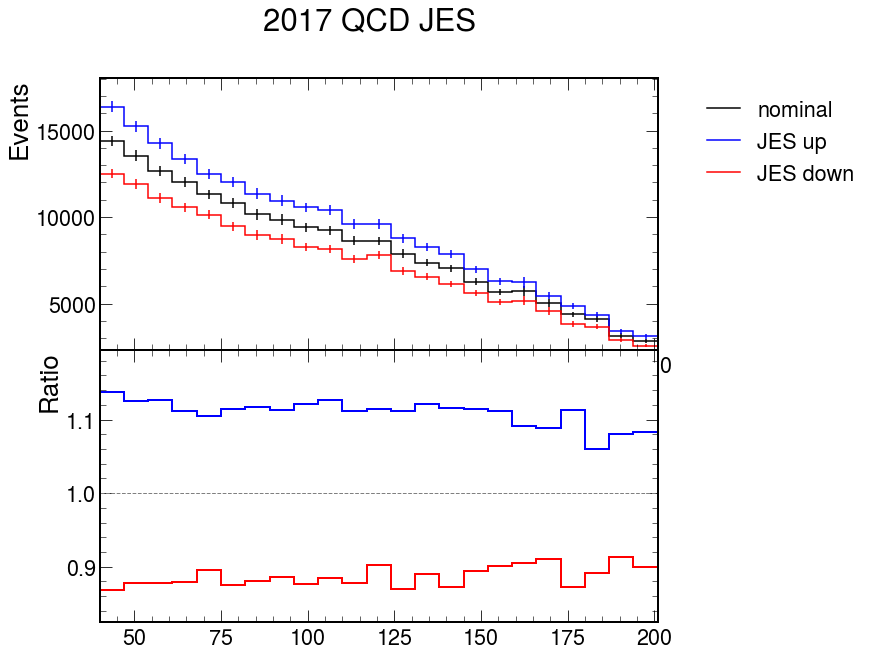

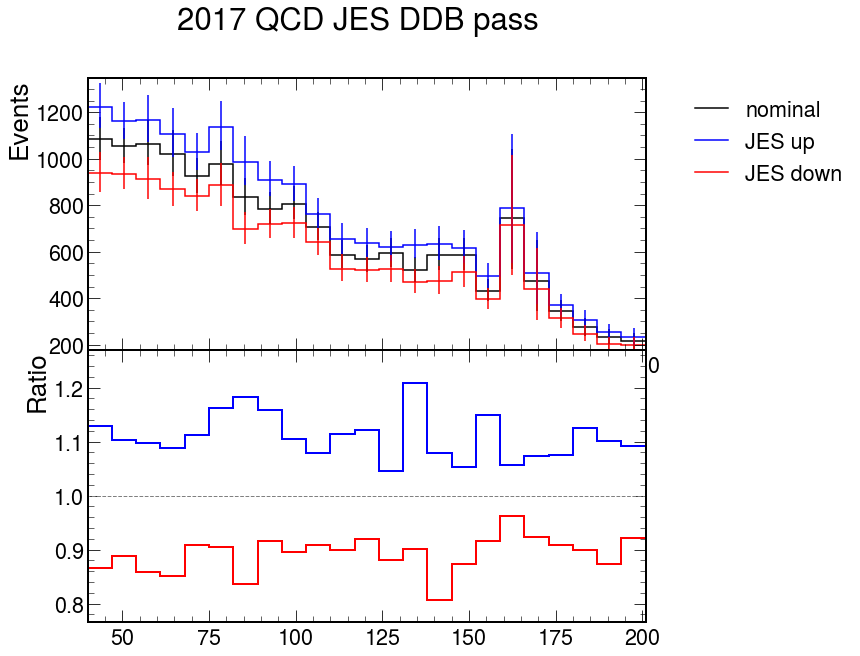

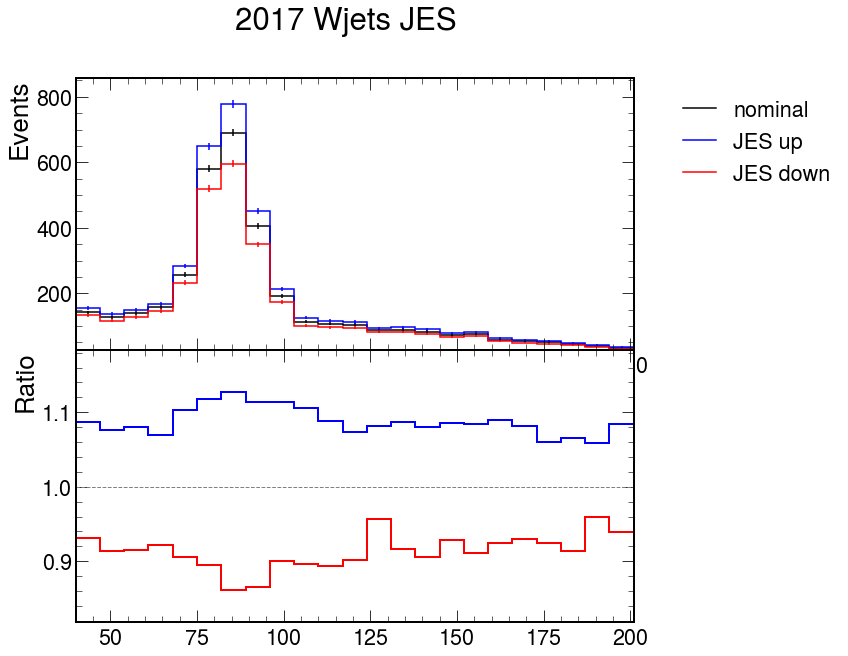

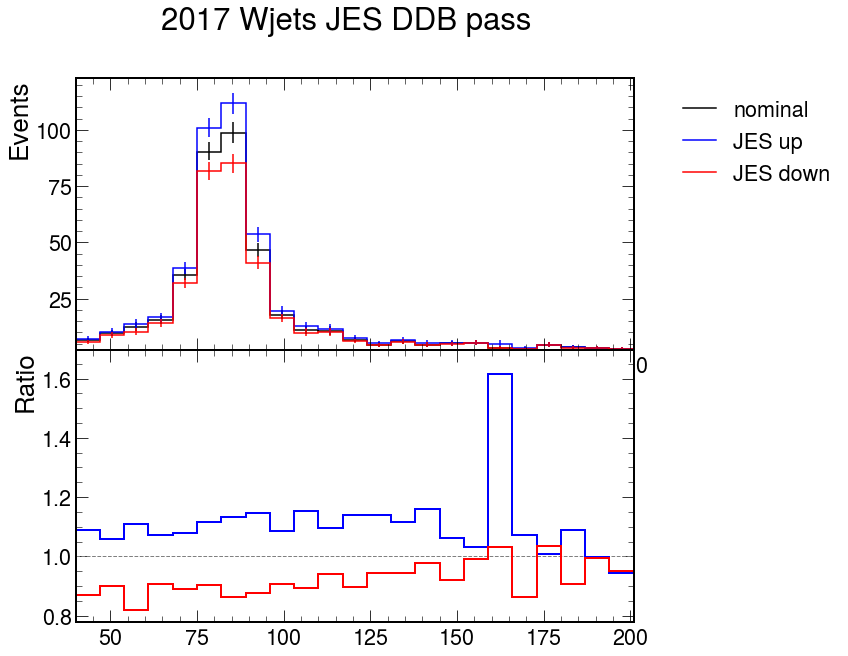

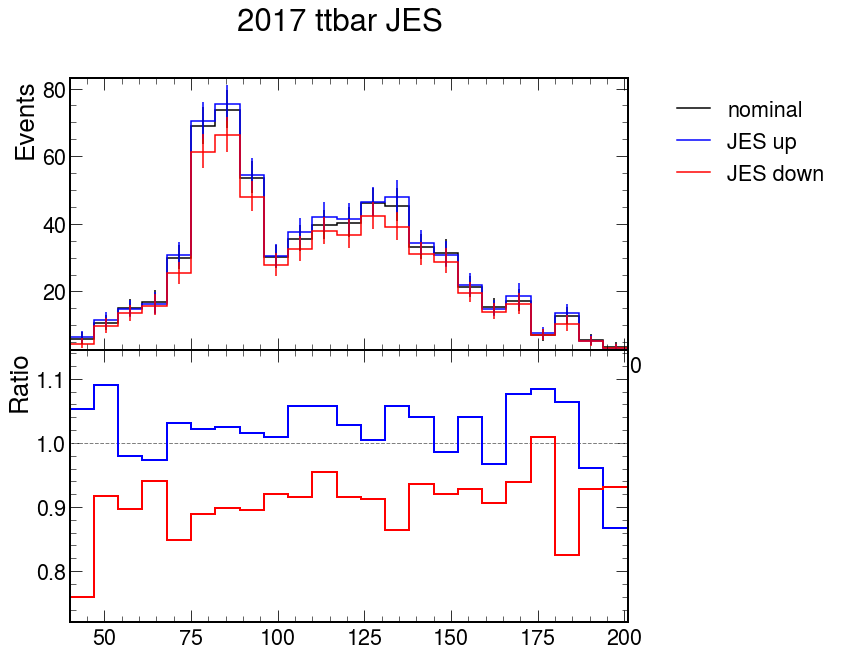

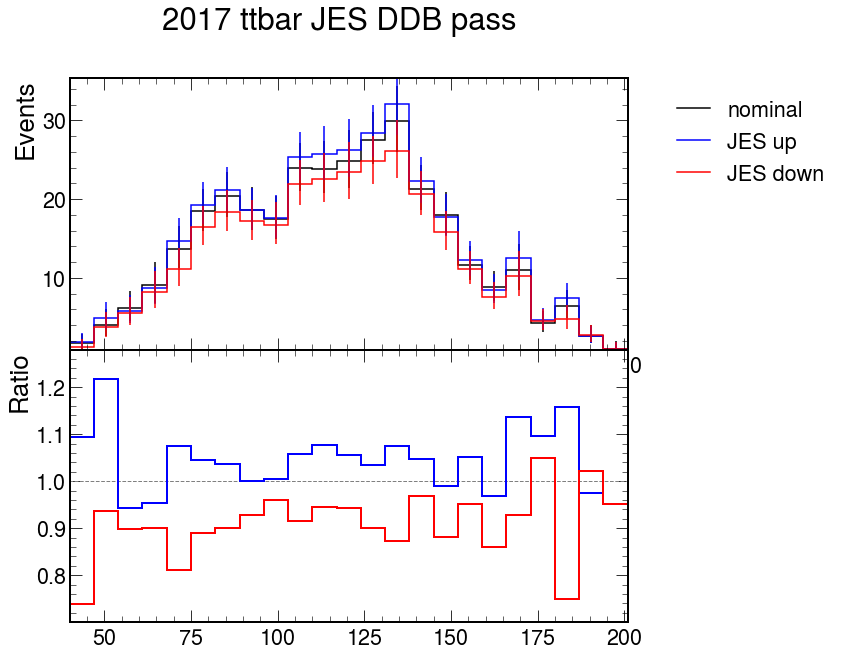

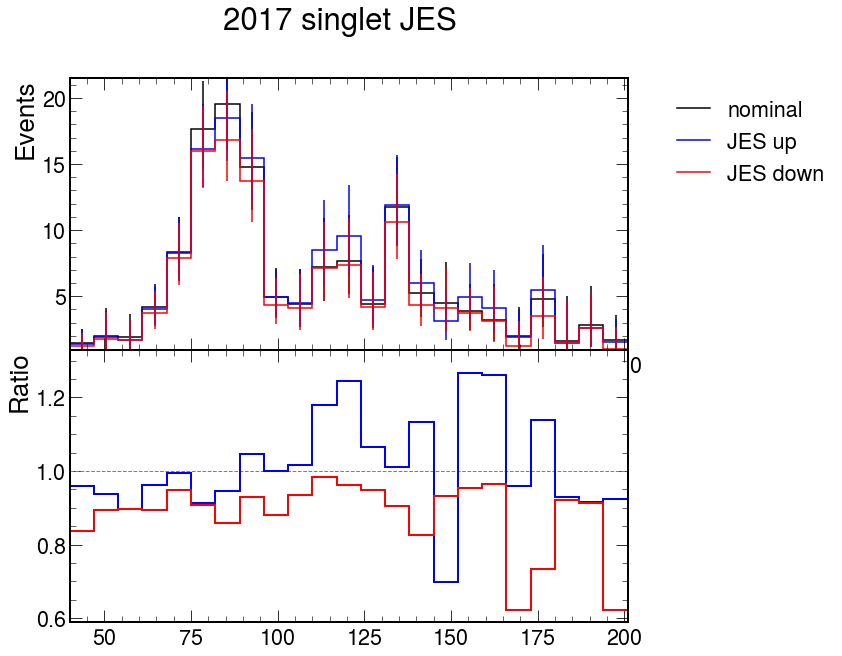

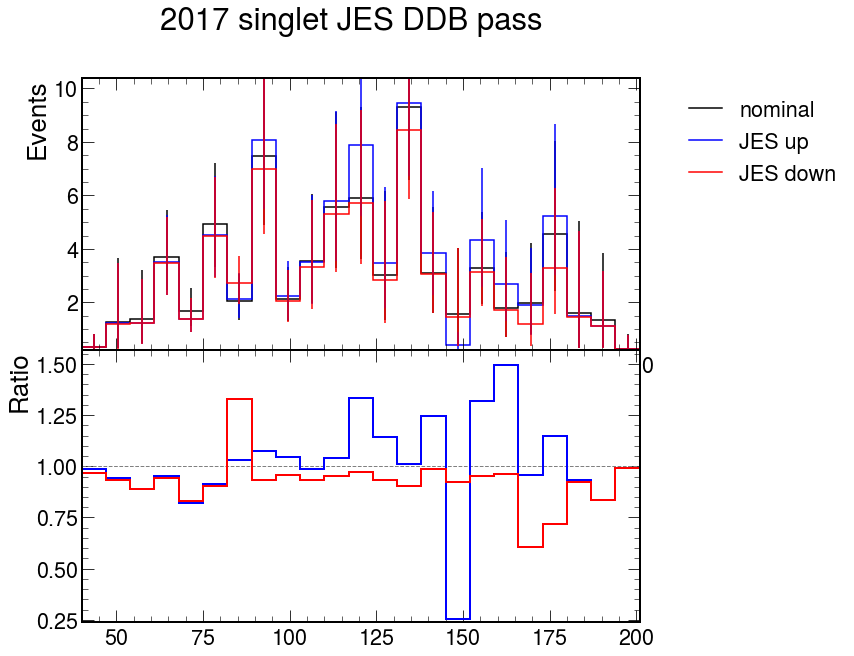

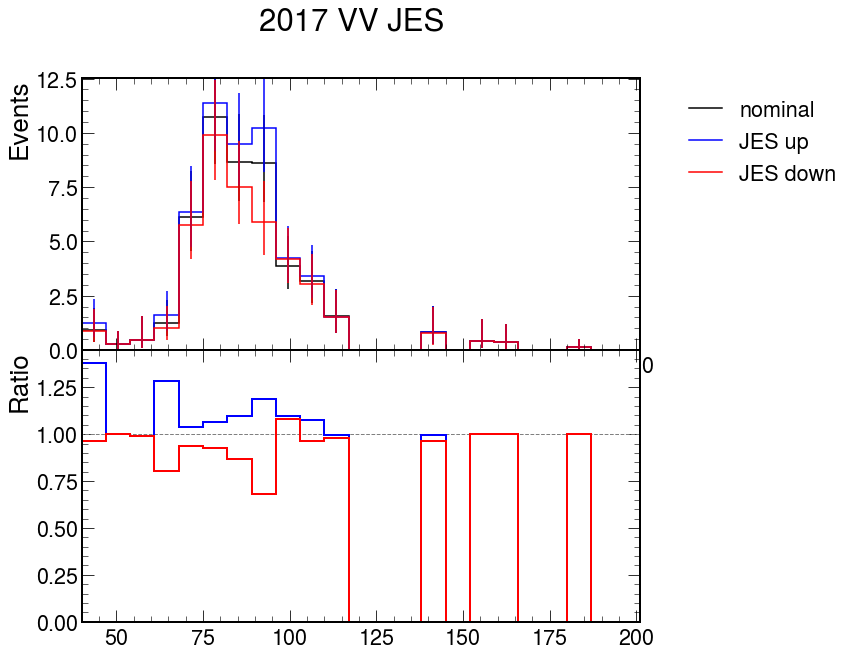

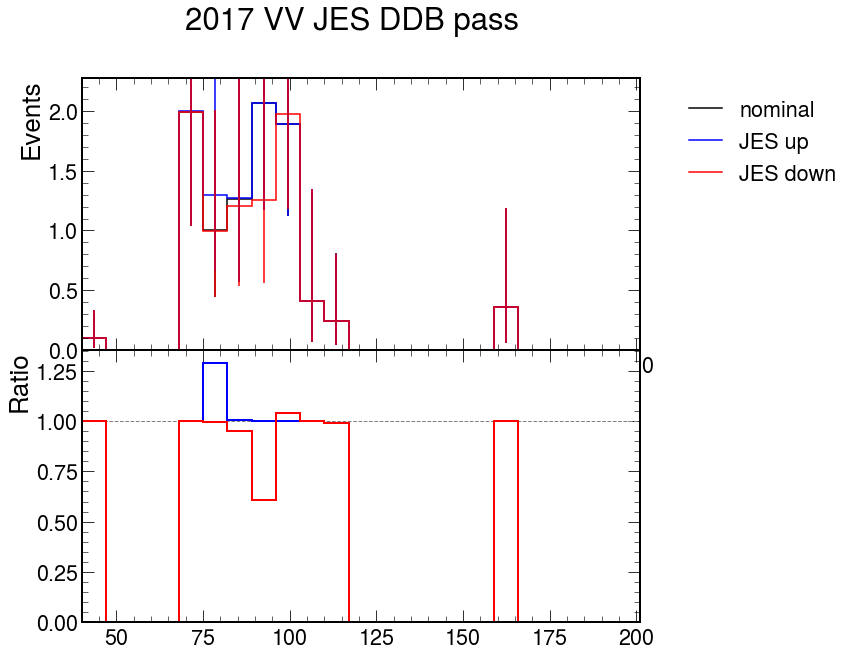

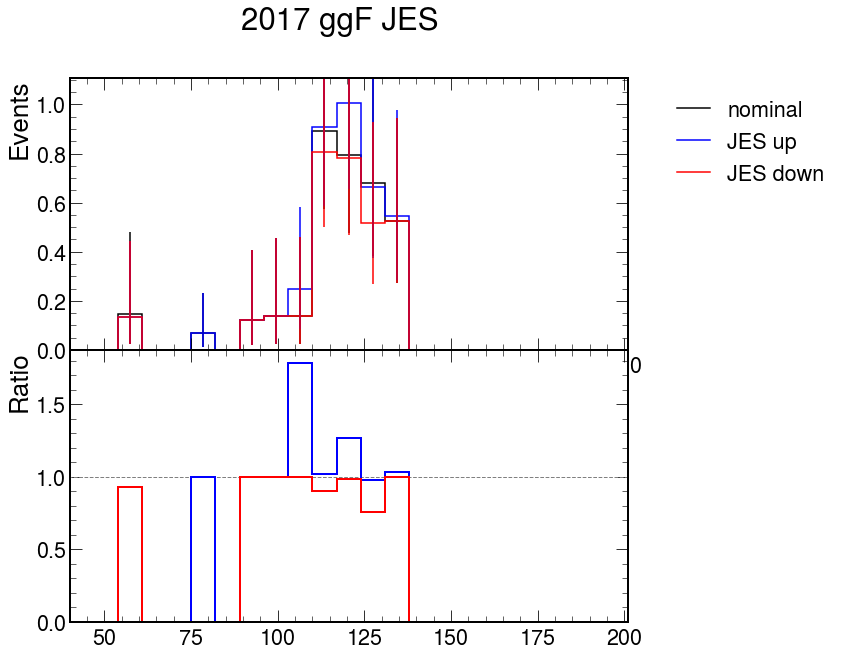

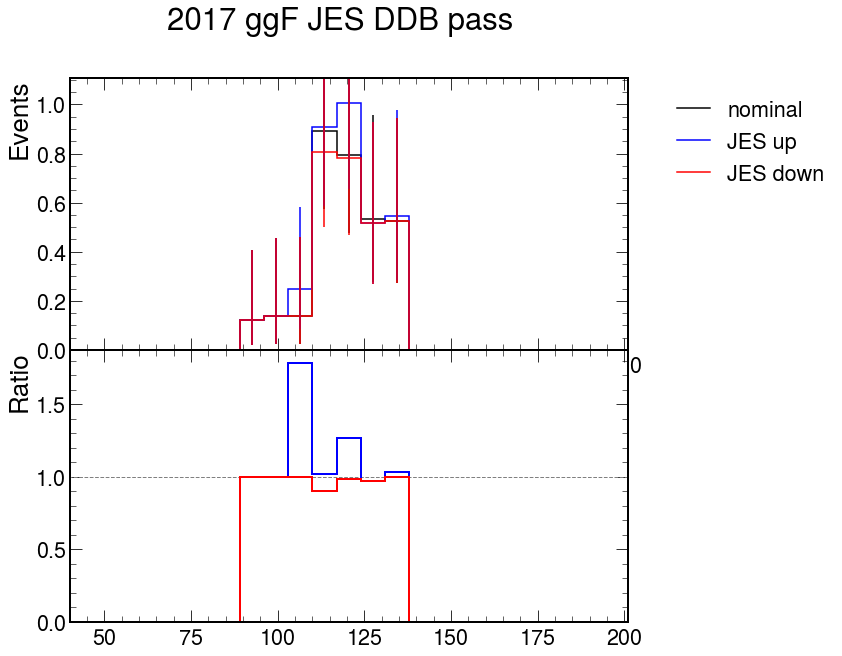

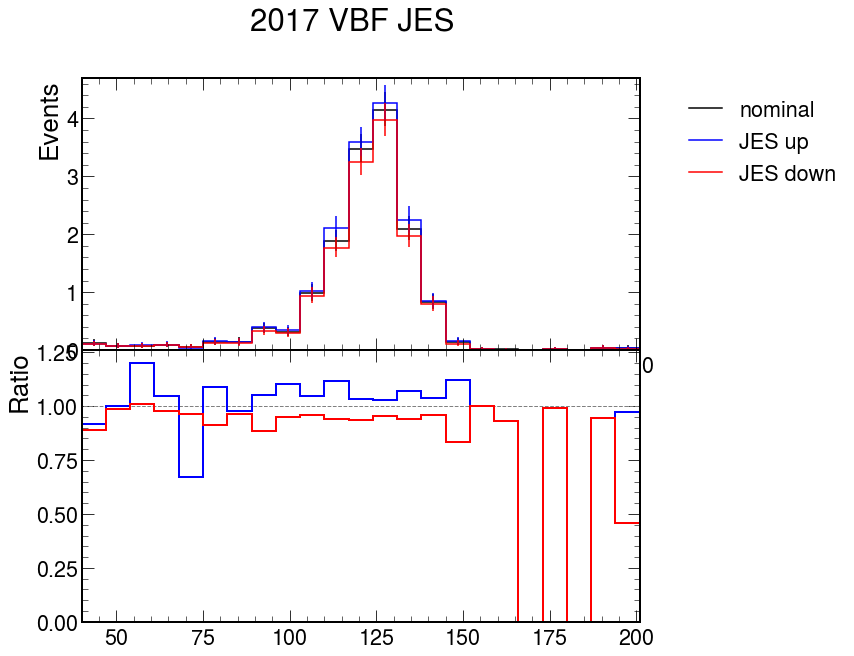

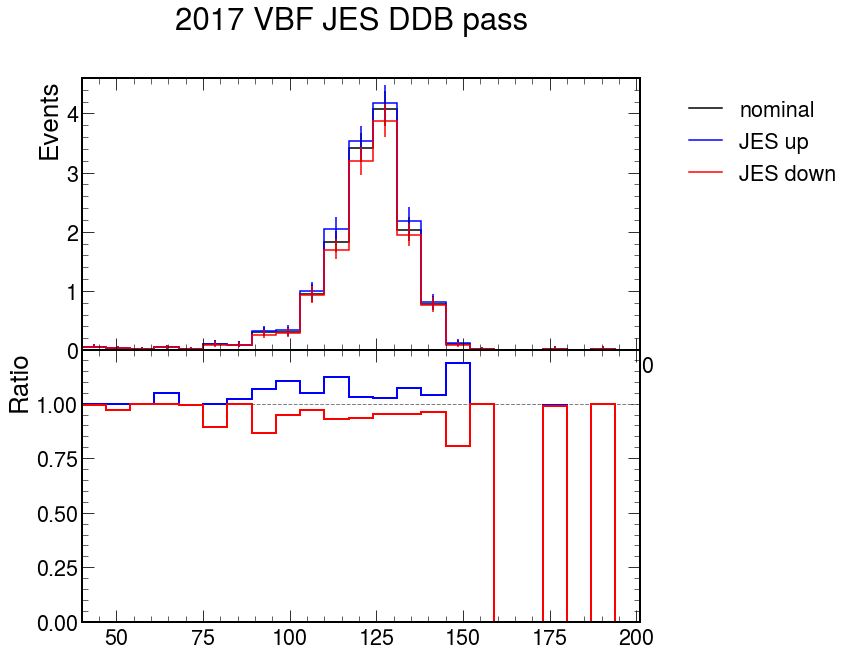

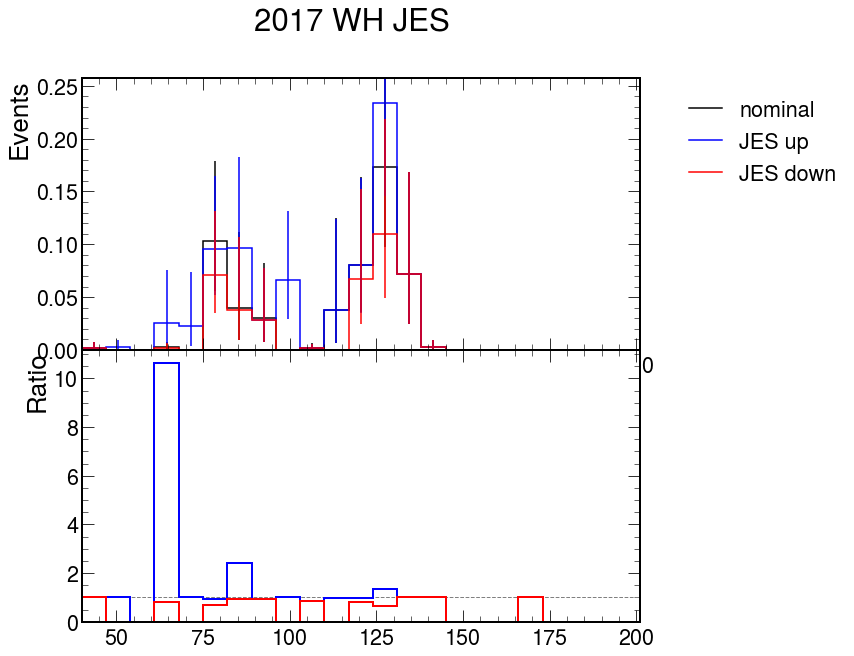

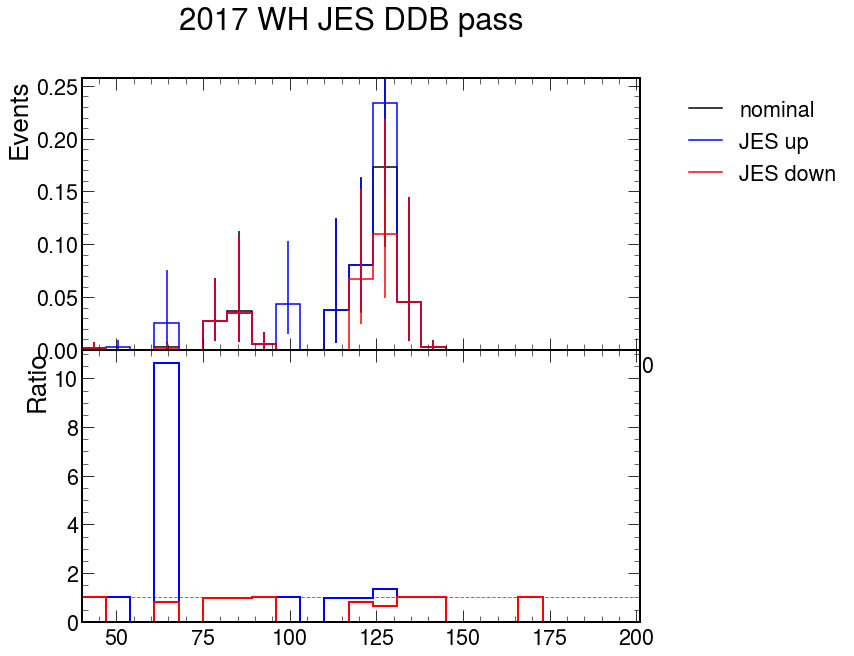

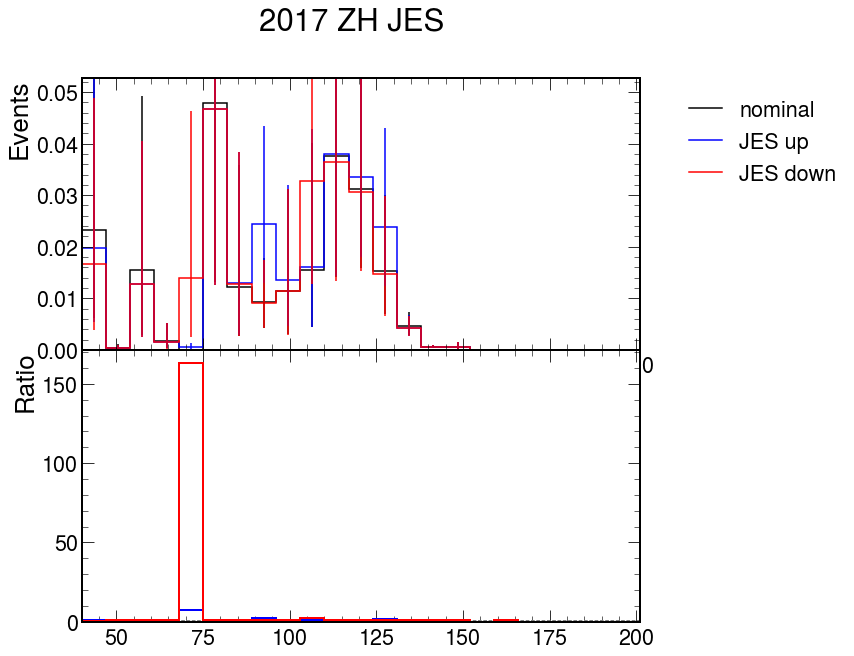

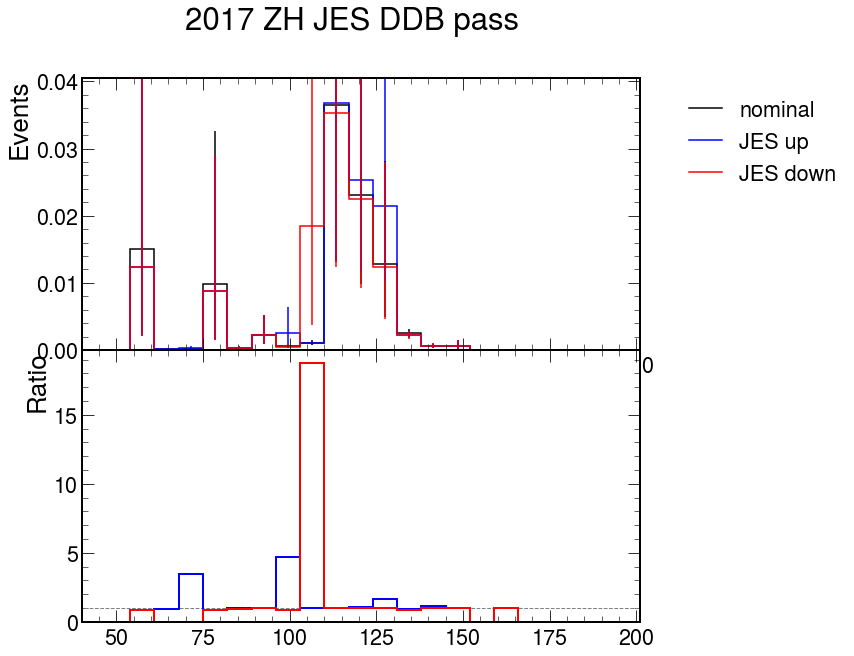

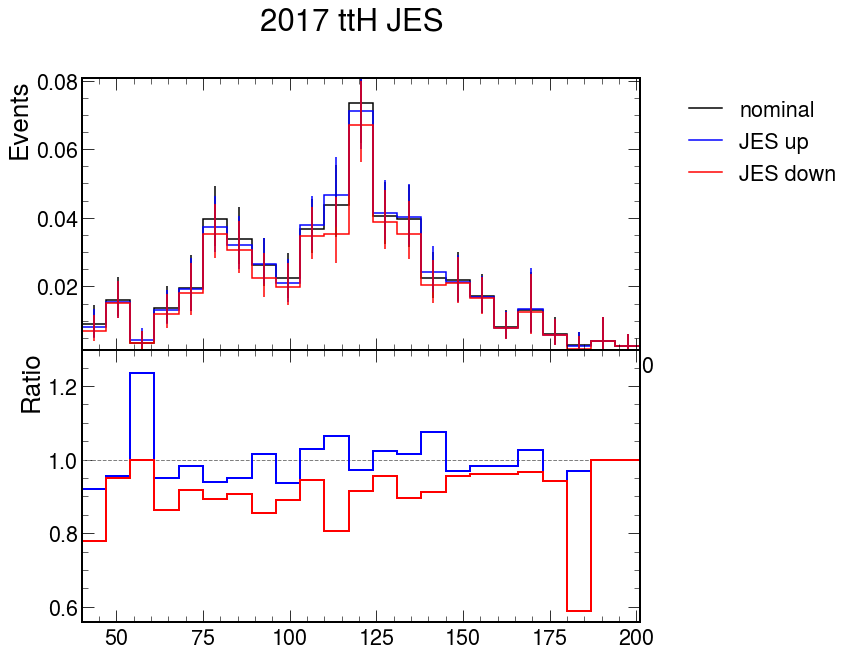

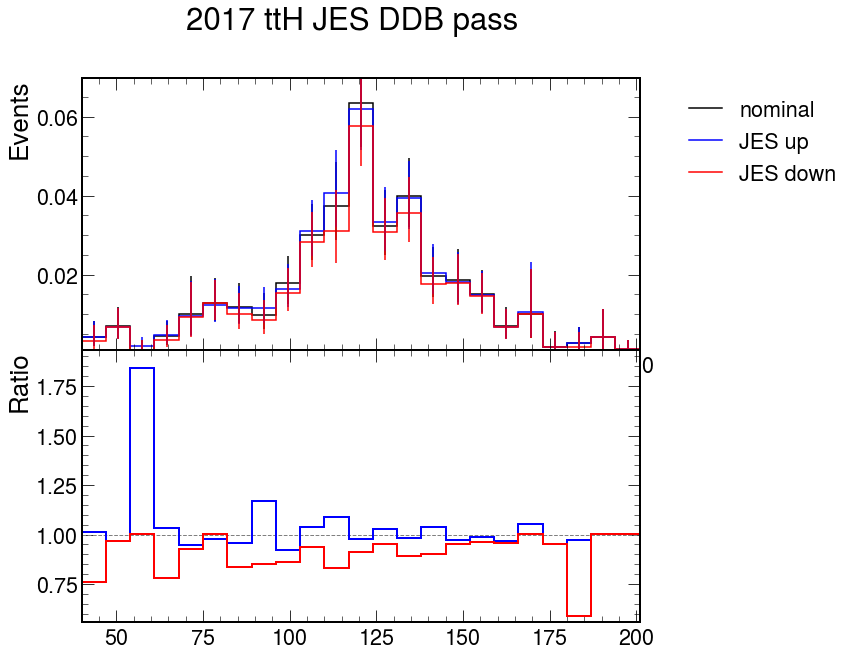

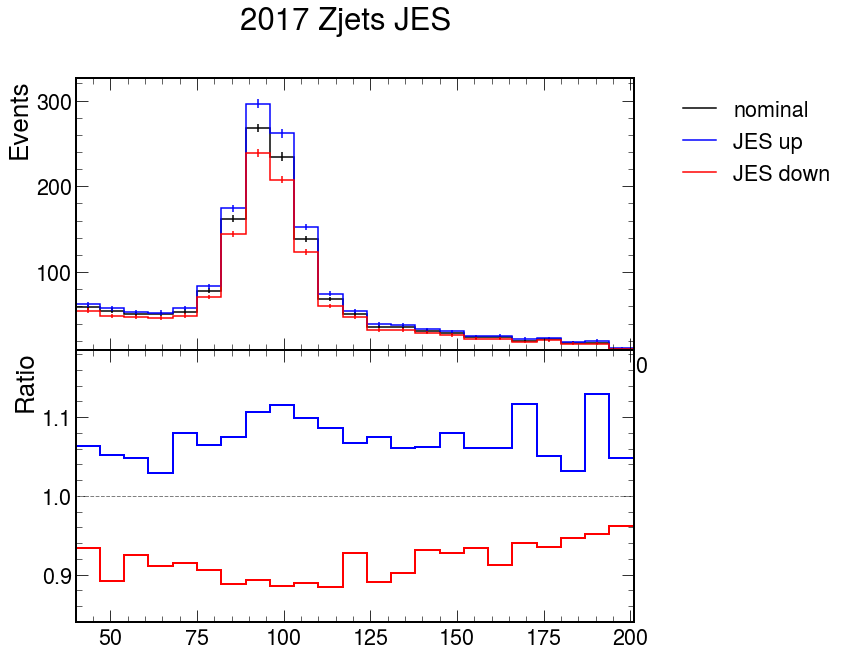

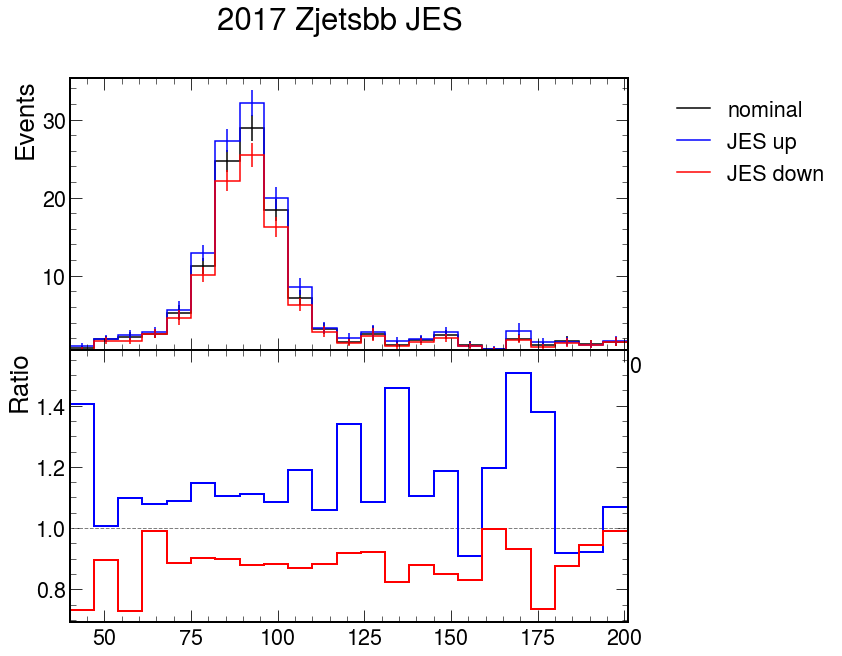

In [24]:
s = 'JES'

for p in mc:
    plot_syst(h.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s,year+'/syst_'+s+'/'+p)
    plot_syst(g.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s+' DDB pass',year+'/syst_'+s+'/'+p+"_pass")
    
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(0,3)),s,year+' Zjets '+s,year+'/syst_'+s+'/Zjets')
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(3,4)),s,year+' Zjetsbb '+s,year+'/syst_'+s+'/Zjetsbb')

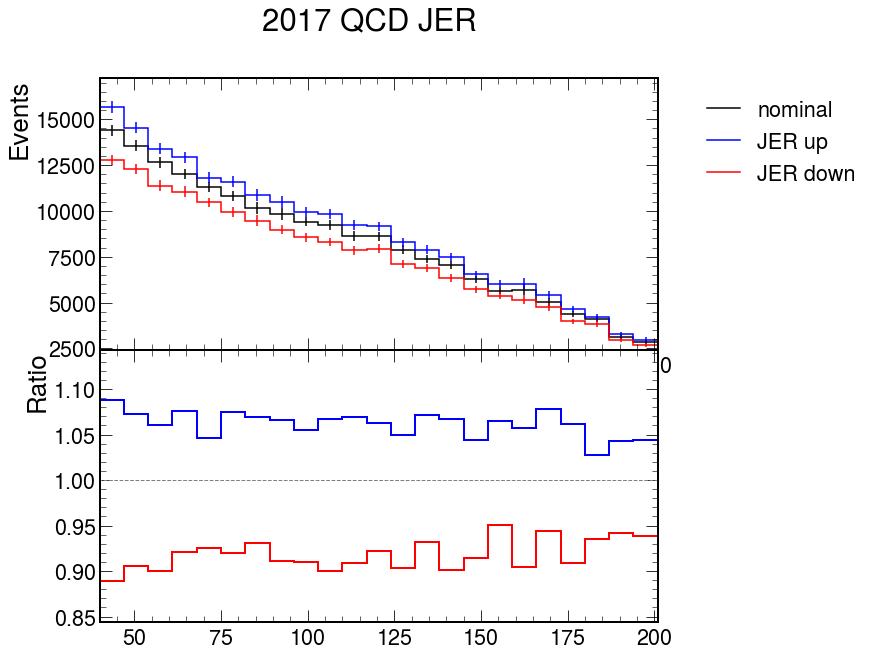

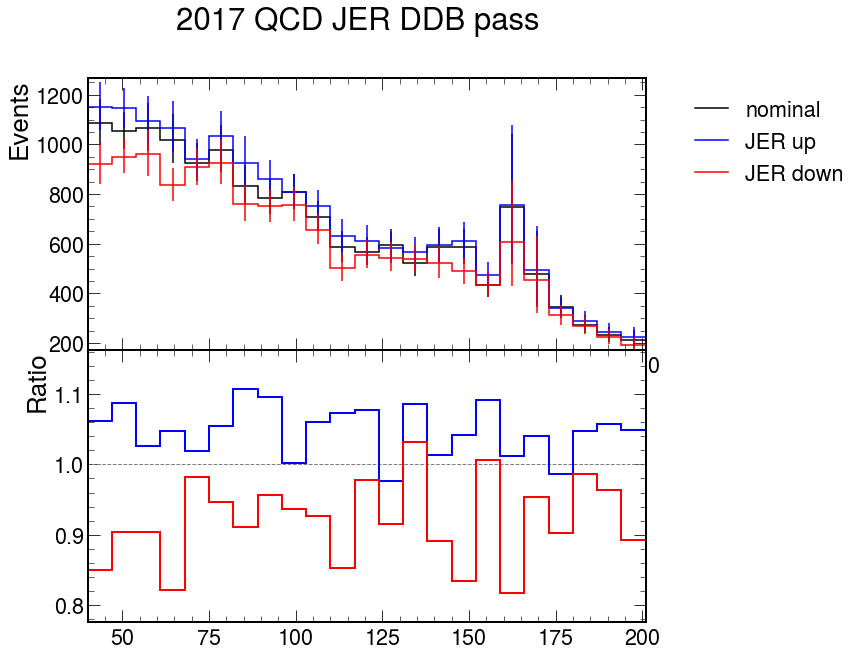

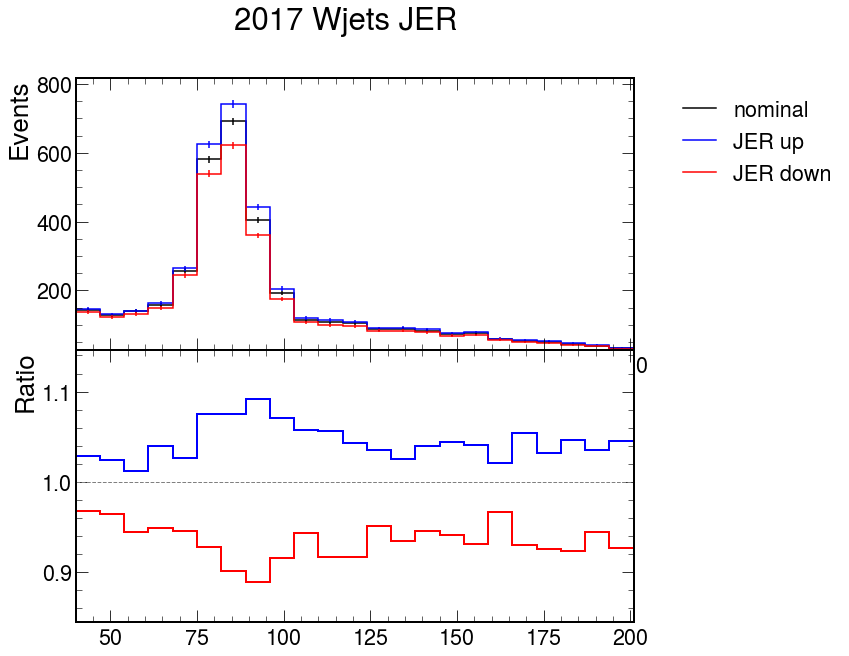

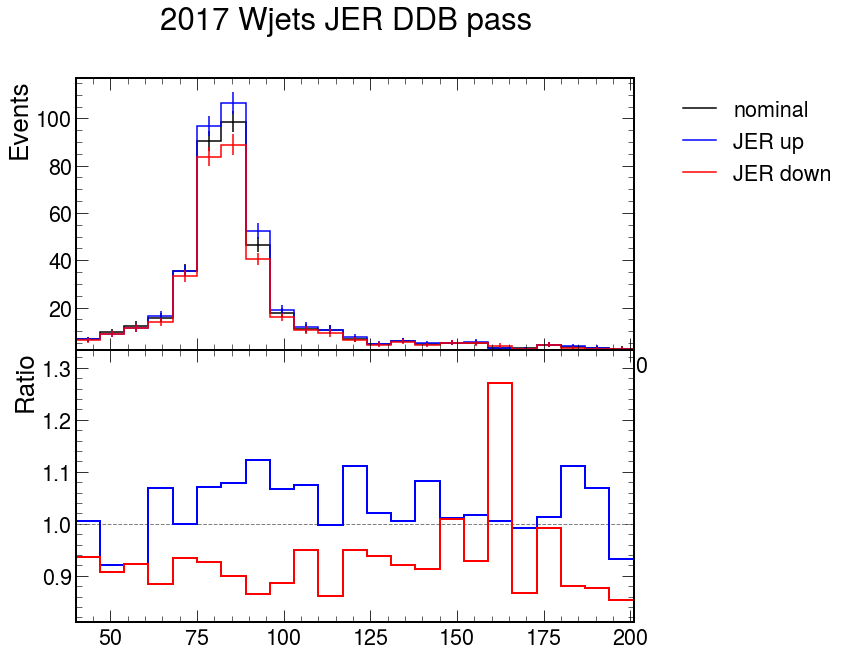

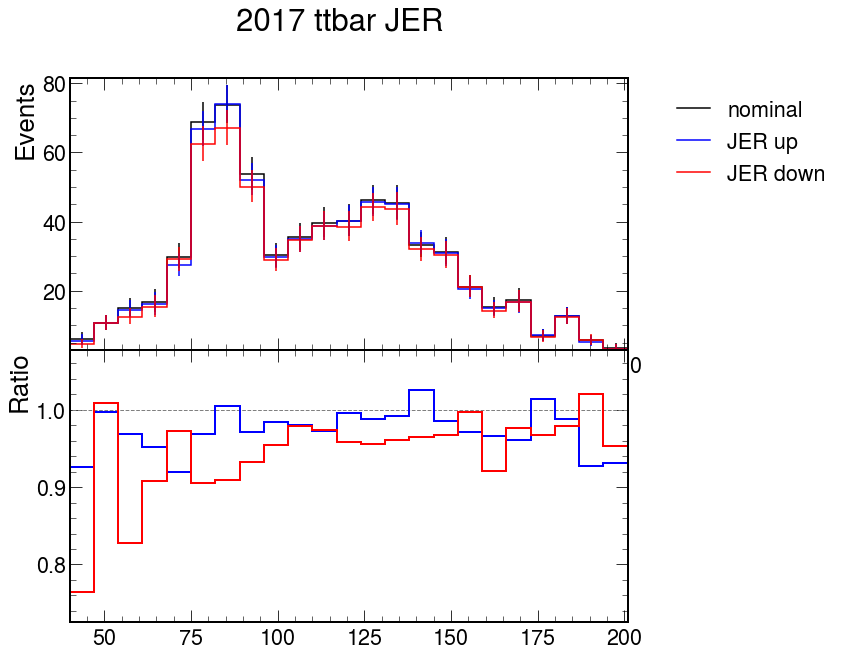

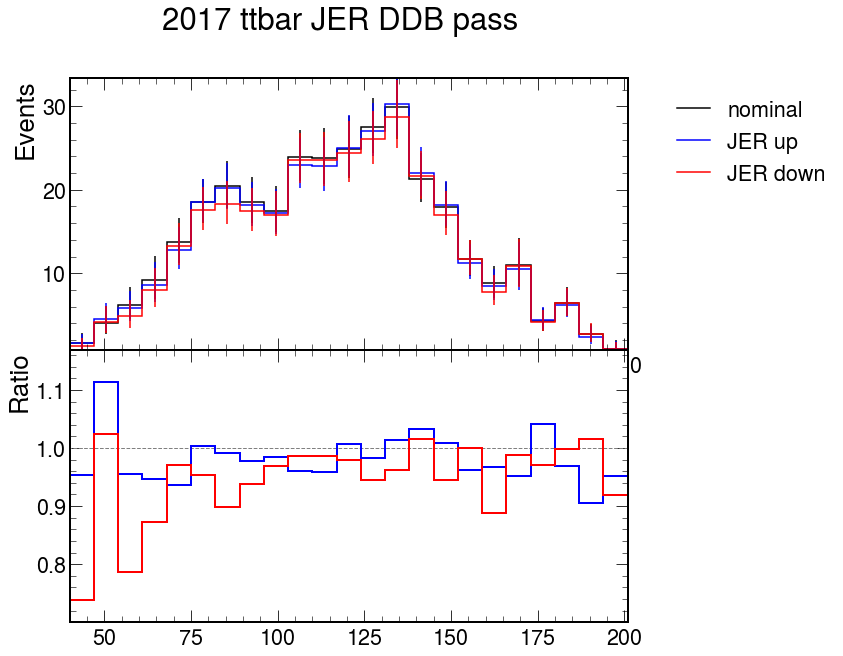

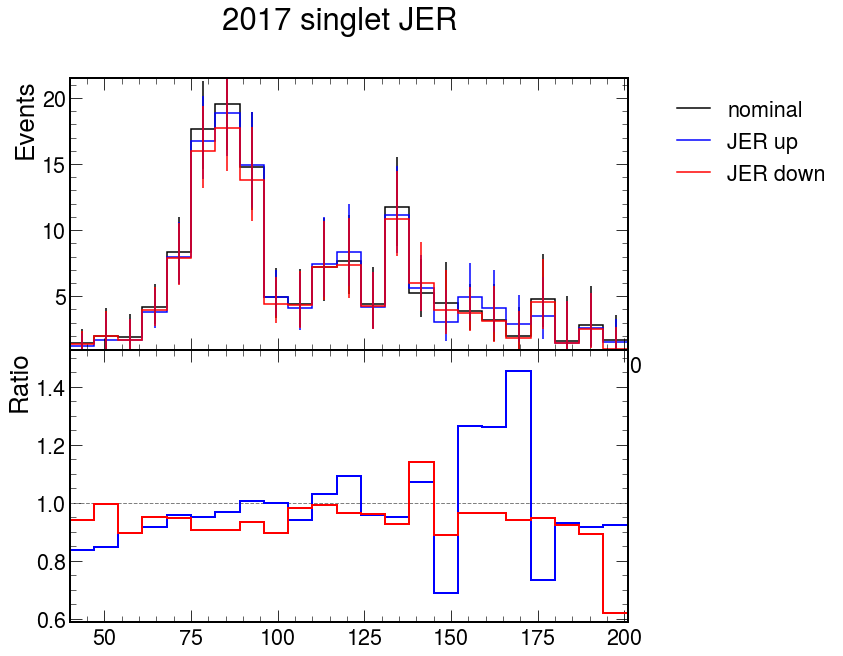

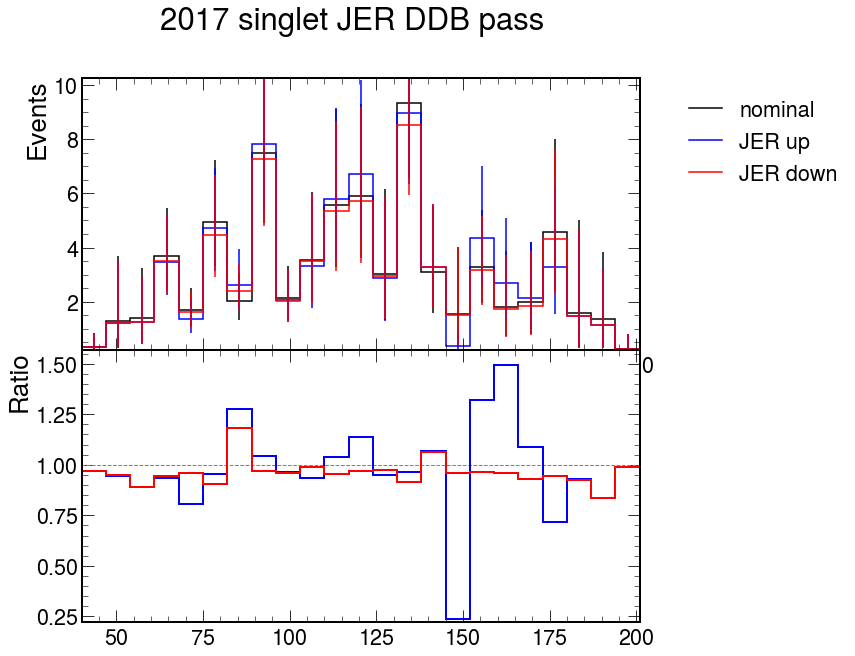

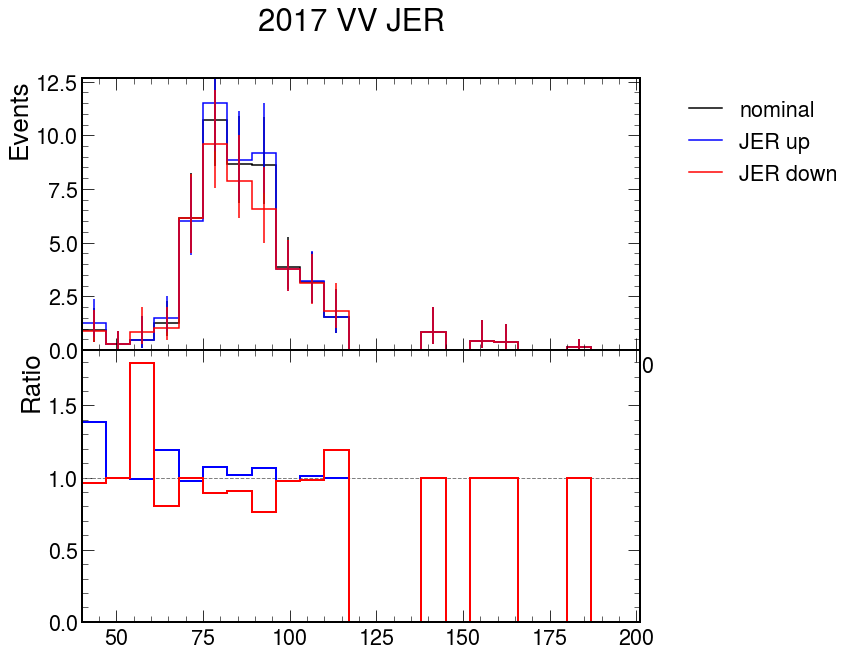

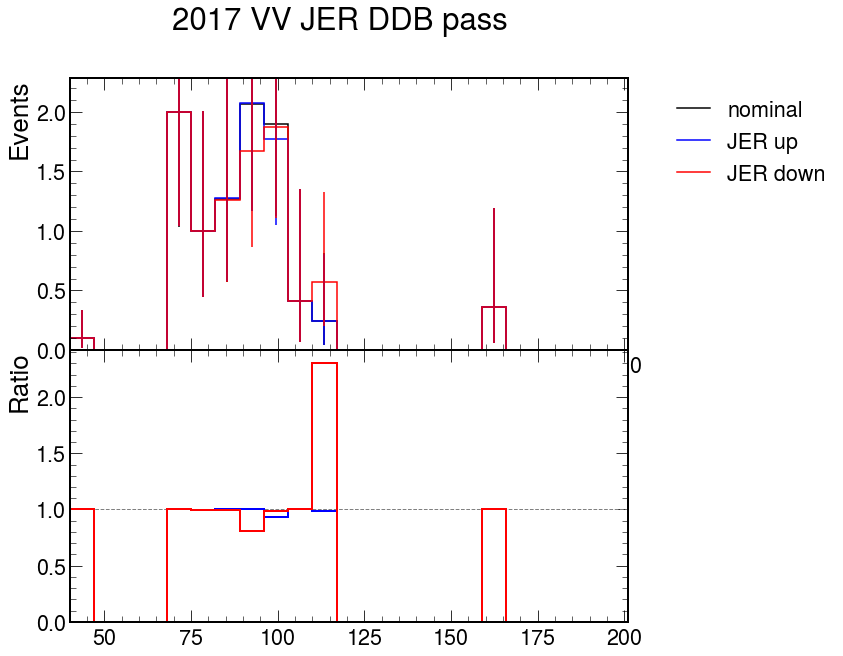

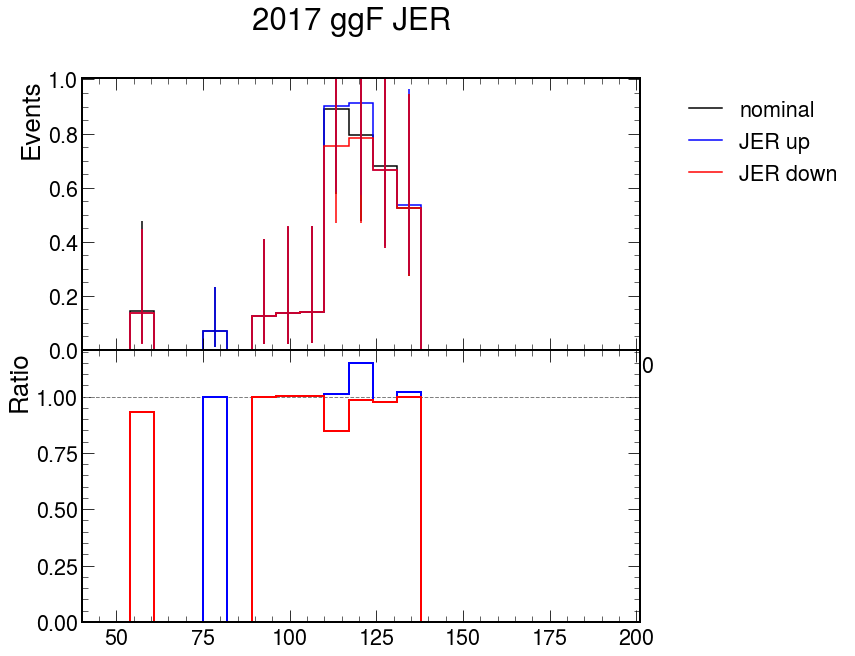

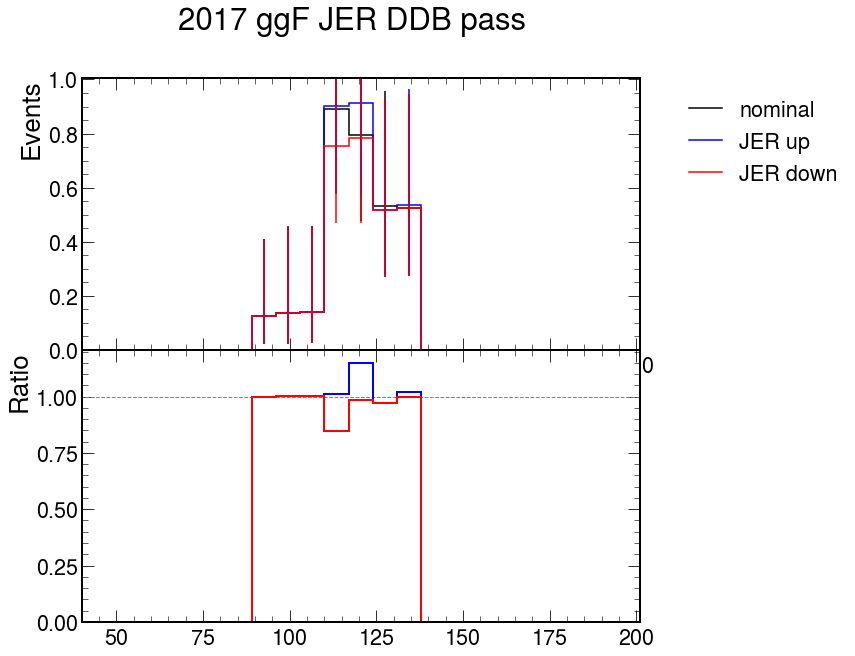

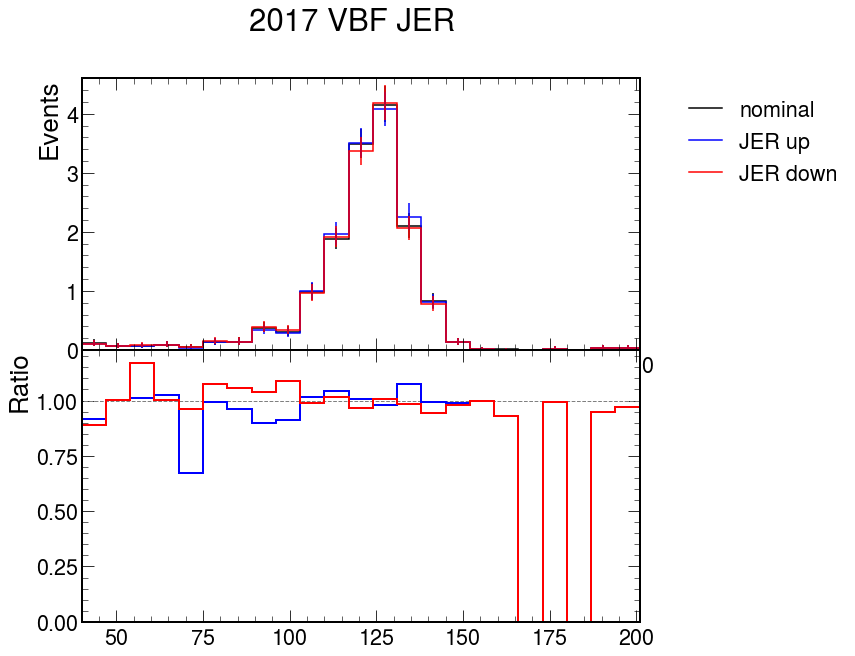

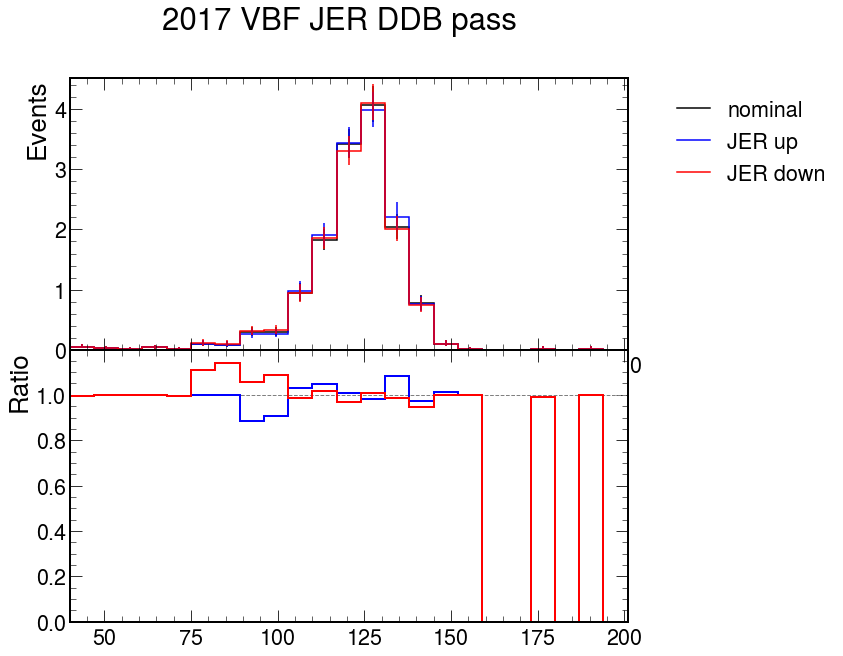

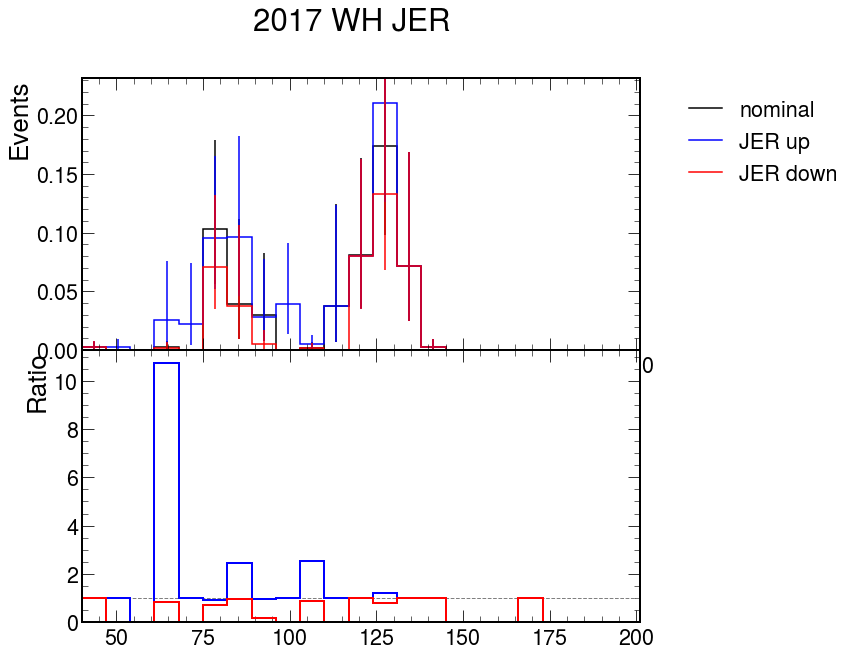

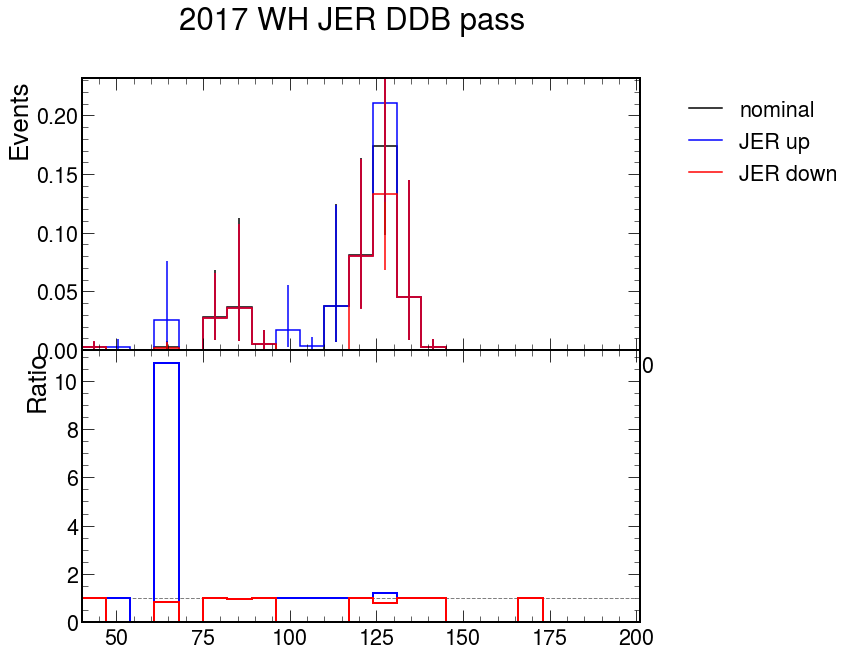

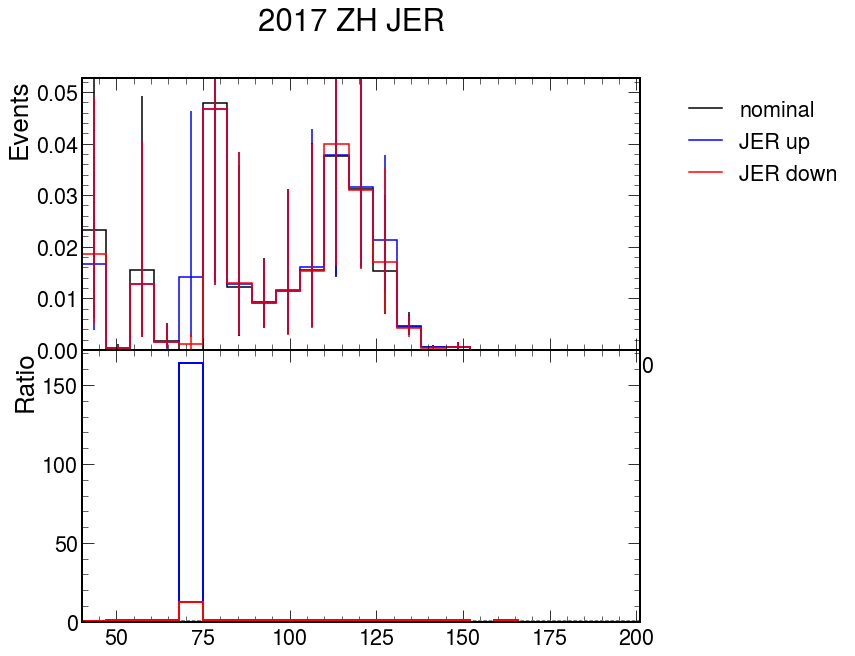

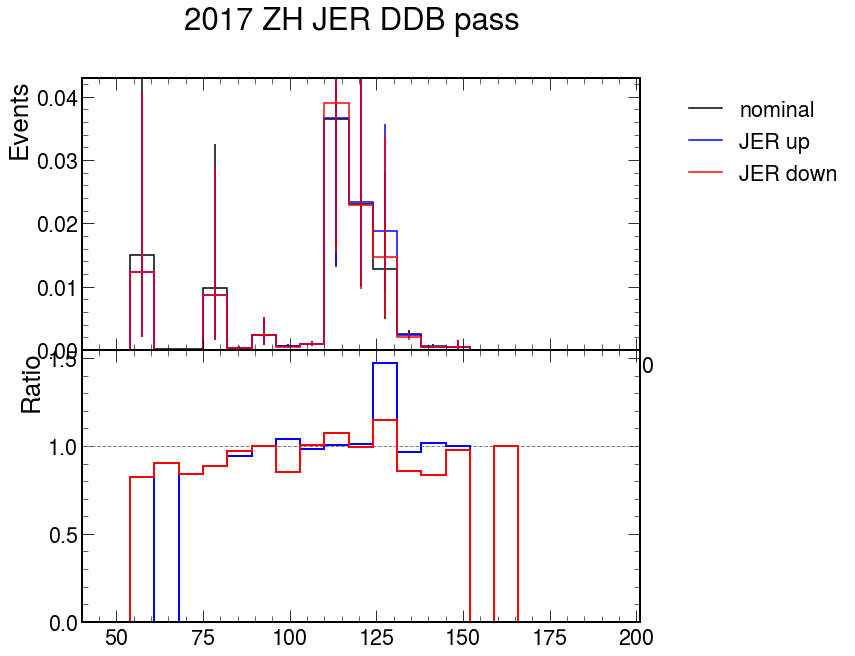

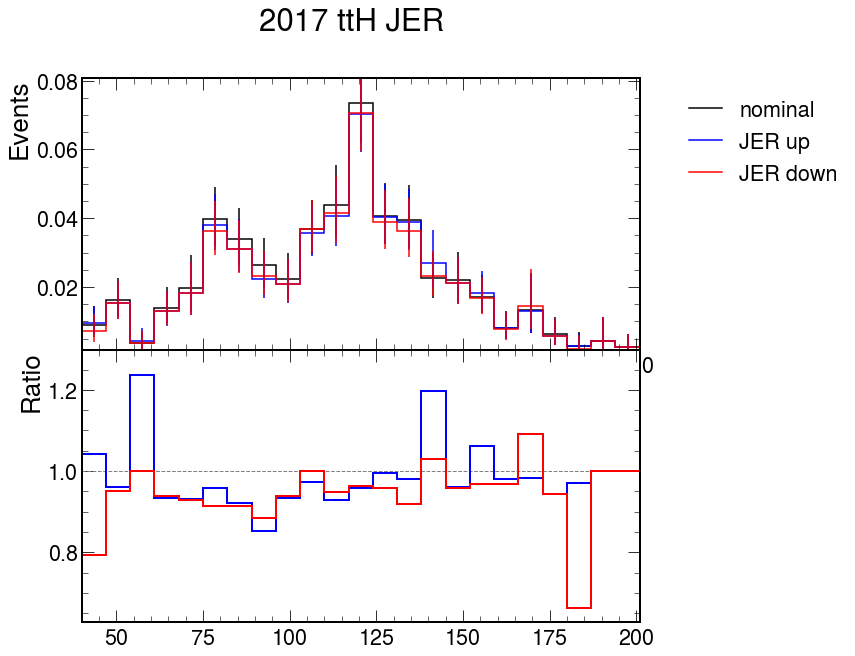

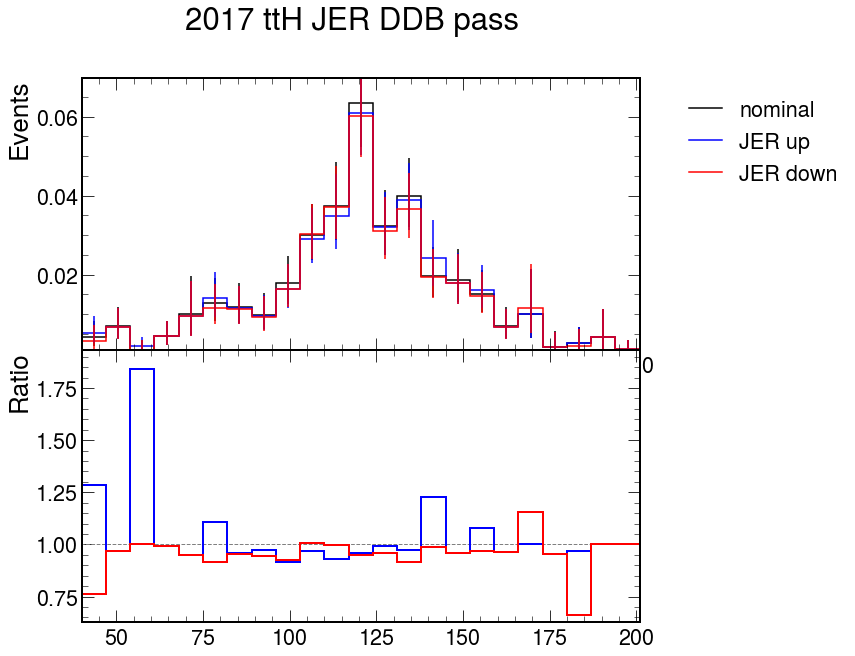

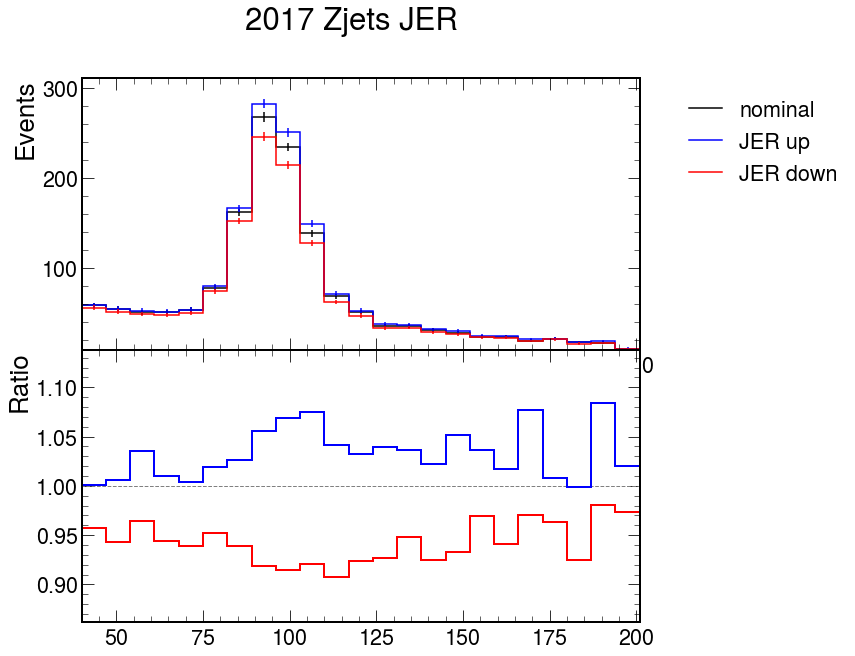

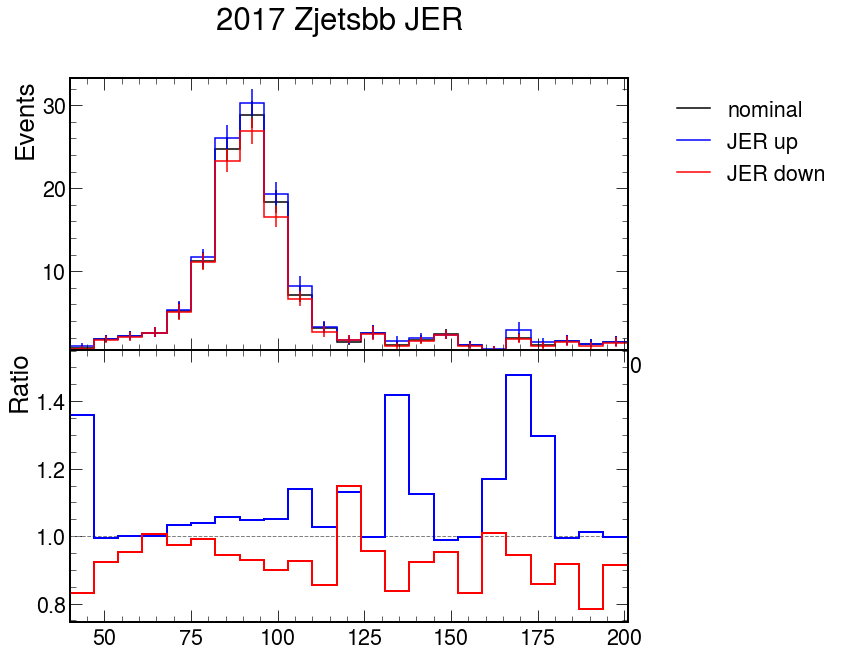

In [25]:
s = 'JER'

for p in mc:
    plot_syst(h.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s,year+'/syst_'+s+'/'+p)
    plot_syst(g.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s+' DDB pass',year+'/syst_'+s+'/'+p+"_pass")
    
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(0,3)),s,year+' Zjets '+s,year+'/syst_'+s+'/Zjets')
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(3,4)),s,year+' Zjetsbb '+s,year+'/syst_'+s+'/Zjetsbb')

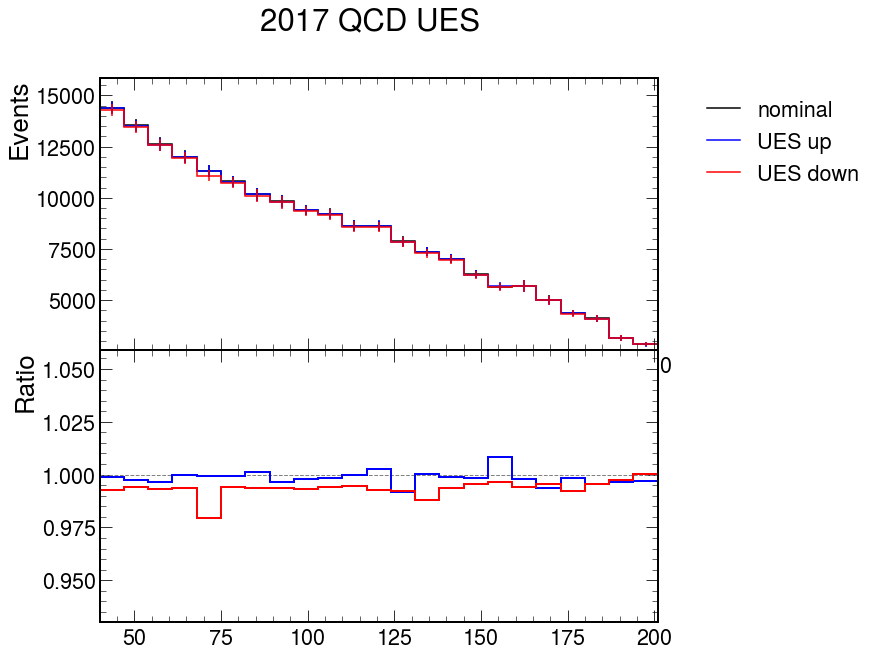

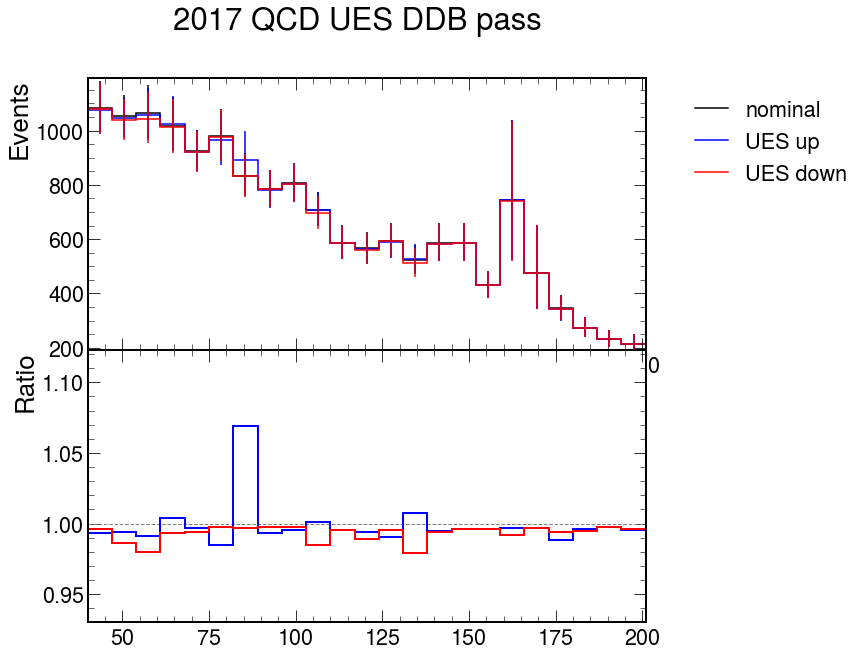

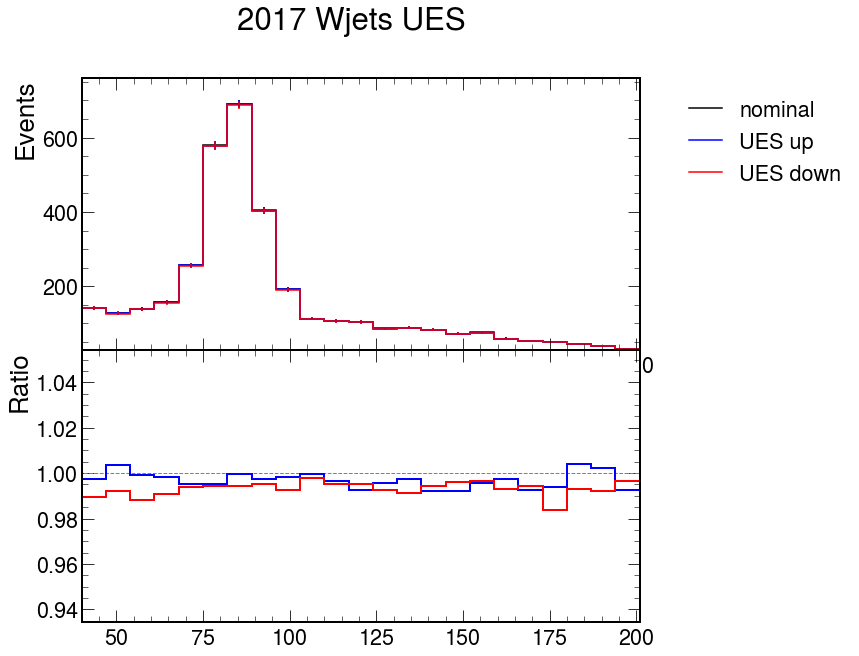

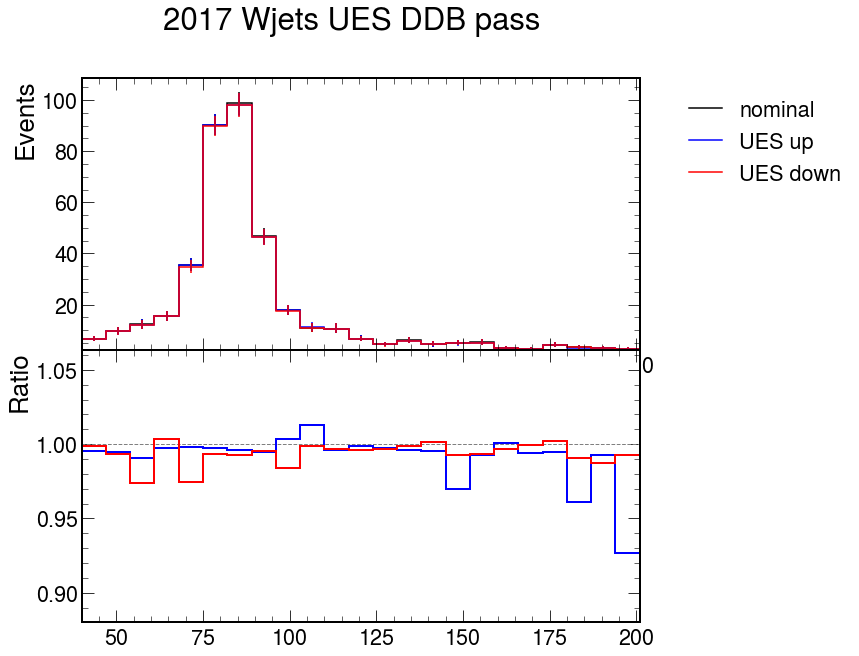

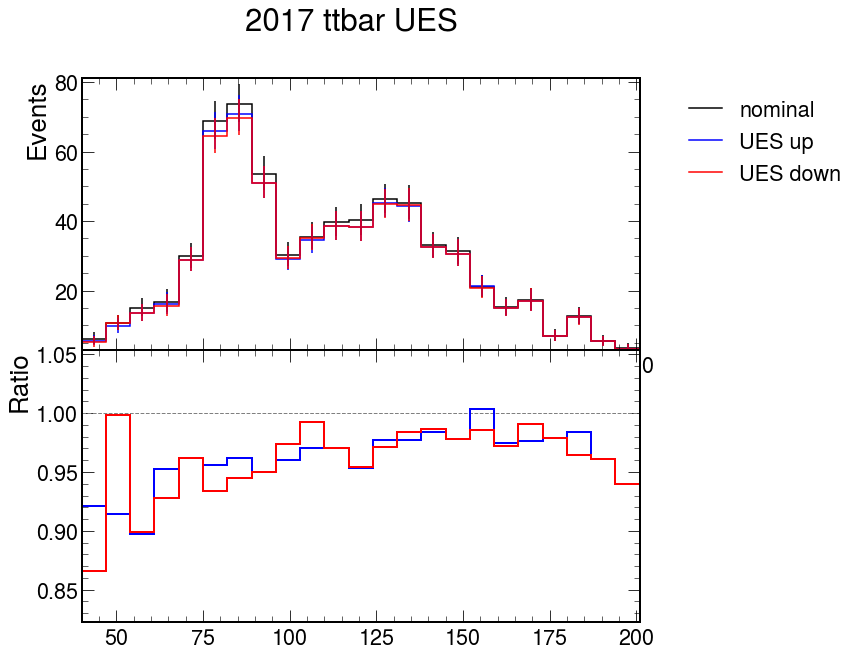

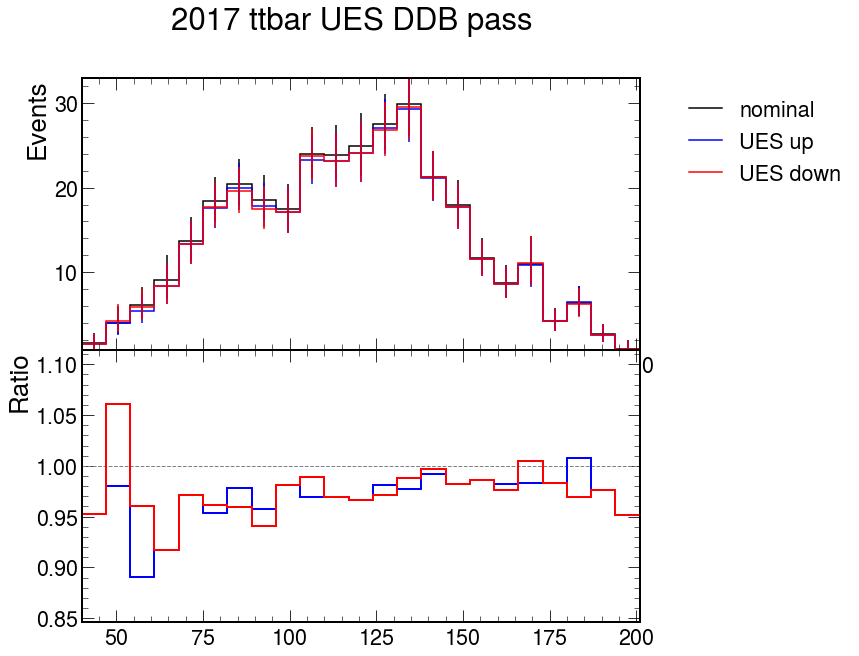

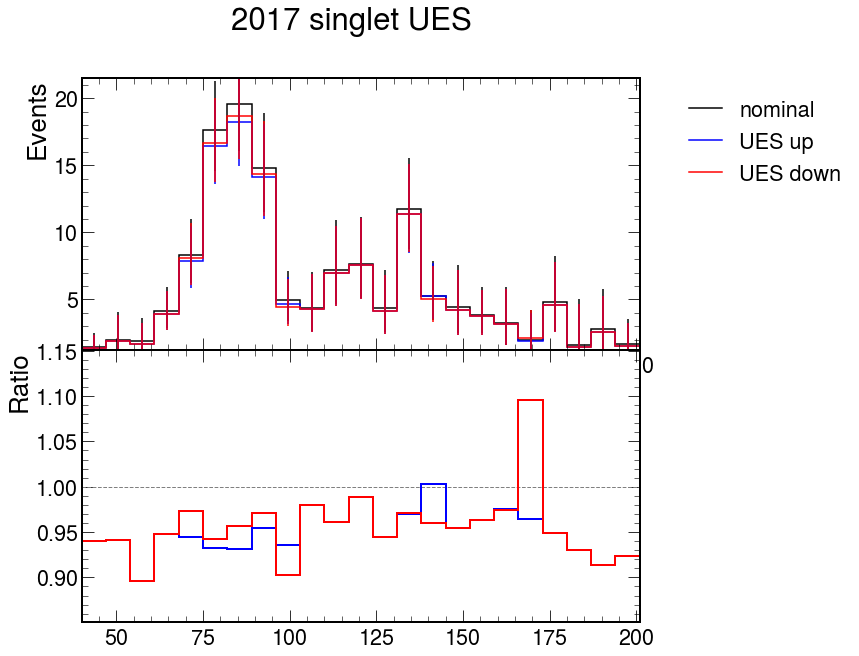

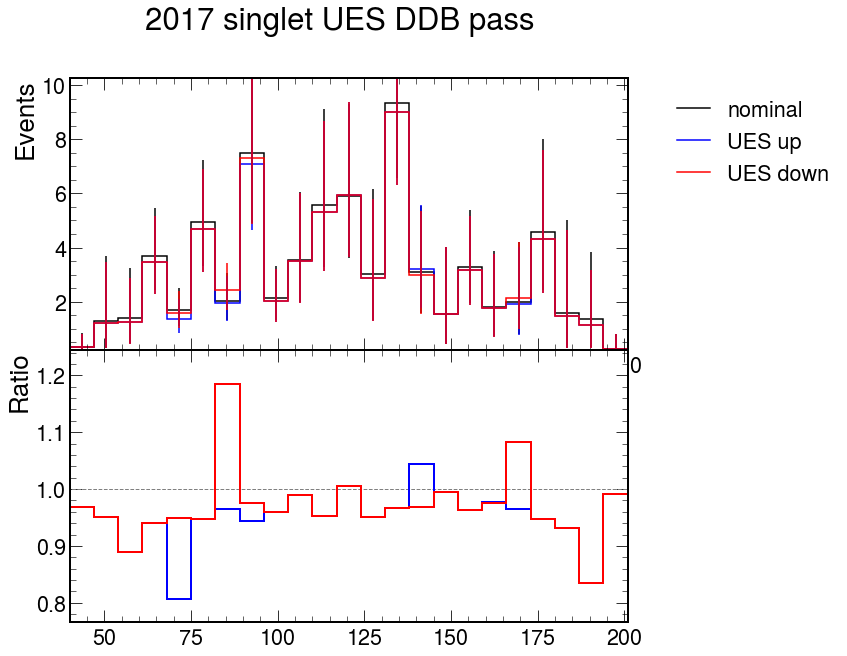

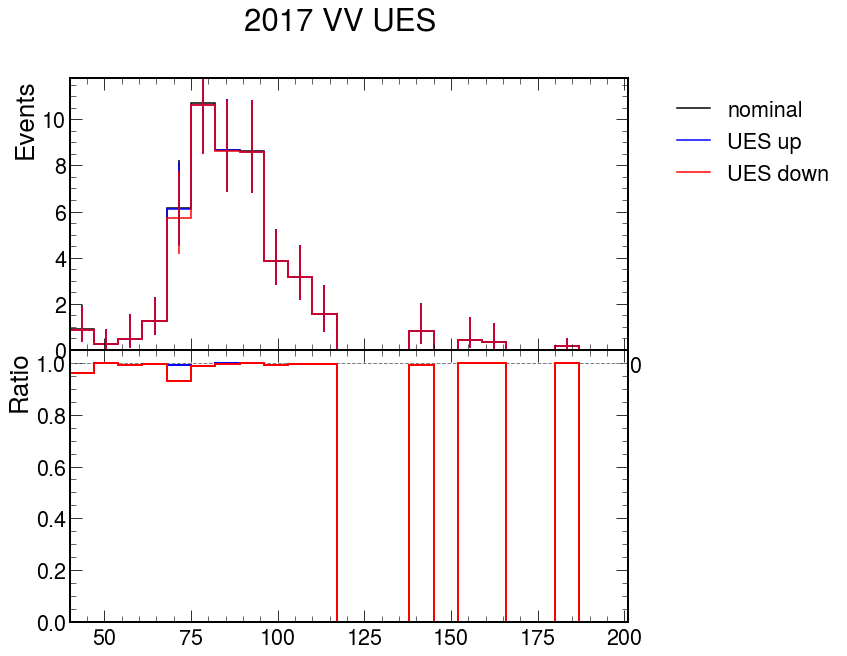

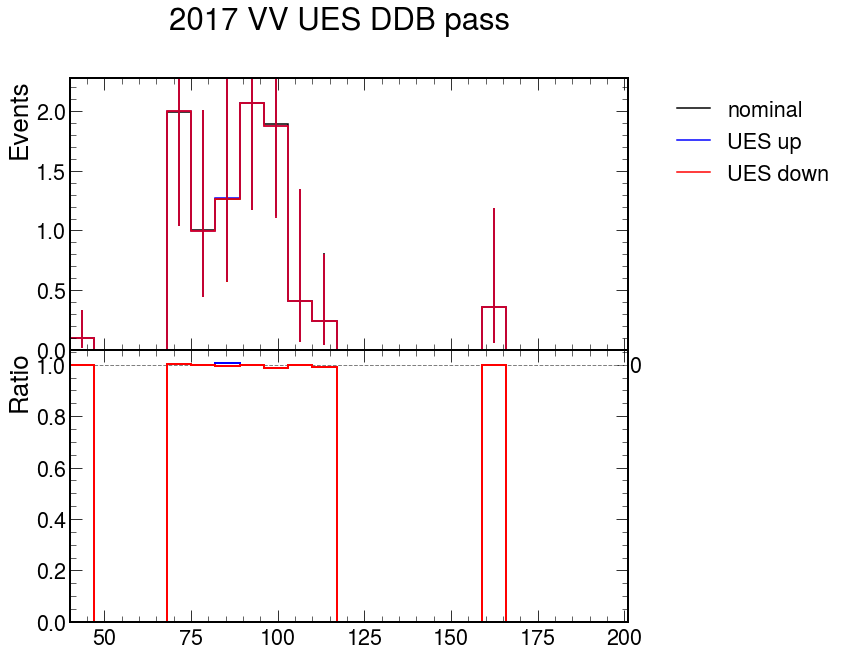

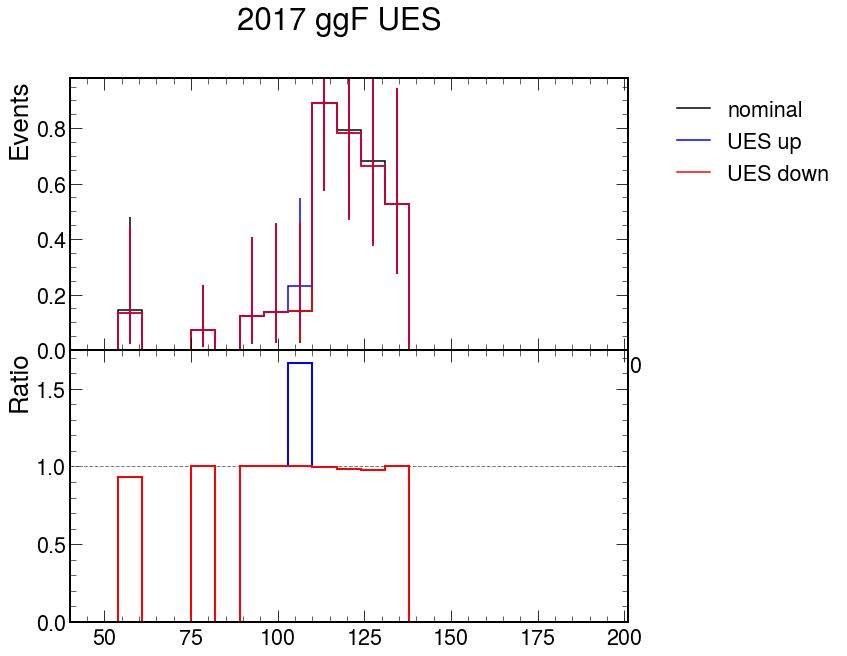

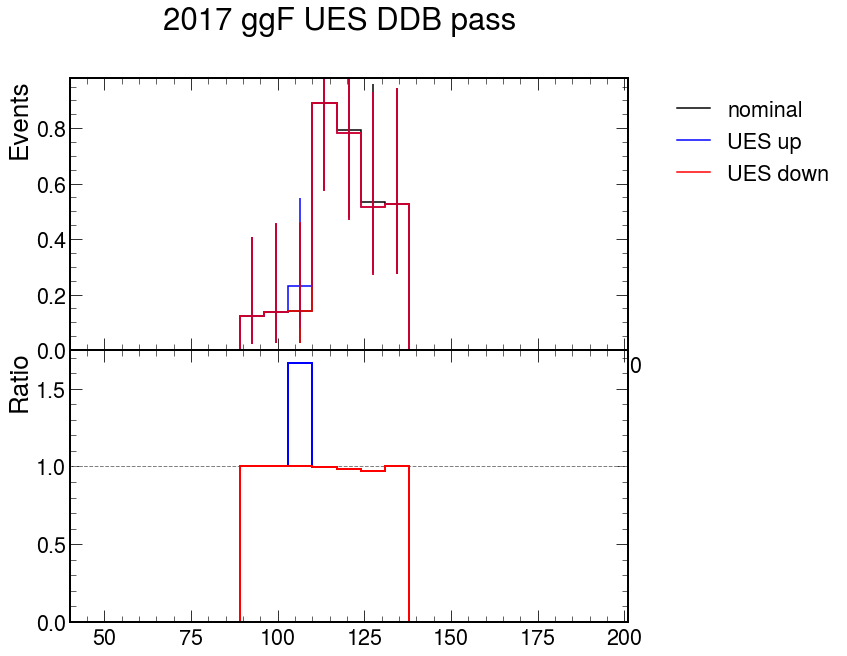

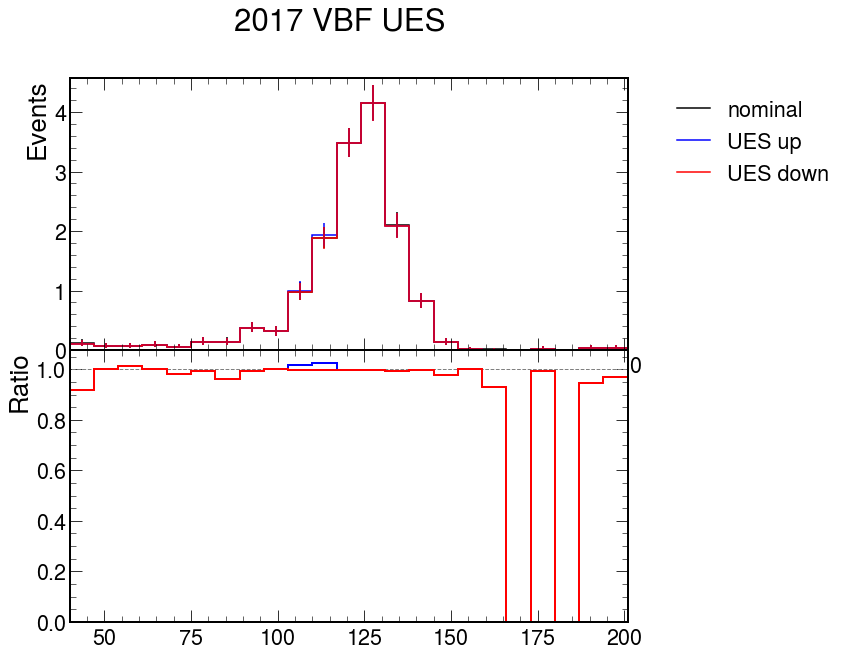

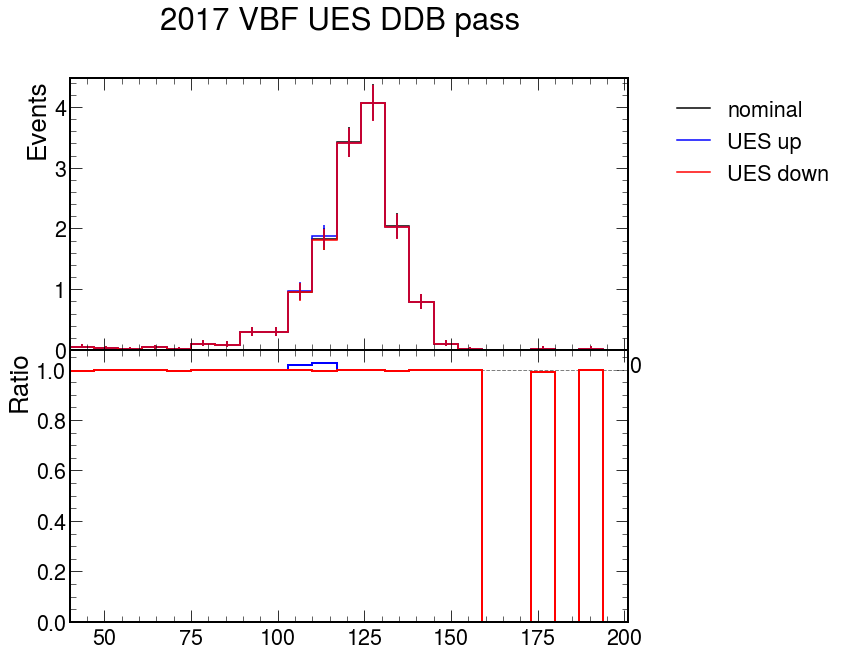

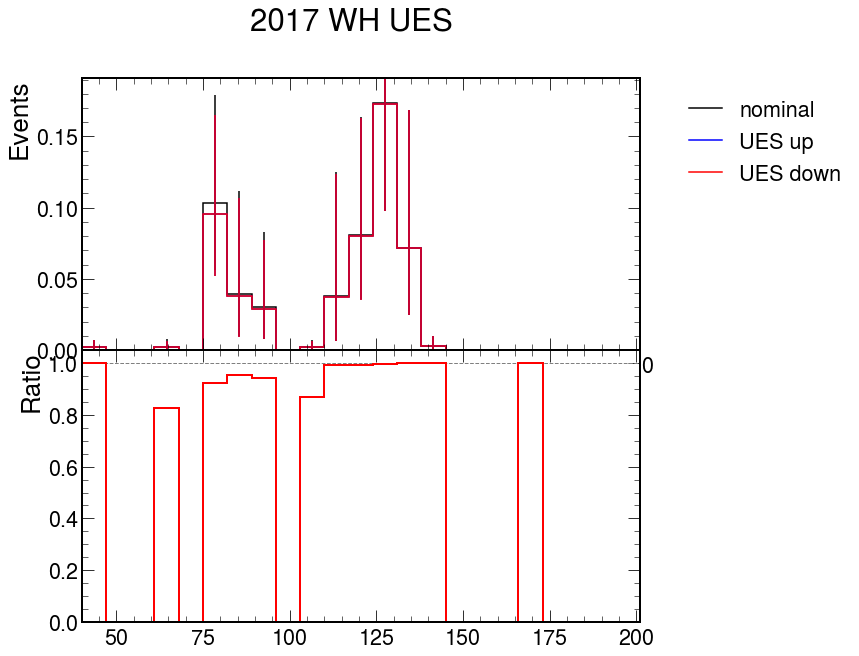

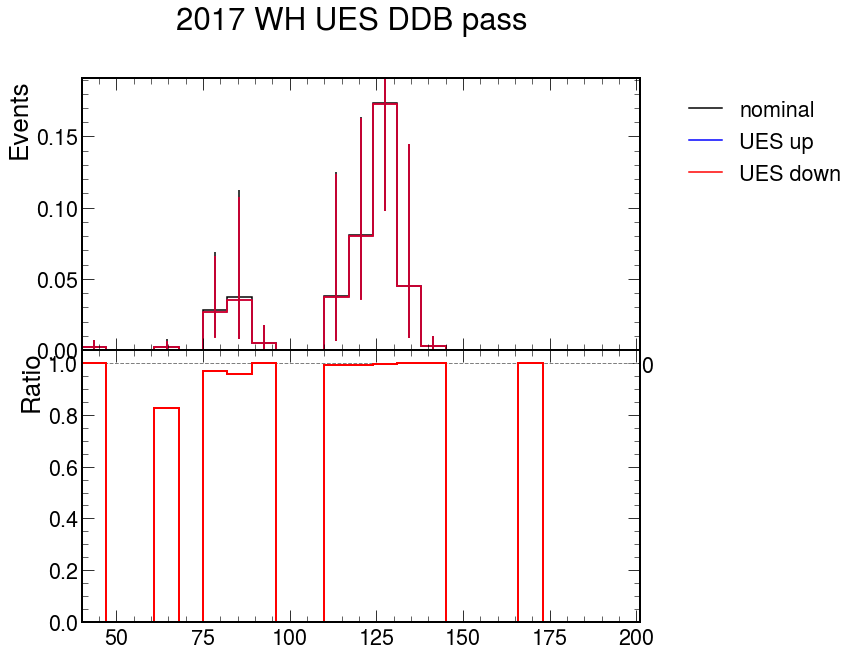

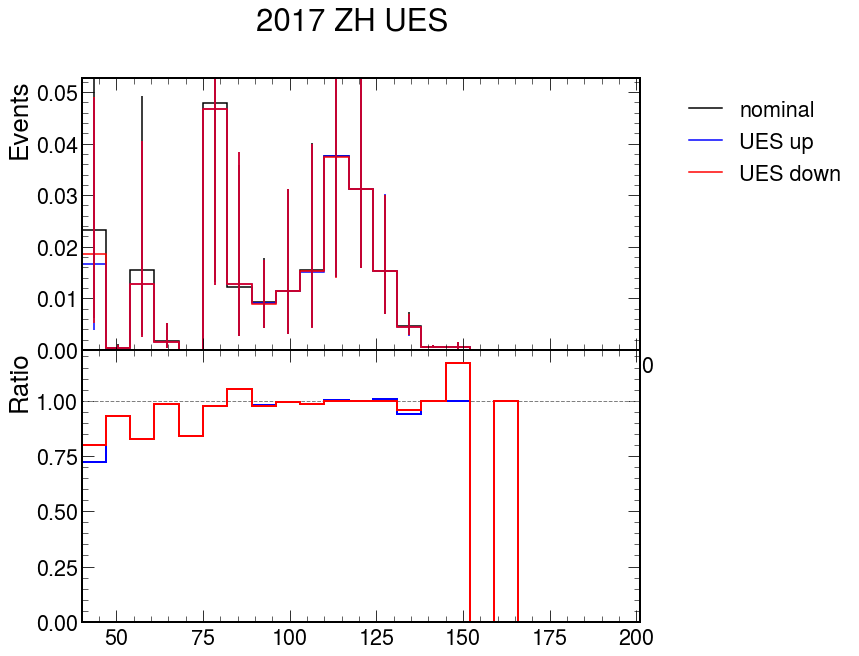

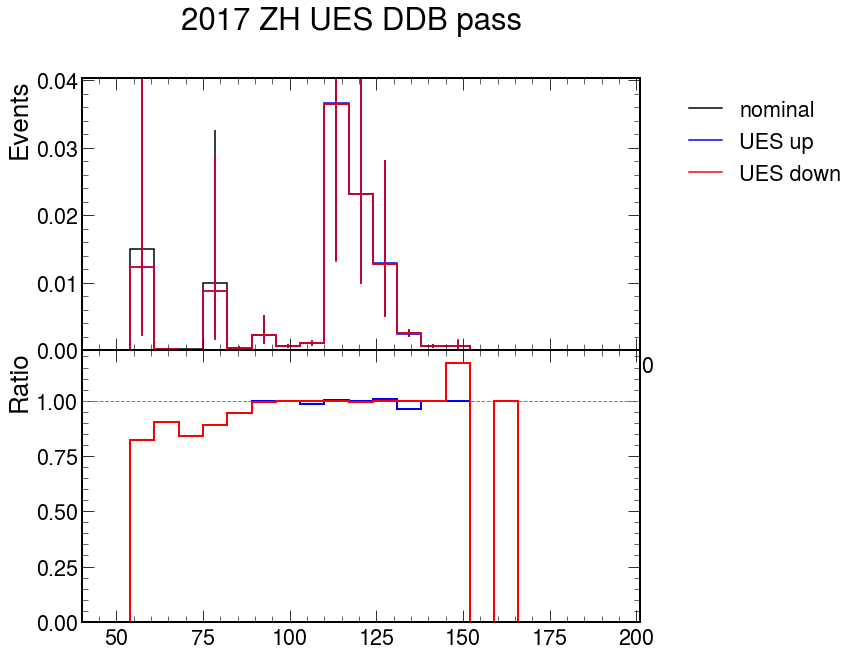

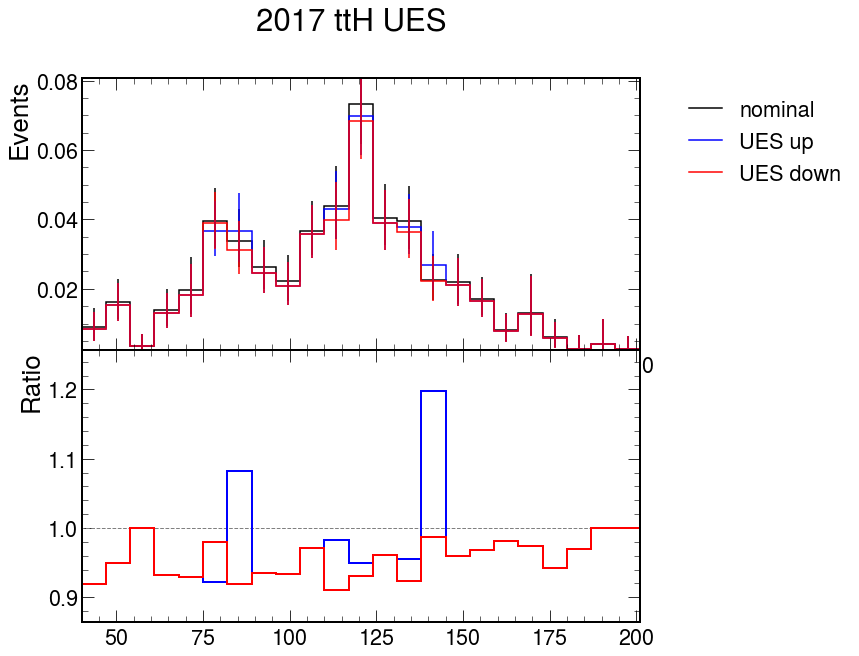

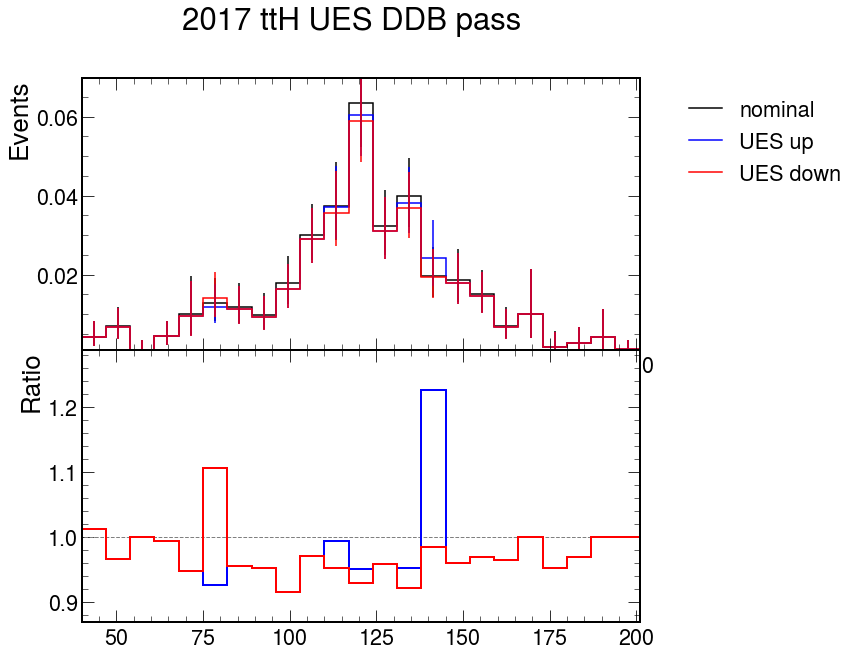

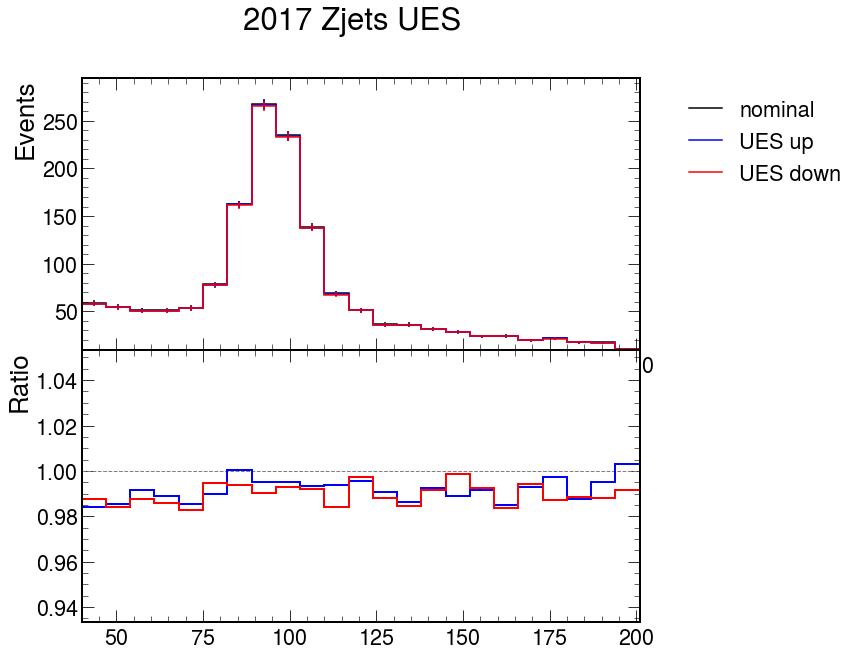

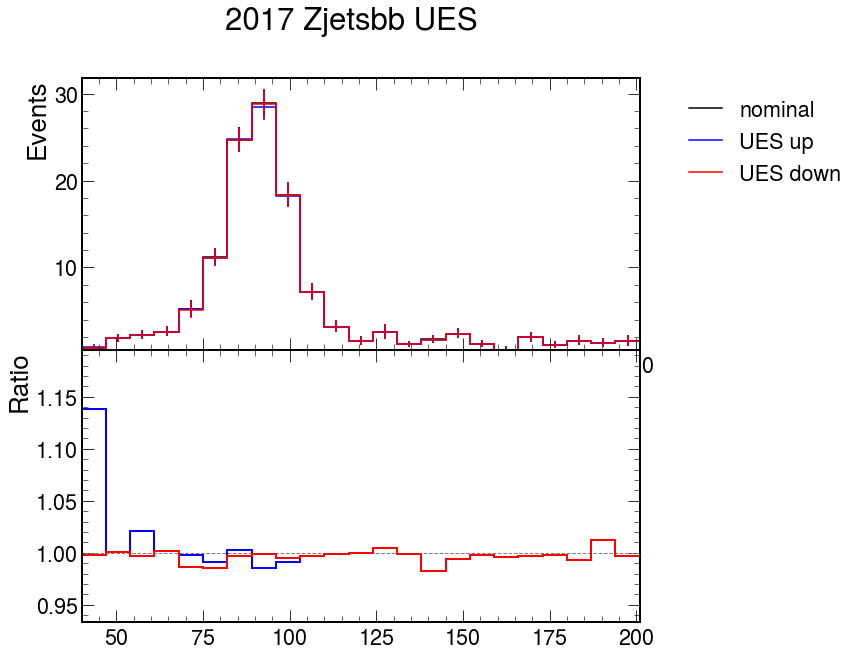

In [28]:
s = 'UES'

for p in mc:
    plot_syst(h.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s,year+'/syst_'+s+'/'+p)
    plot_syst(g.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s+' DDB pass',year+'/syst_'+s+'/'+p+"_pass")
    
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(0,3)),s,year+' Zjets '+s,year+'/syst_'+s+'/Zjets')
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(3,4)),s,year+' Zjetsbb '+s,year+'/syst_'+s+'/Zjetsbb')

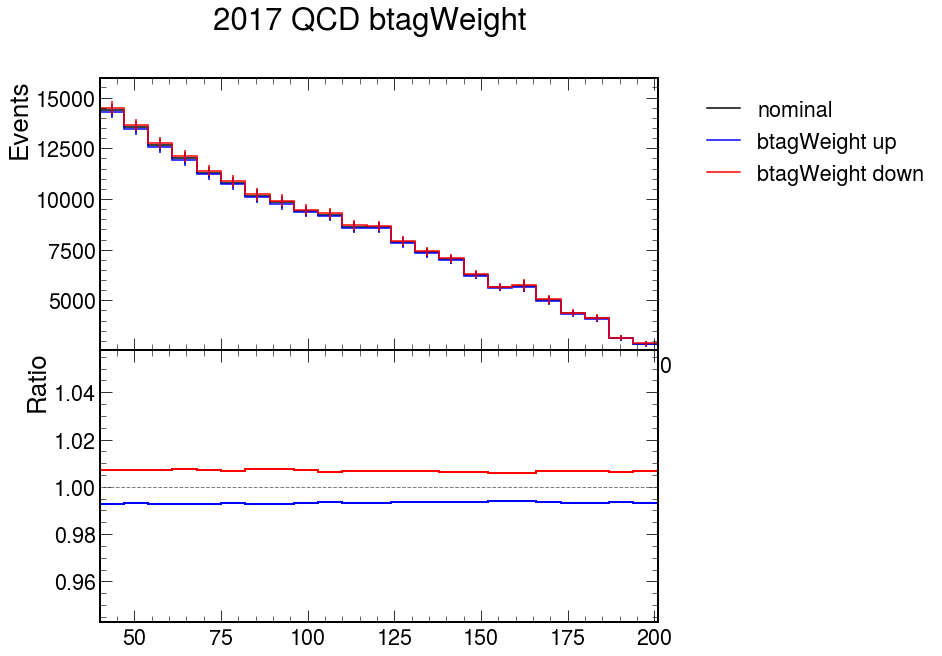

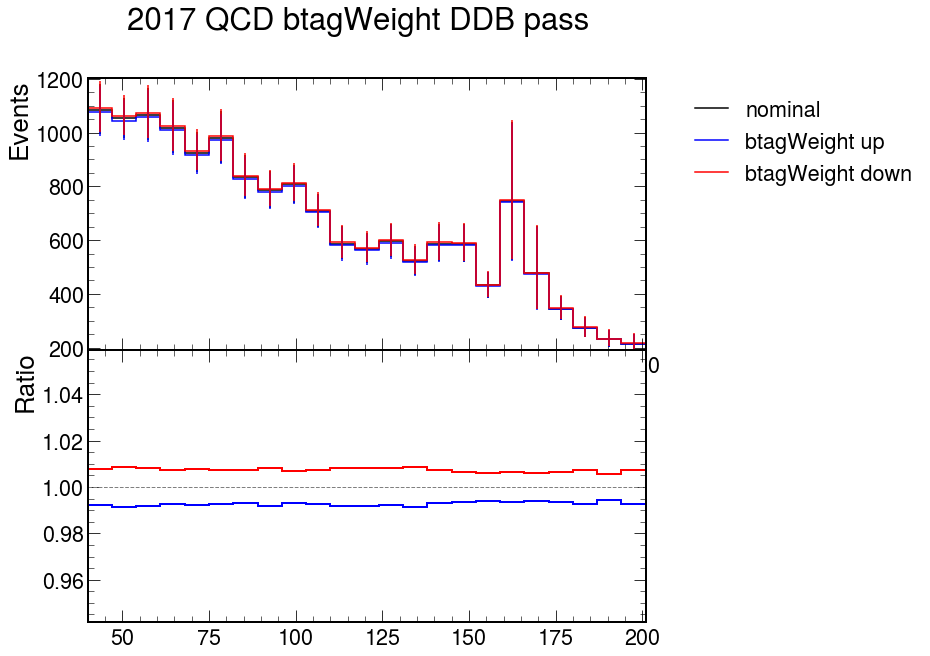

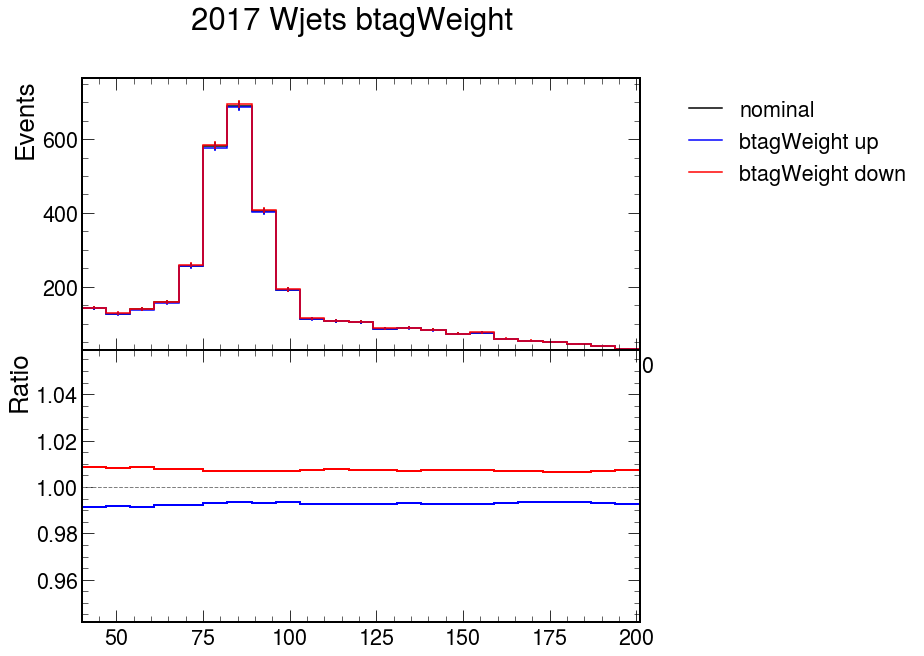

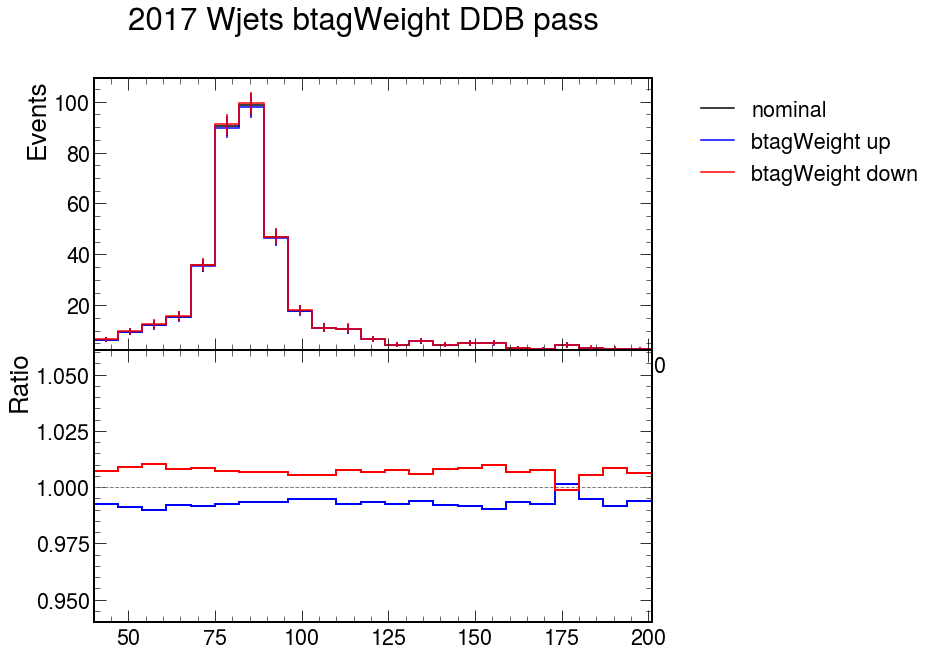

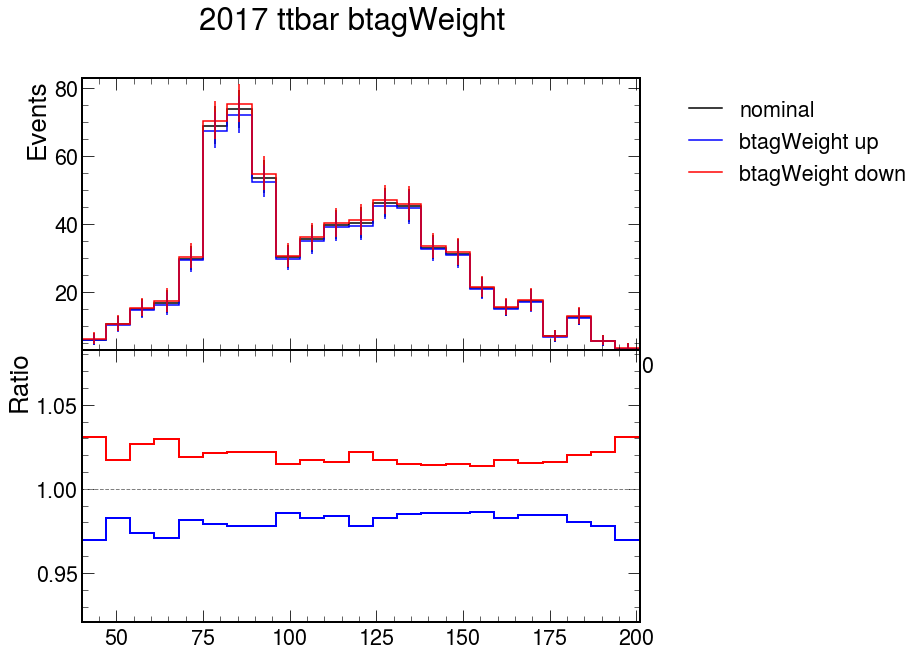

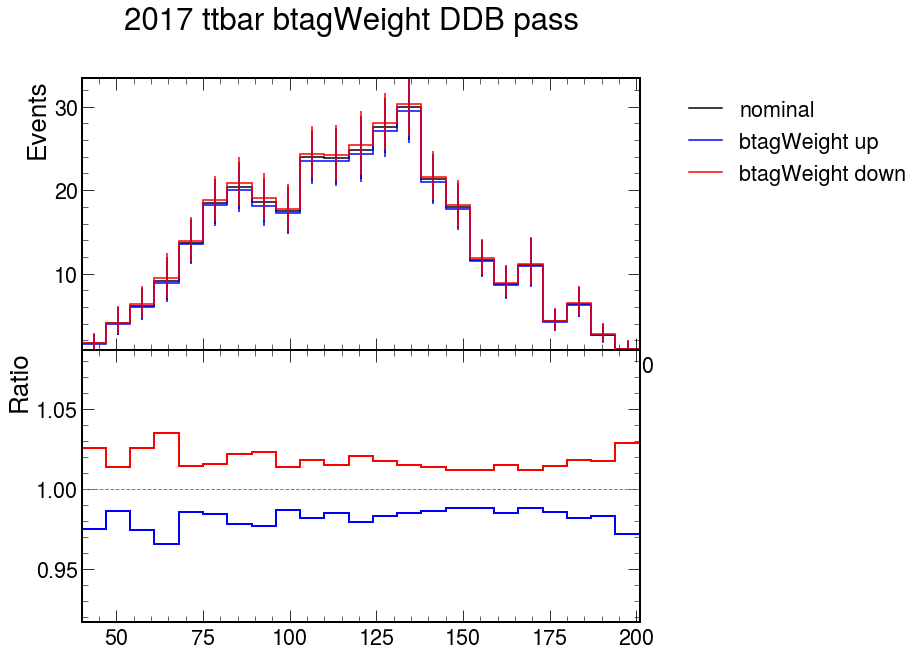

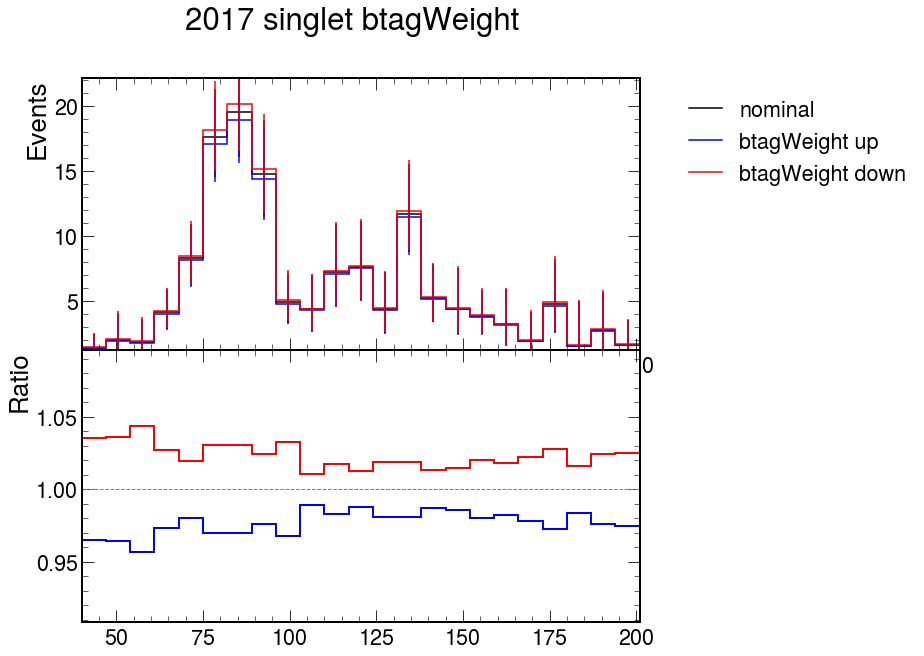

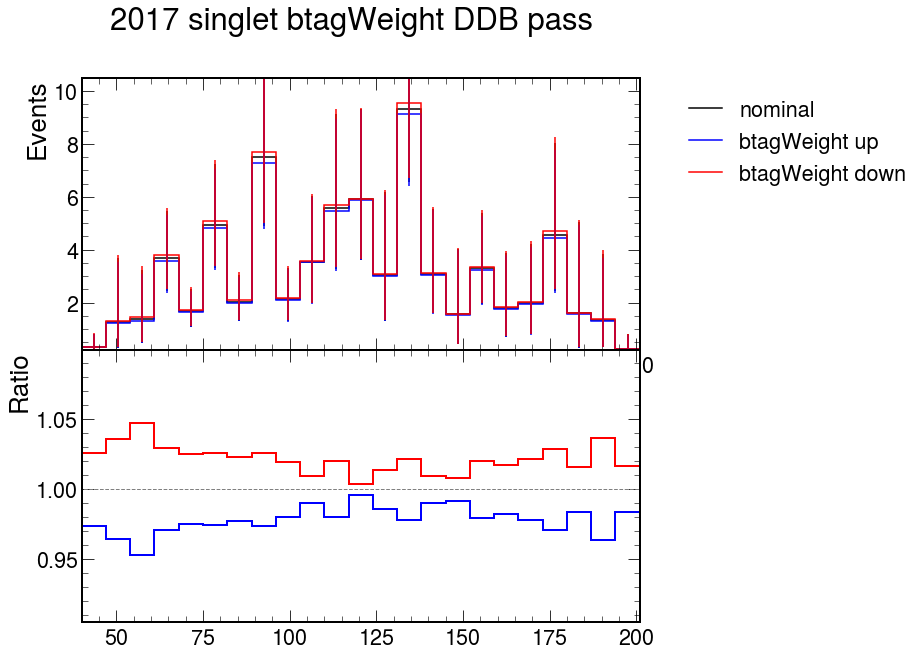

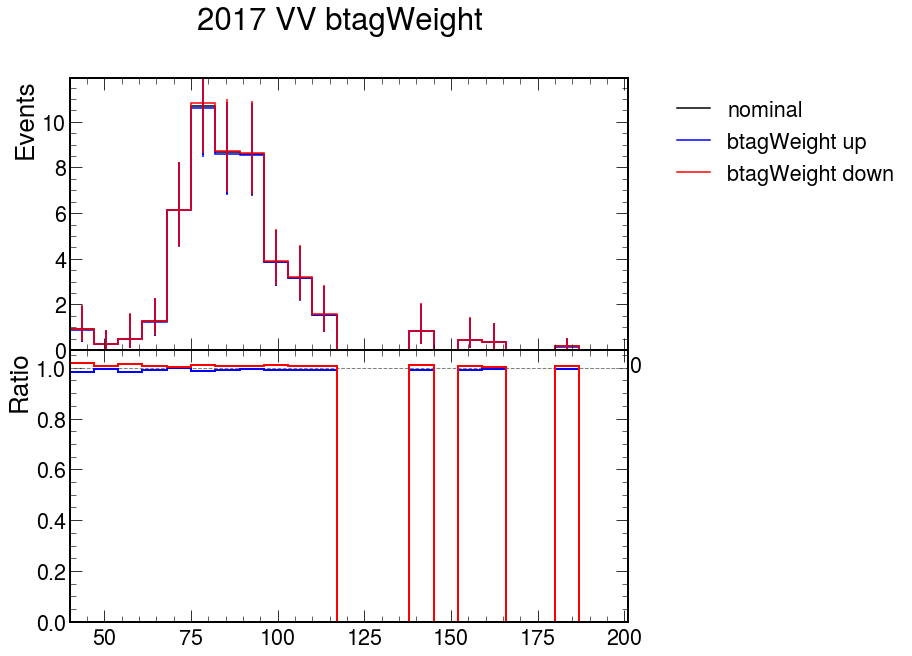

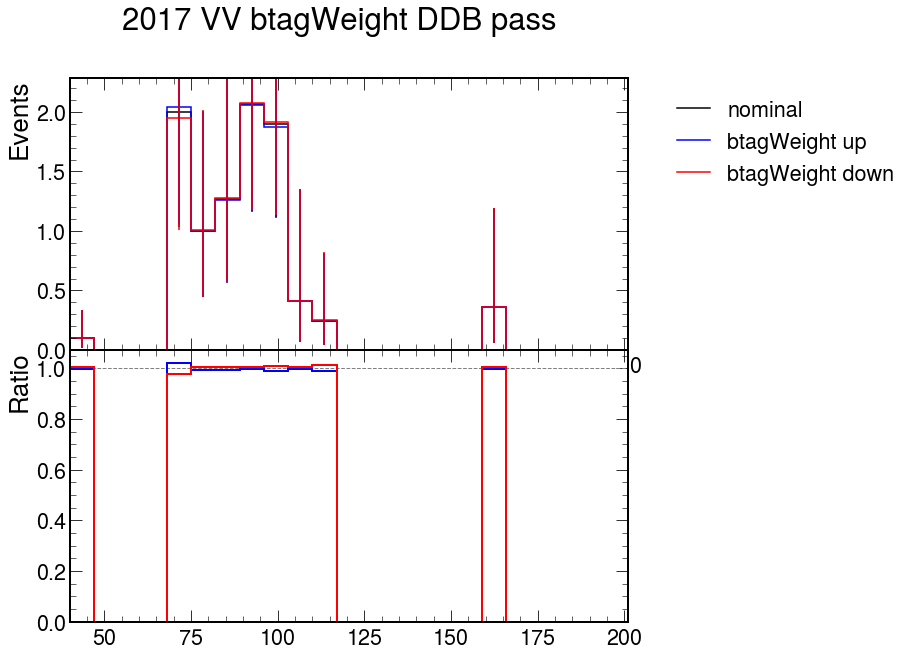

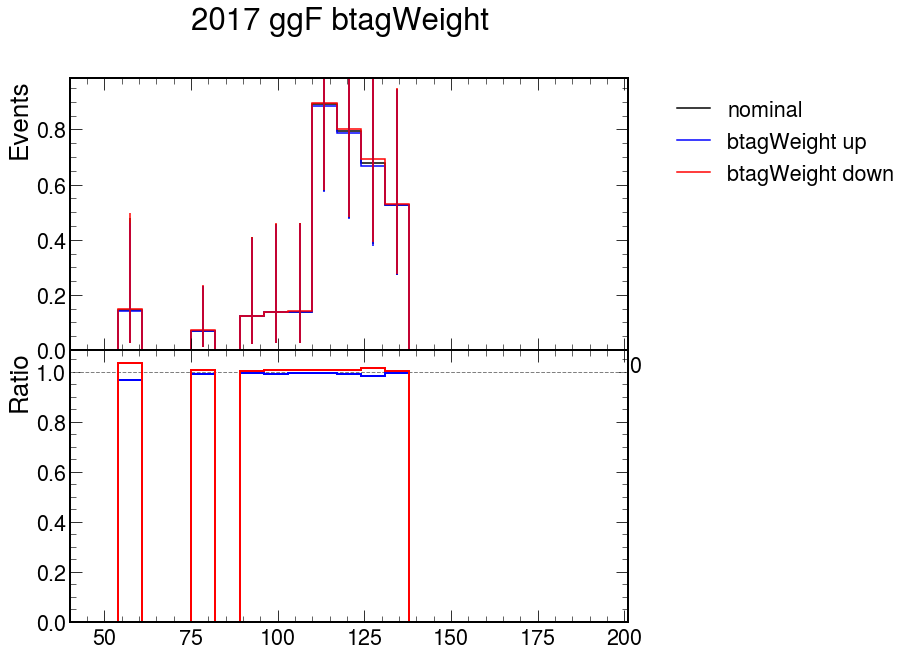

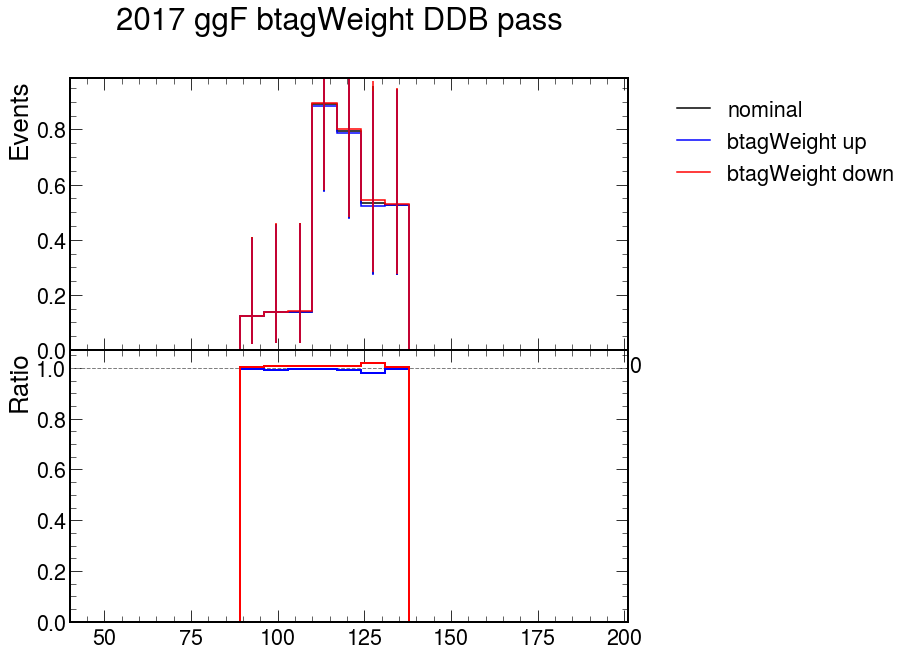

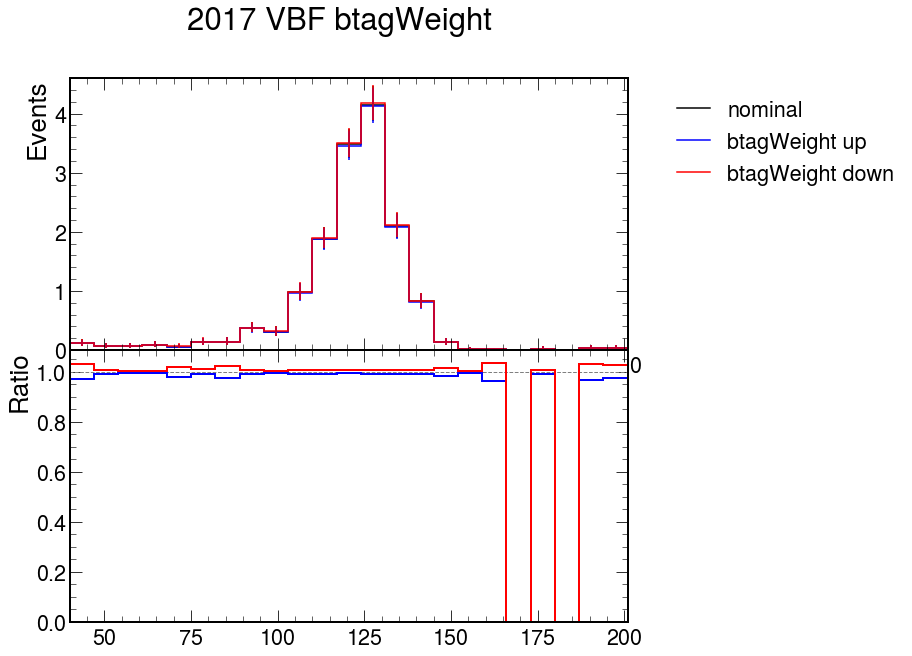

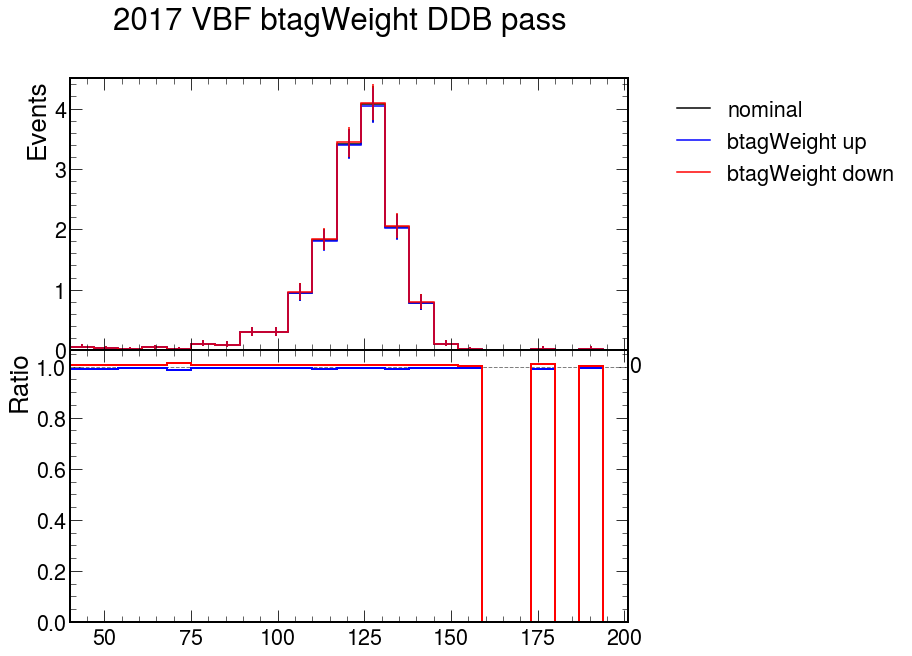

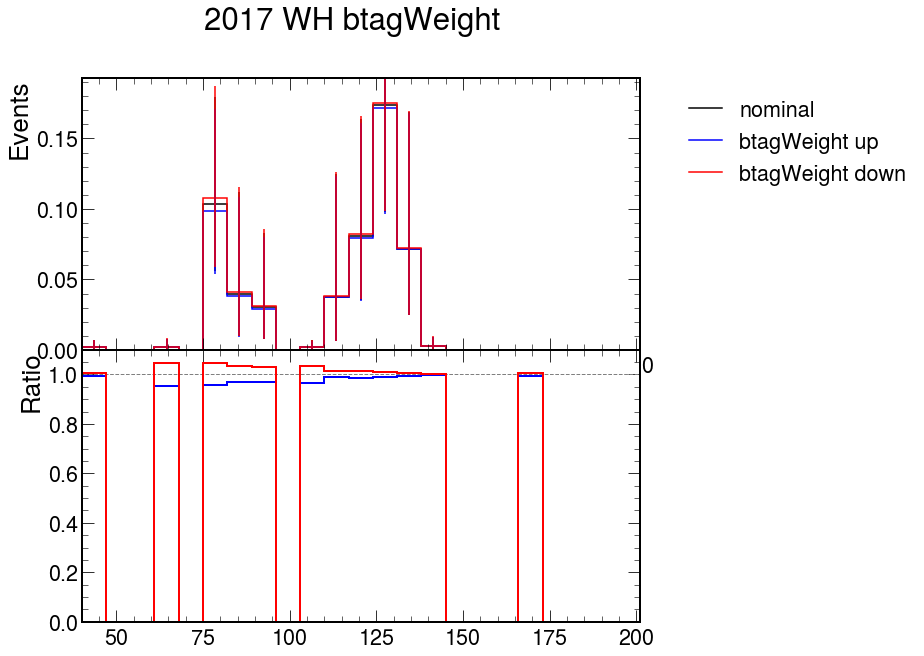

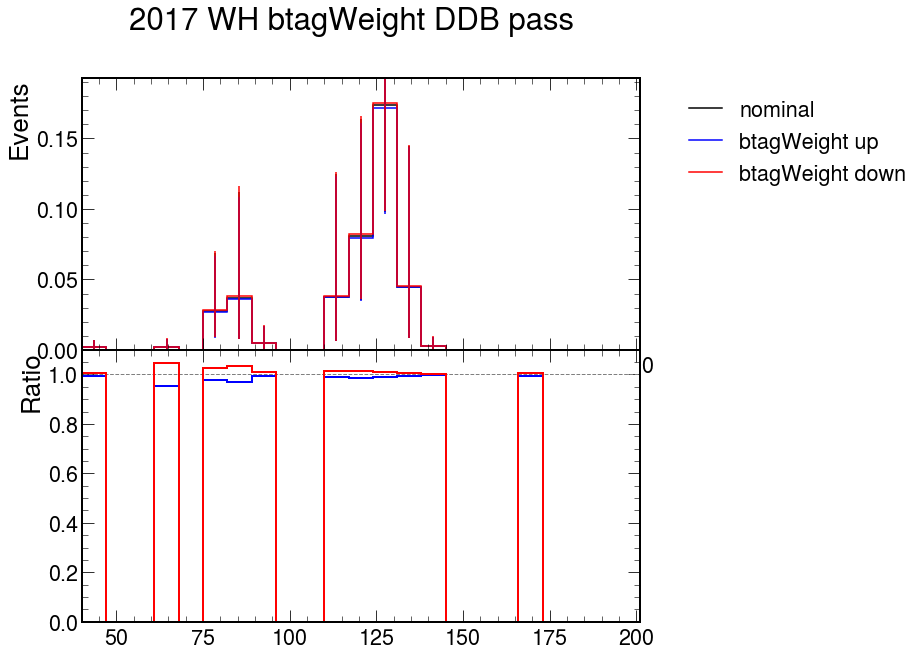

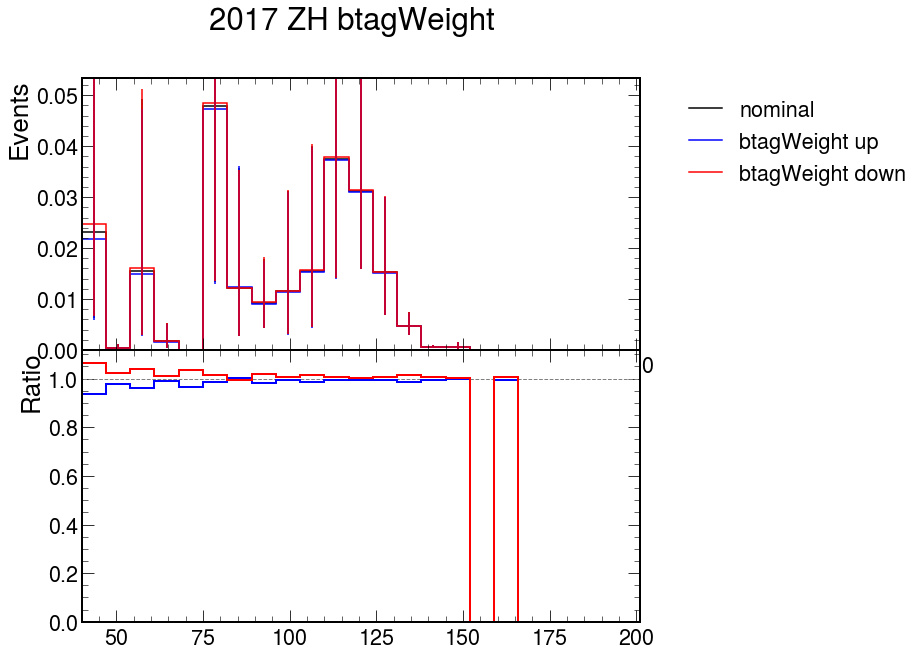

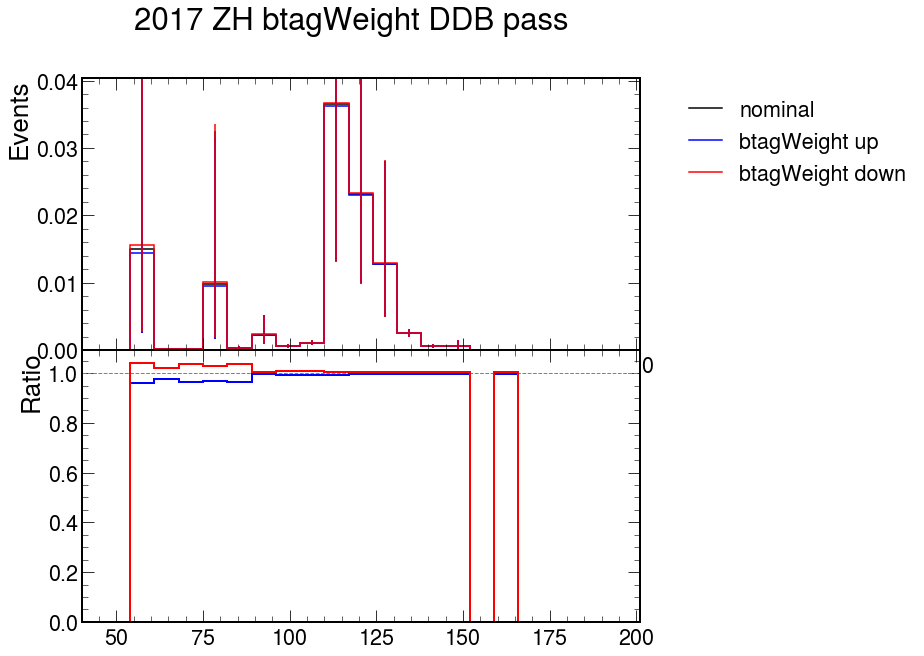

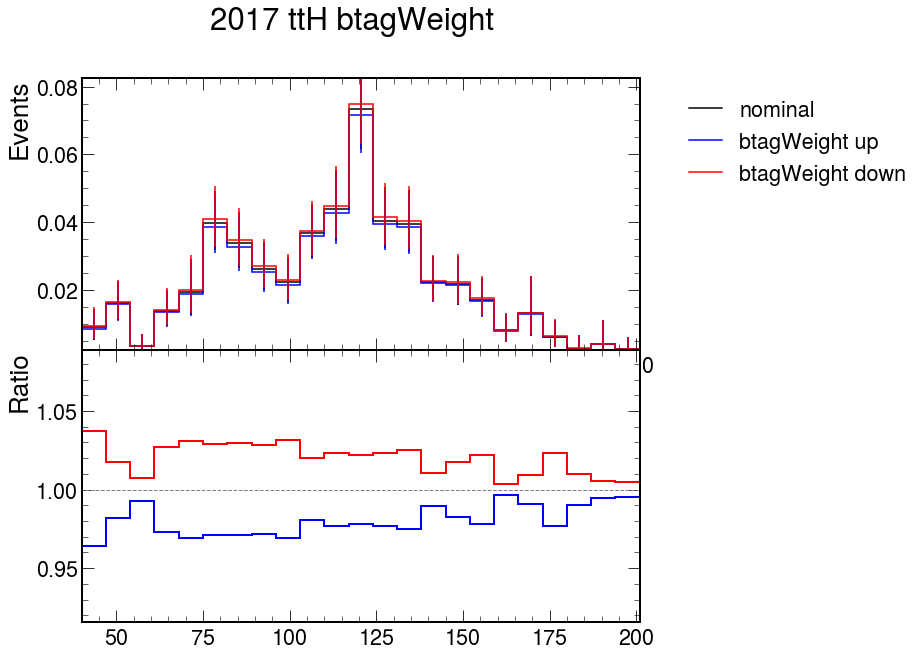

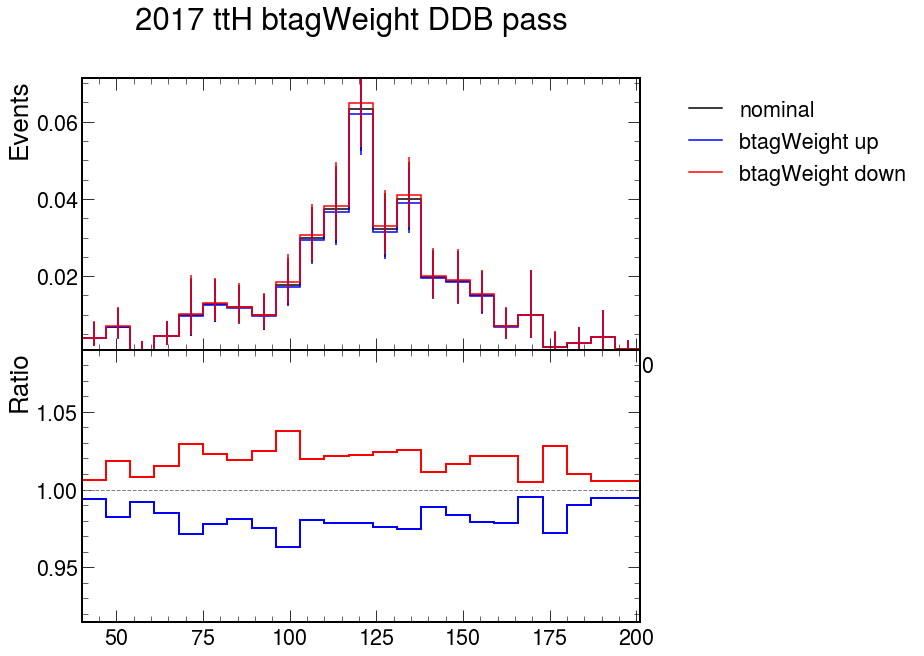

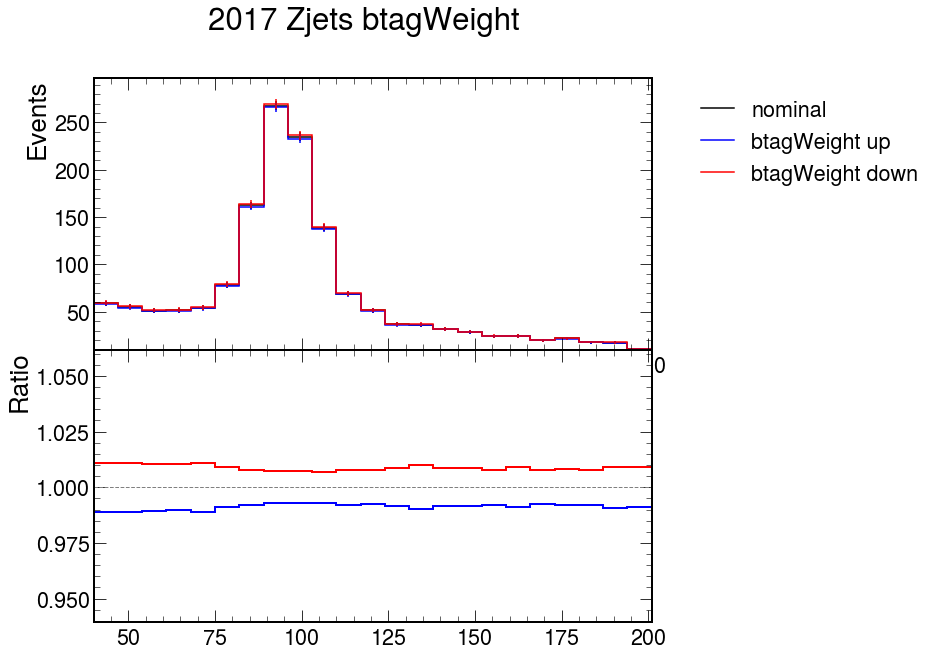

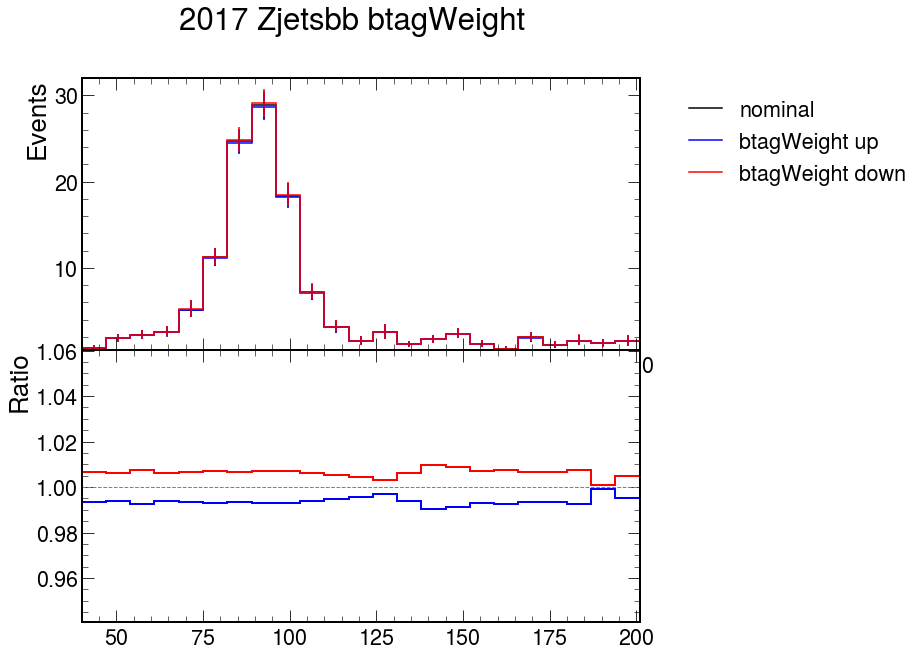

In [26]:
s = 'btagWeight'

for p in mc:
    plot_syst(h.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s,year+'/syst_'+s+'/'+p)
    plot_syst(g.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s+' DDB pass',year+'/syst_'+s+'/'+p+"_pass")
    
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(0,3)),s,year+' Zjets '+s,year+'/syst_'+s+'/Zjets')
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(3,4)),s,year+' Zjetsbb '+s,year+'/syst_'+s+'/Zjetsbb')

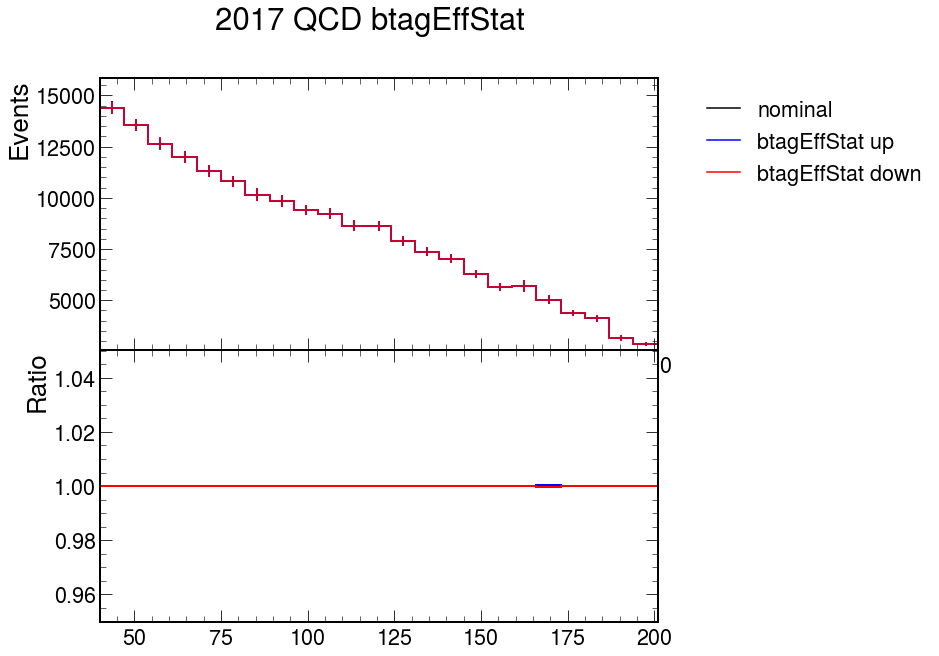

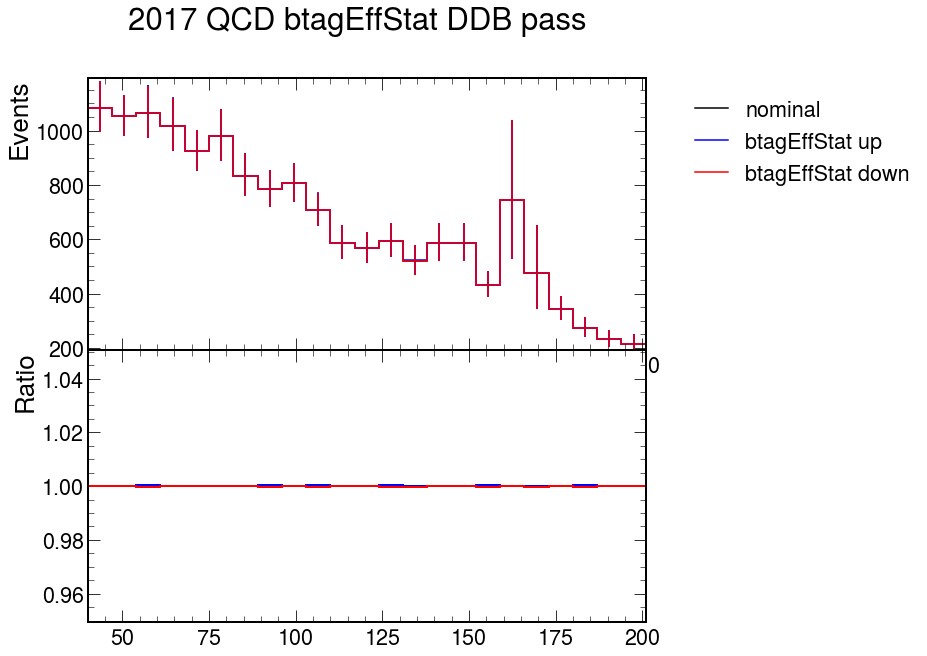

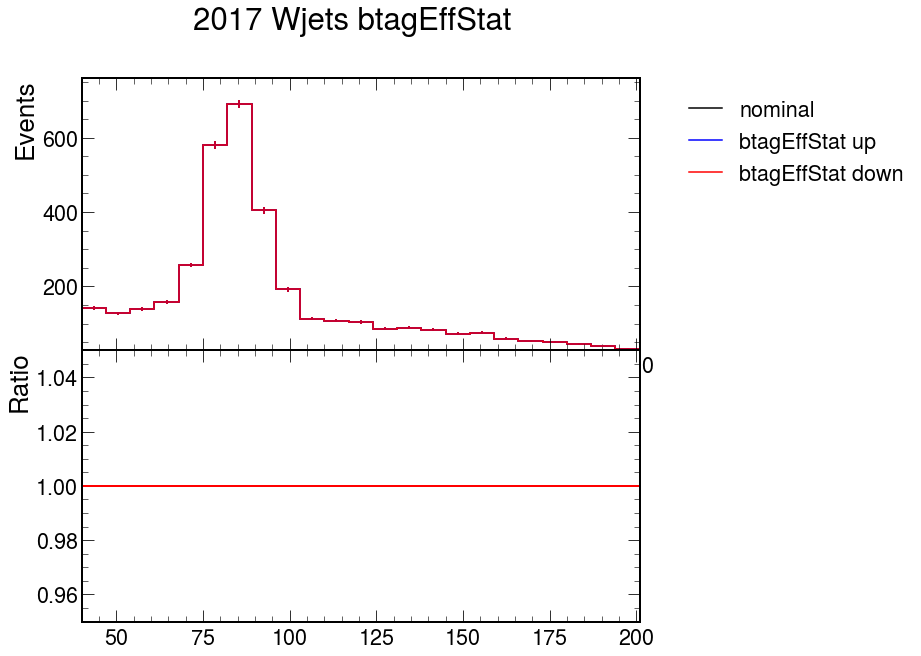

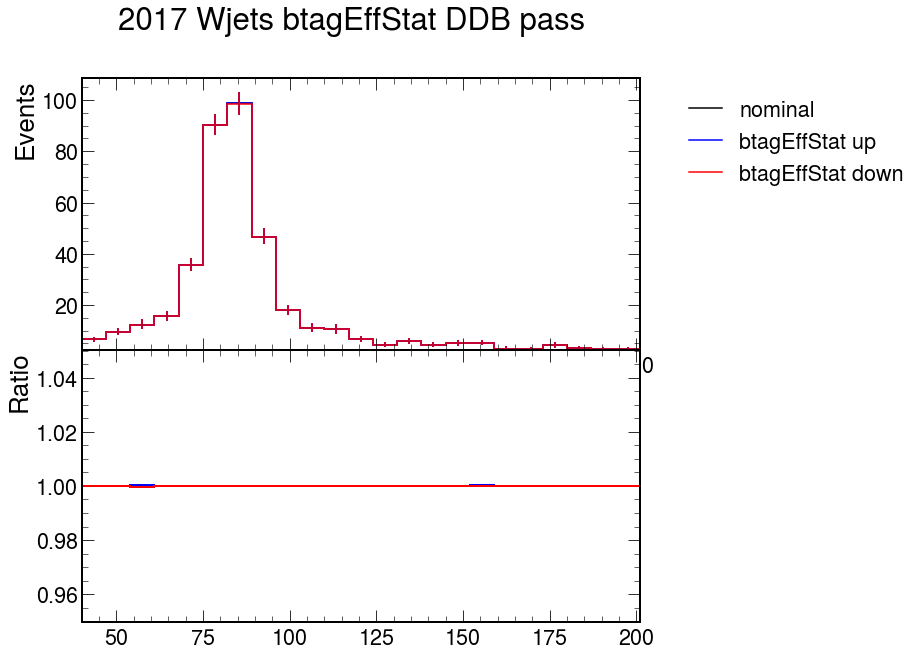

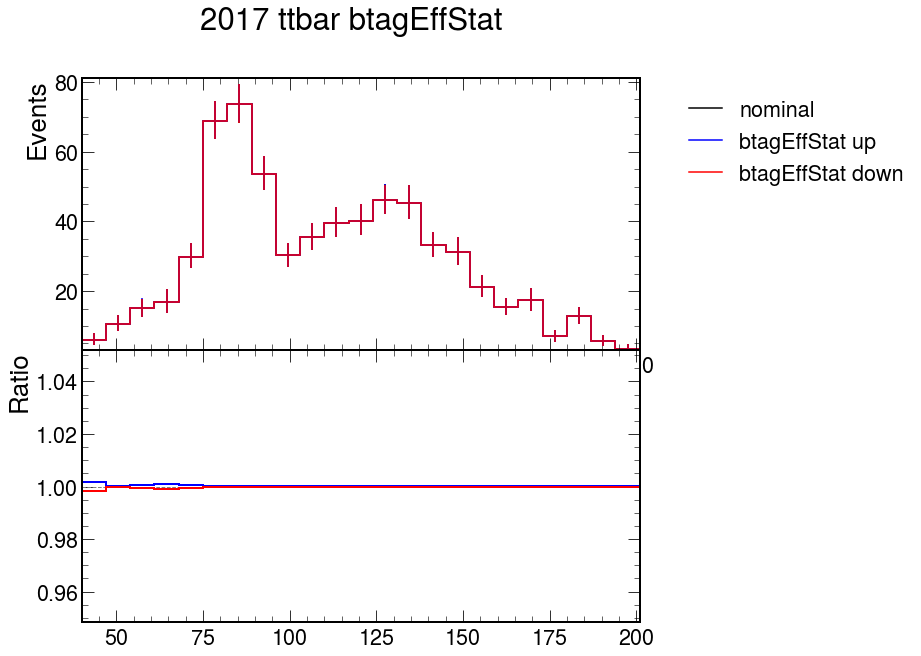

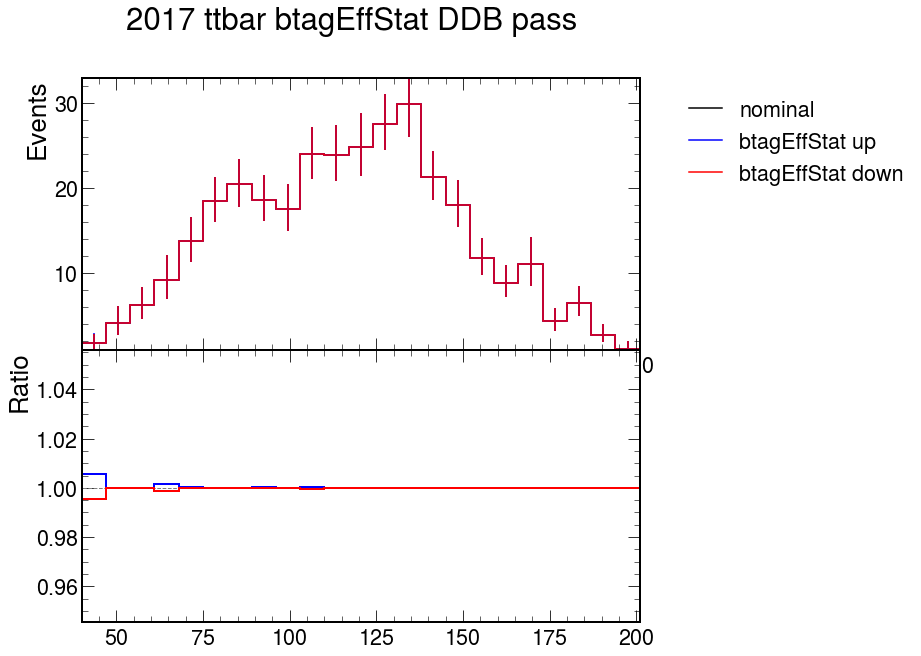

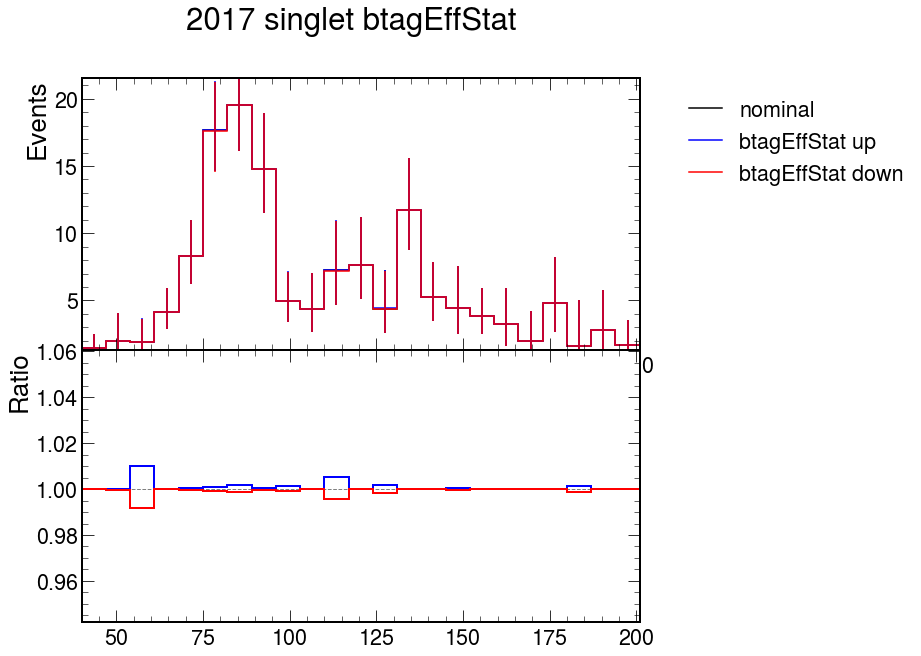

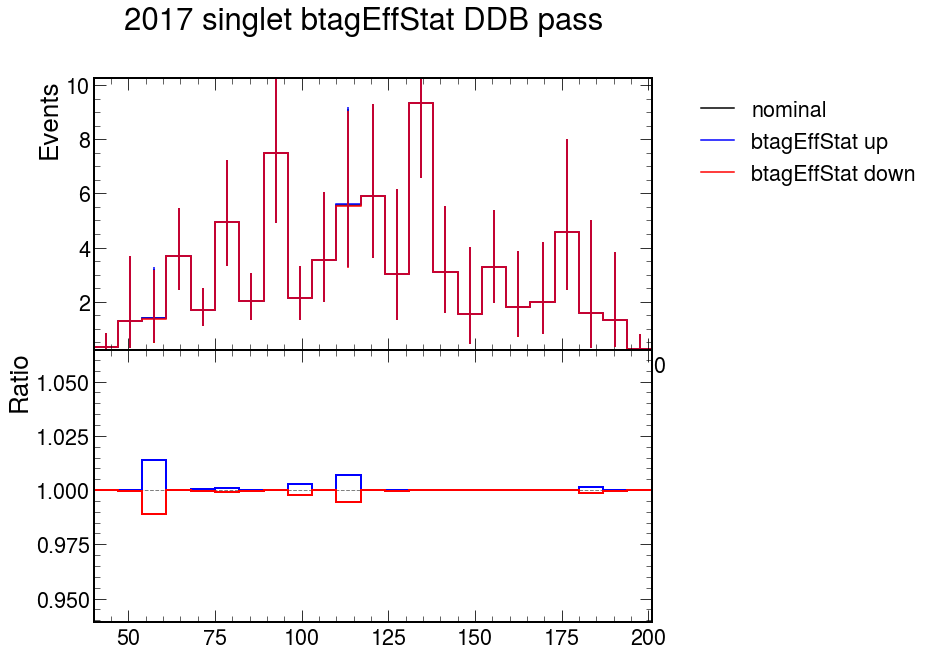

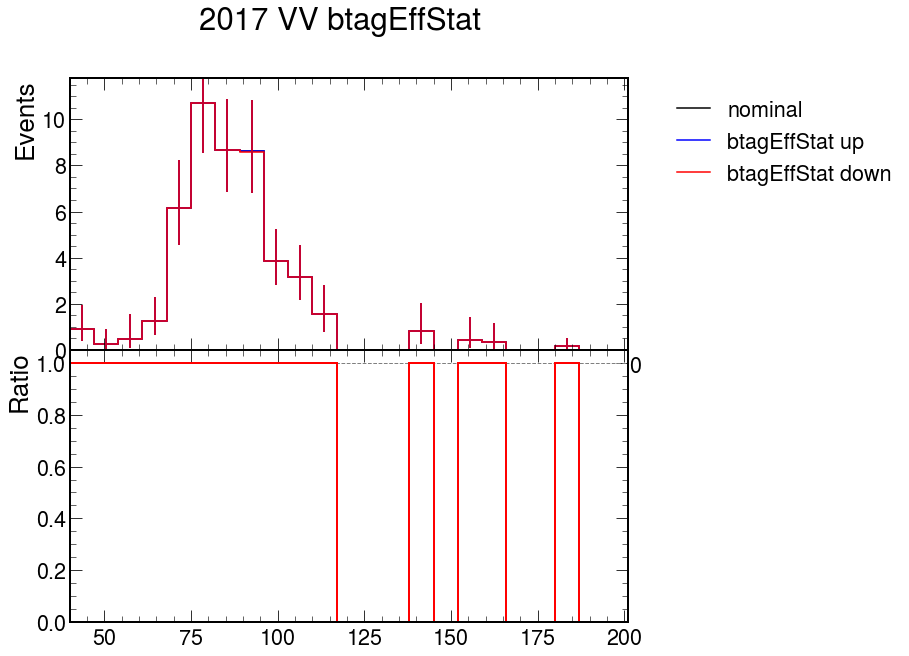

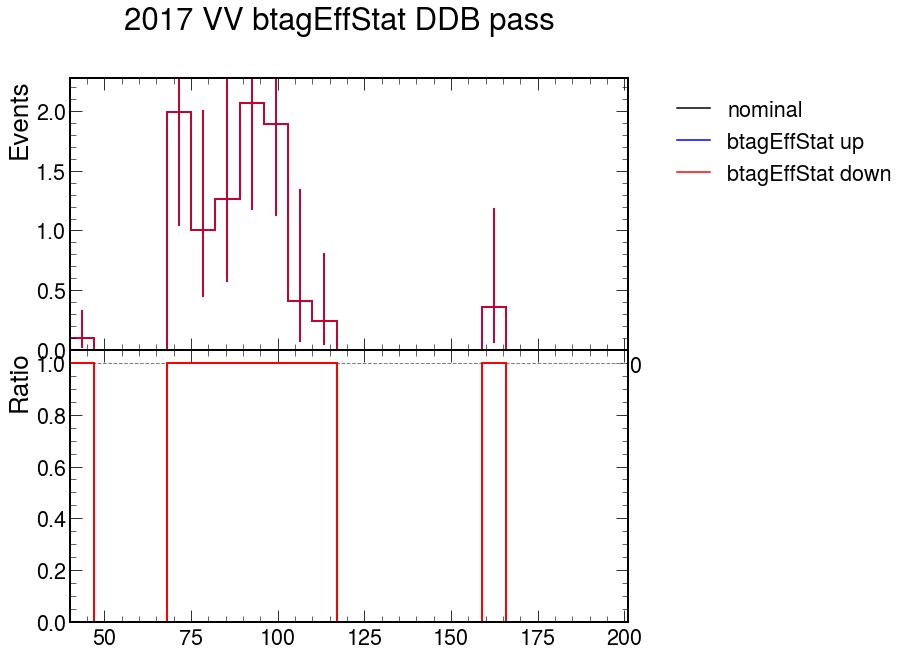

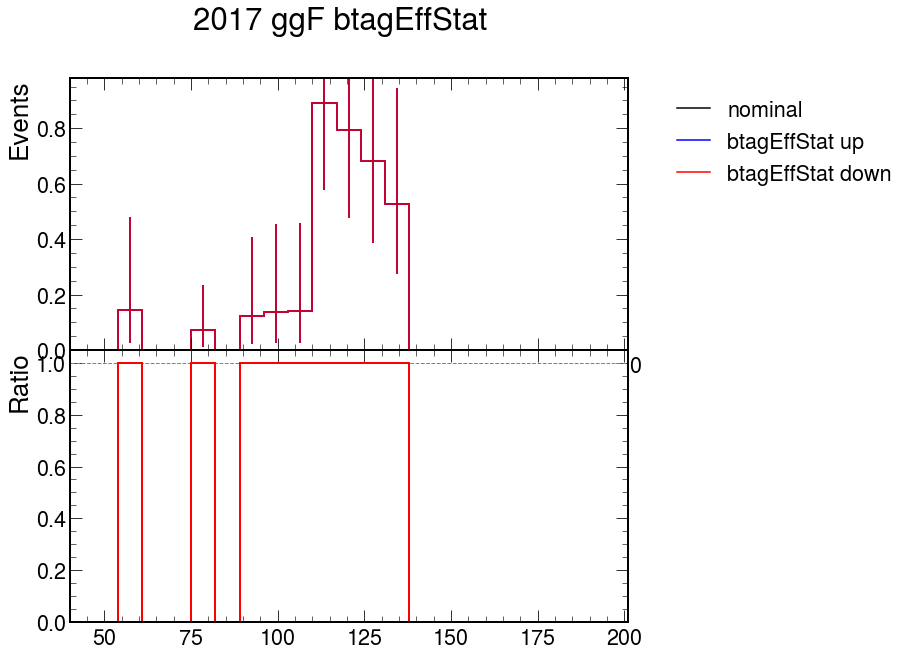

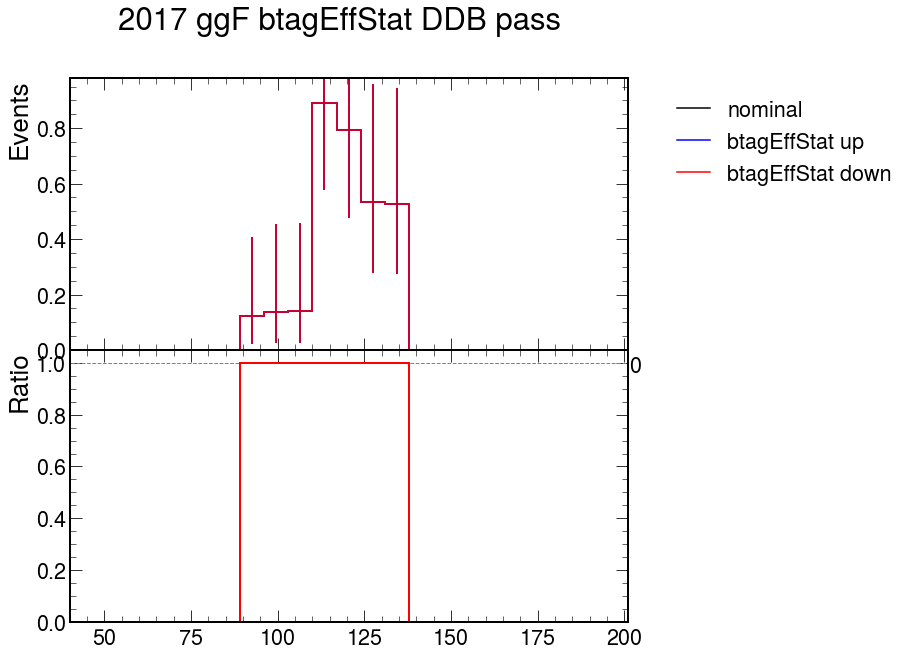

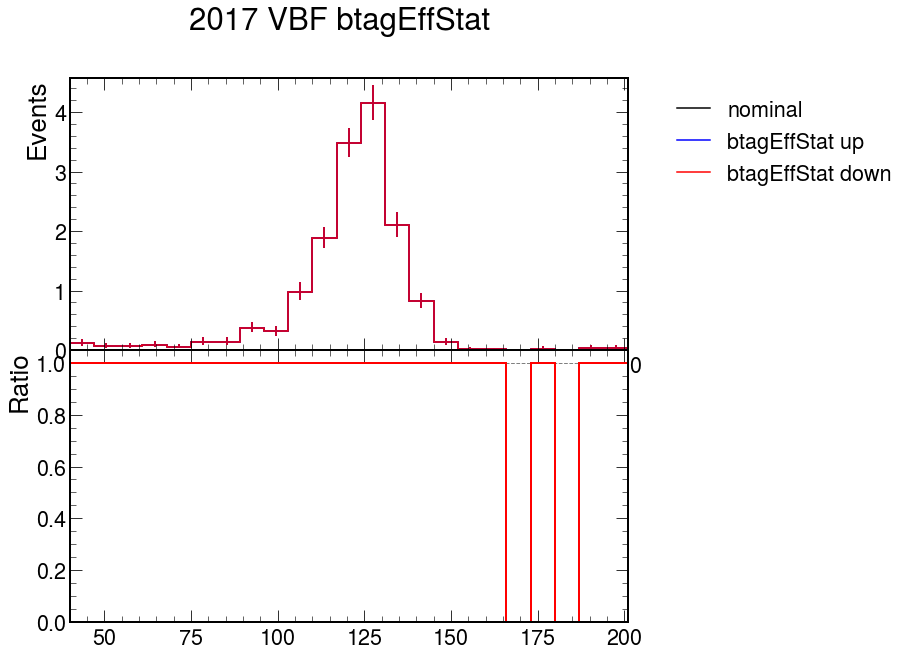

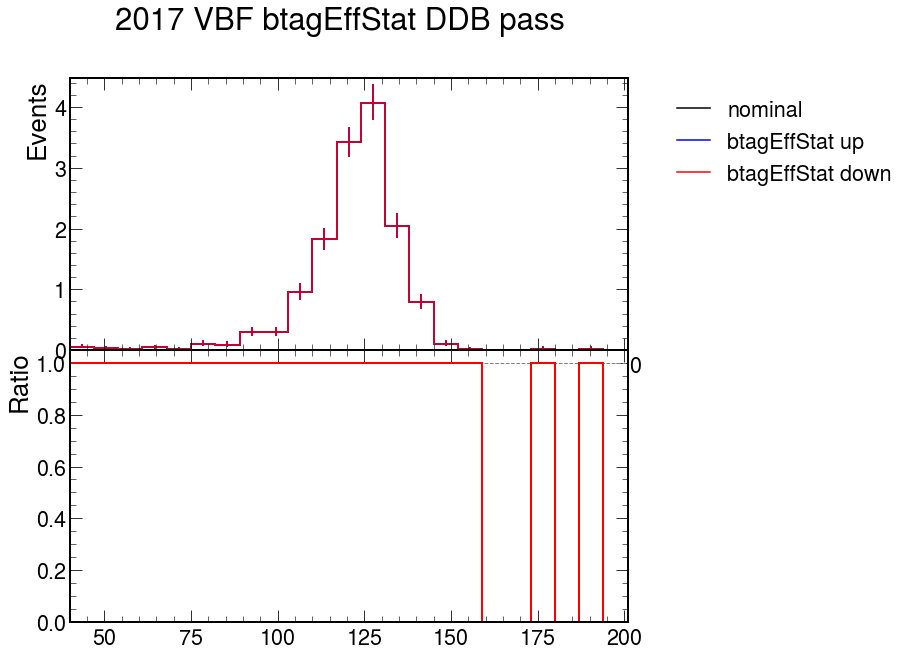

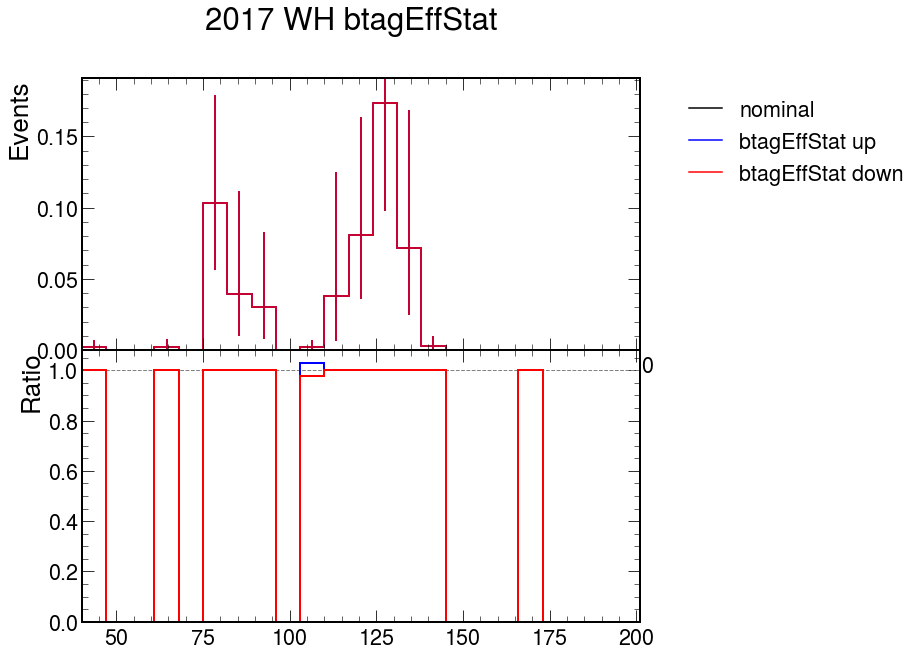

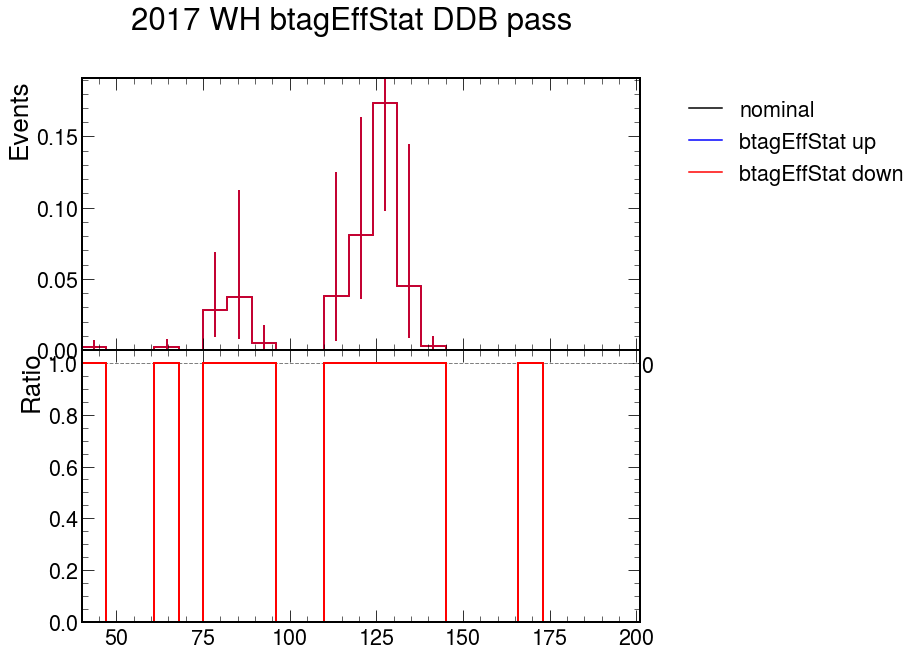

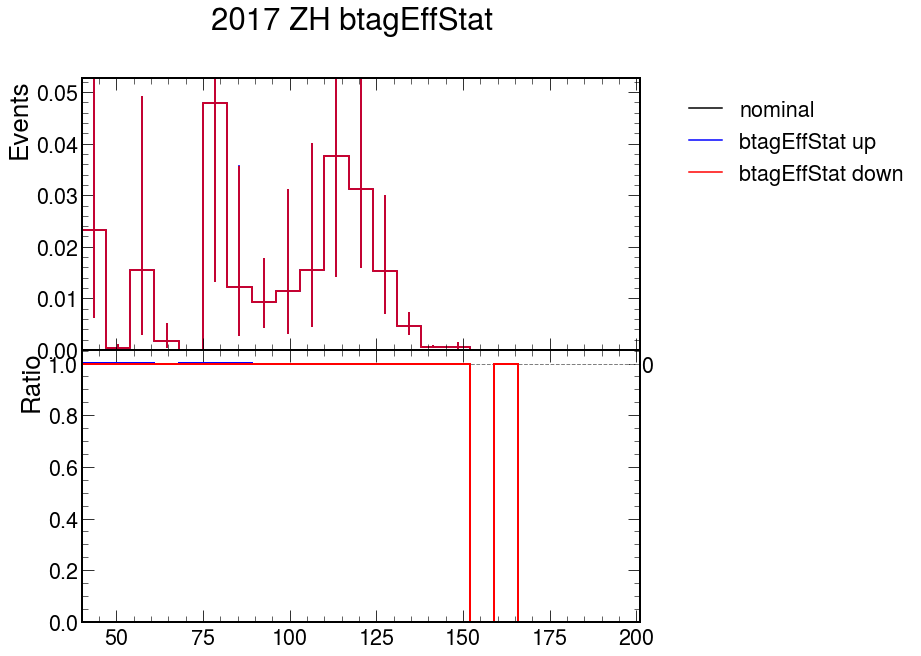

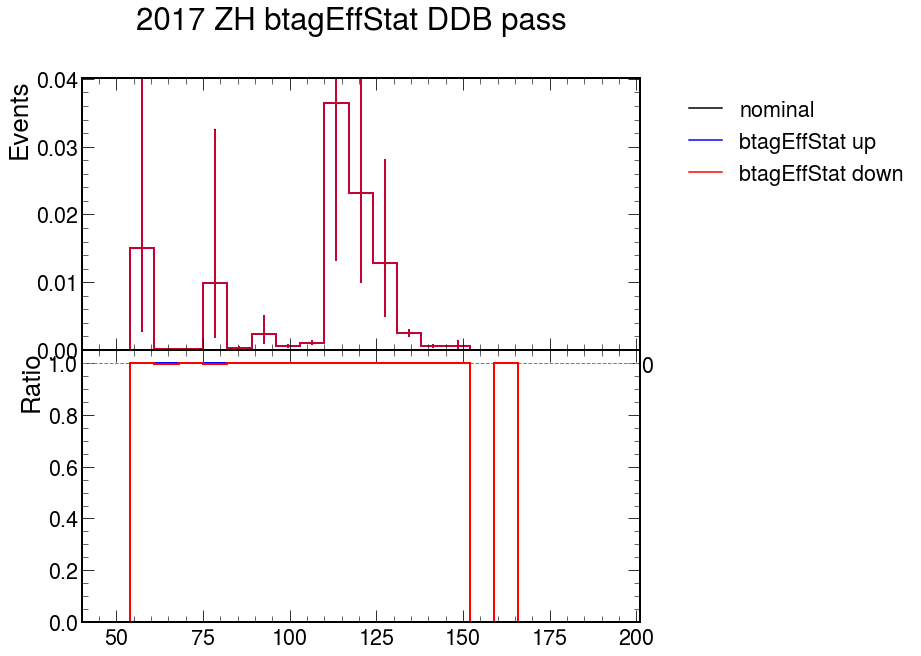

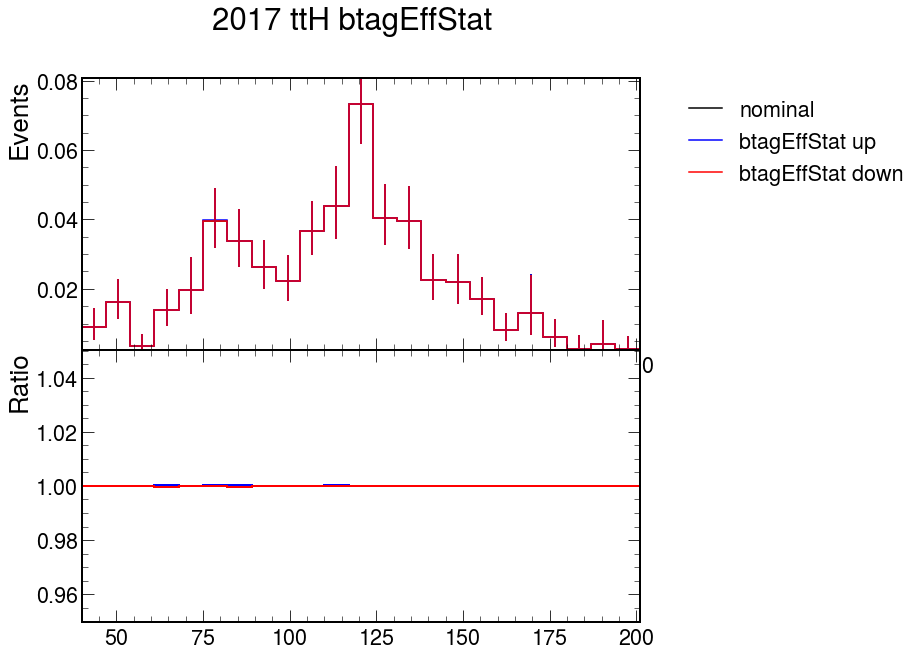

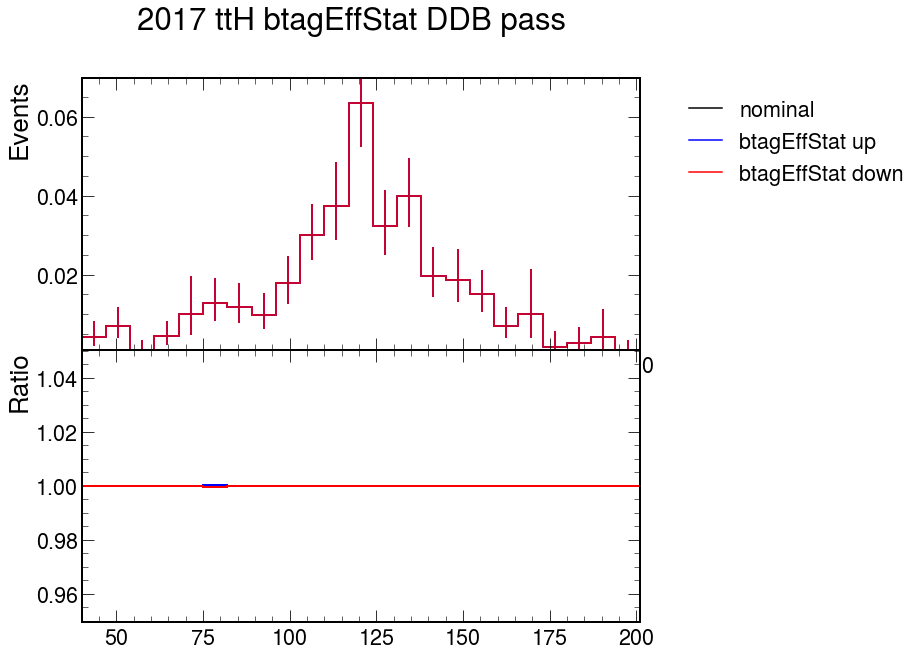

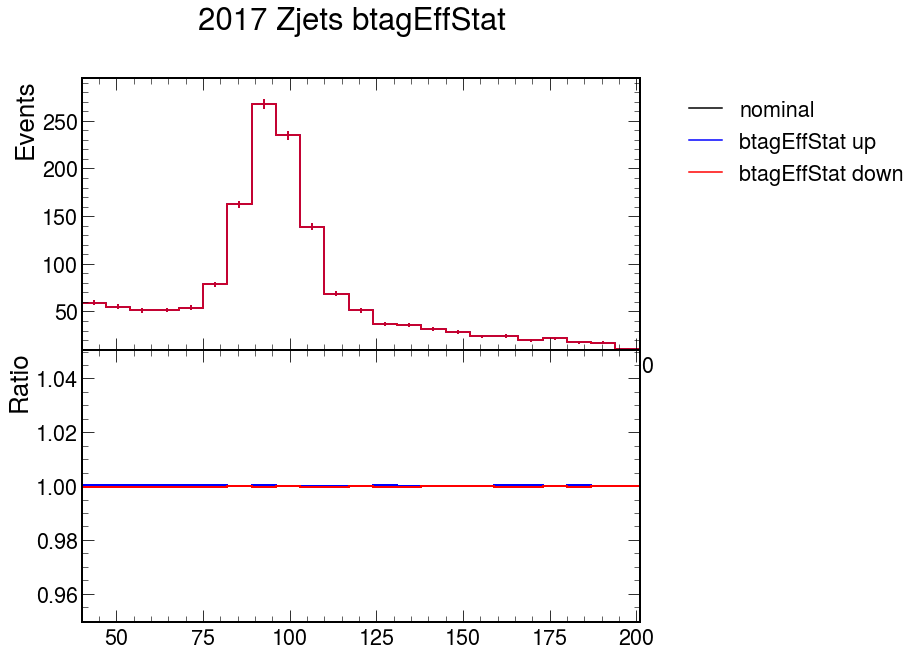

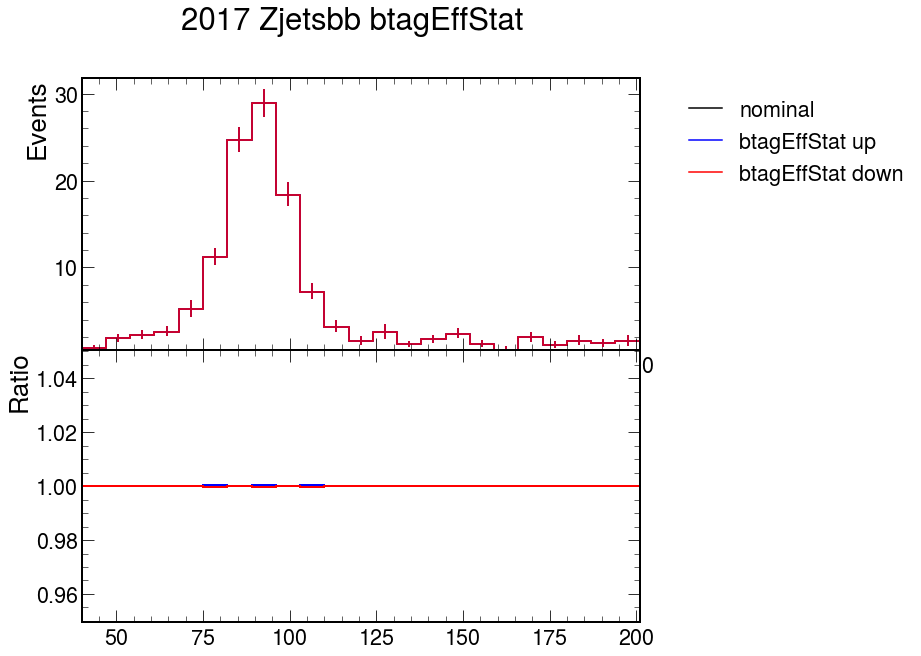

In [27]:
s = 'btagEffStat'

for p in mc:
    plot_syst(h.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s,year+'/syst_'+s+'/'+p)
    plot_syst(g.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s+' DDB pass',year+'/syst_'+s+'/'+p+"_pass")
    
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(0,3)),s,year+' Zjets '+s,year+'/syst_'+s+'/Zjets')
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(3,4)),s,year+' Zjetsbb '+s,year+'/syst_'+s+'/Zjetsbb')

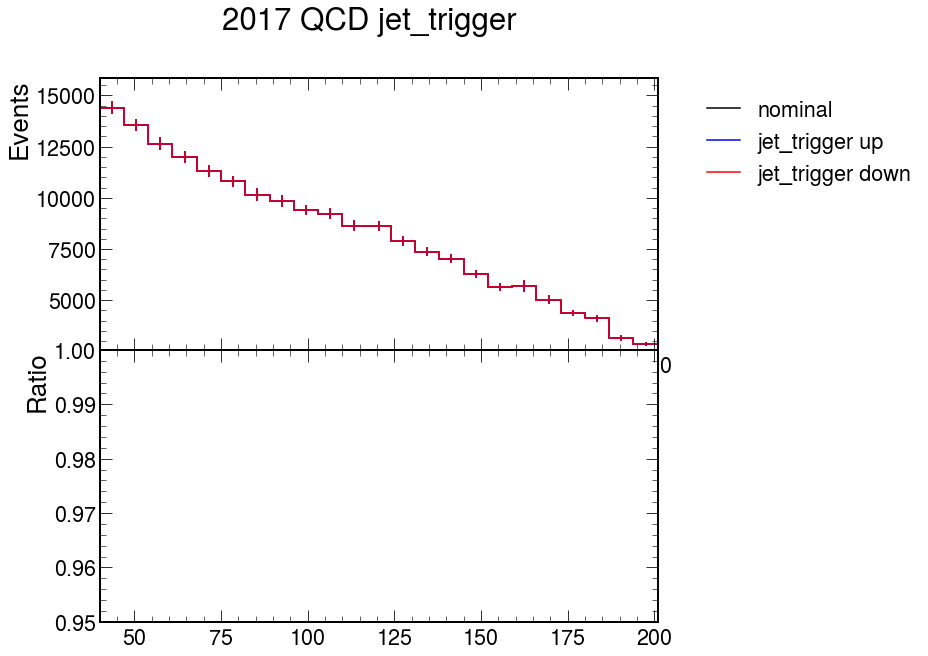

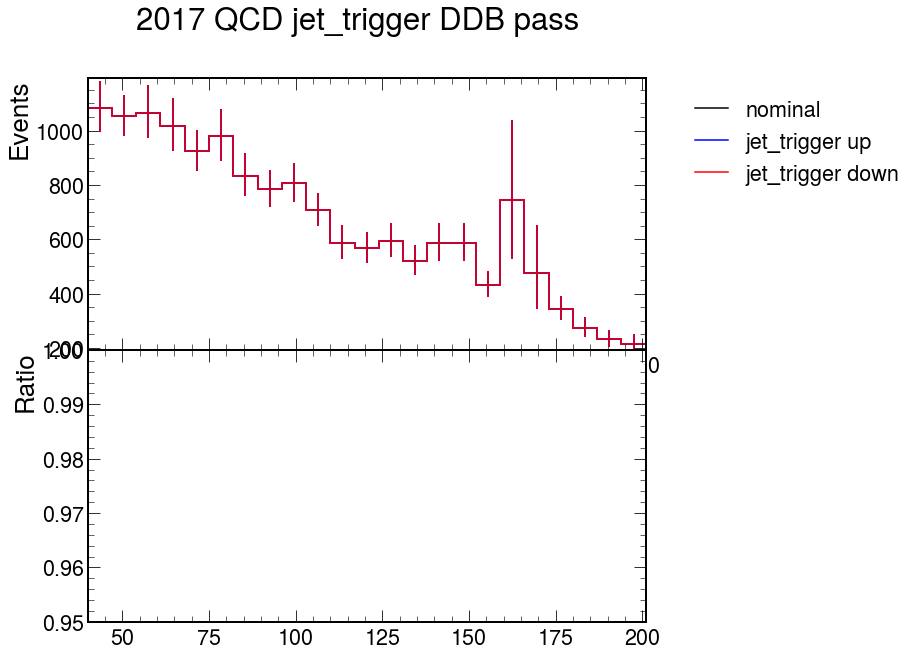

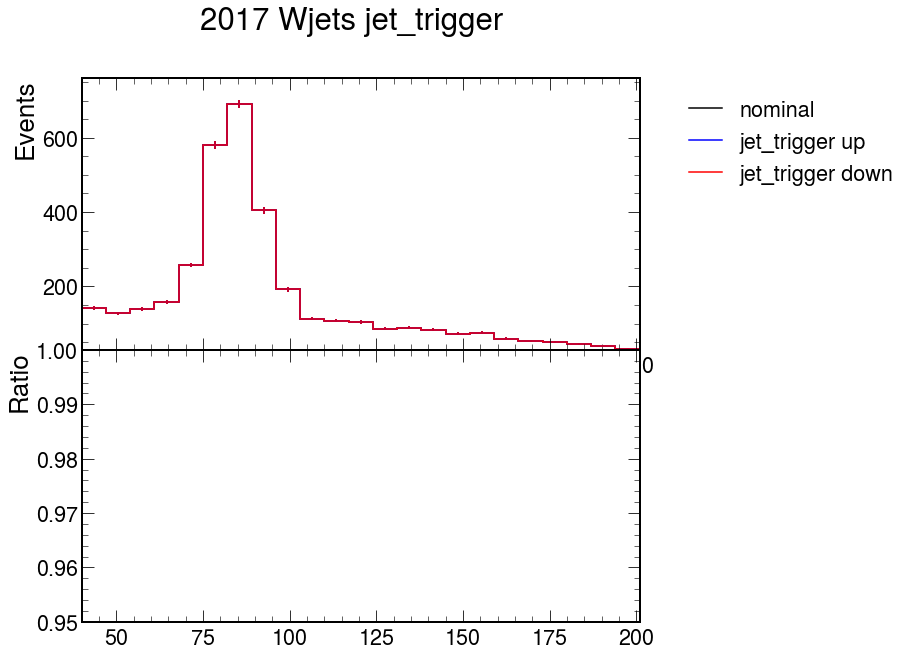

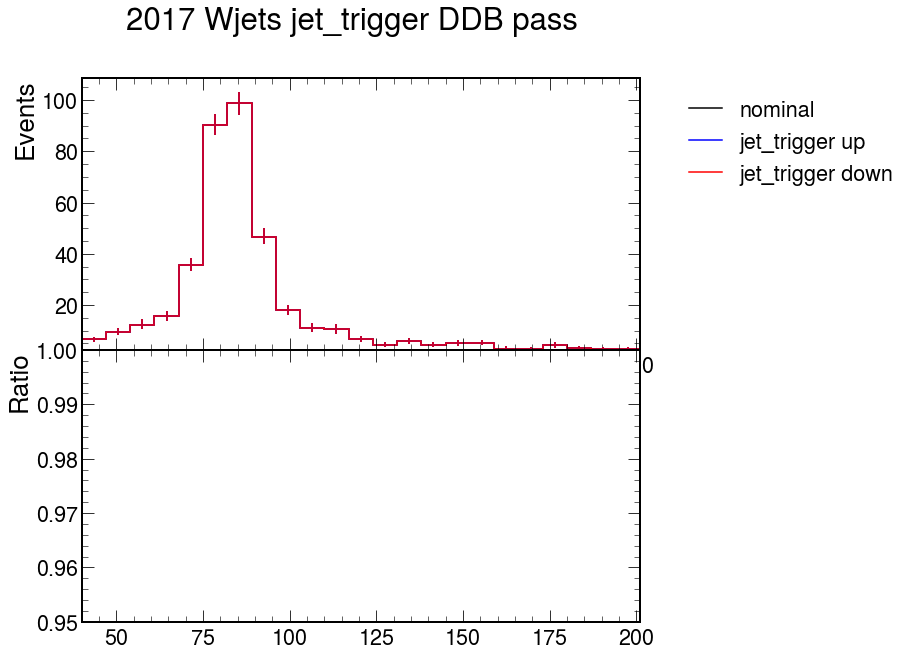

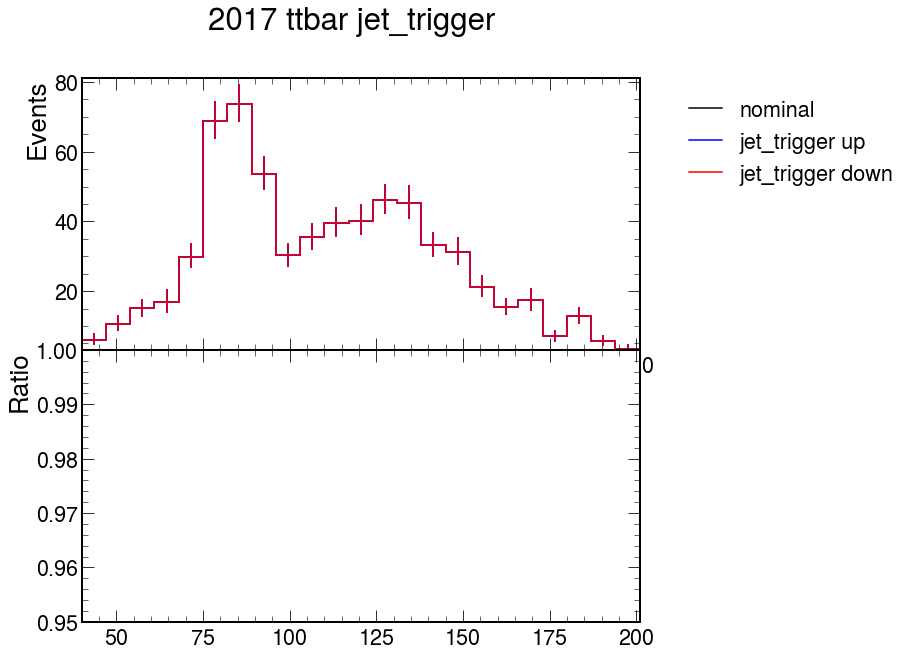

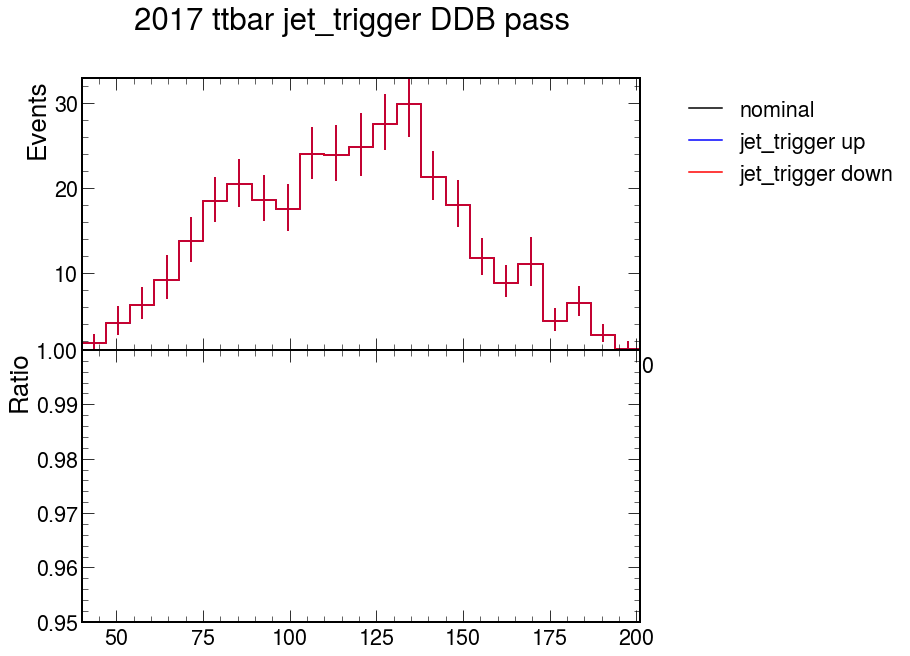

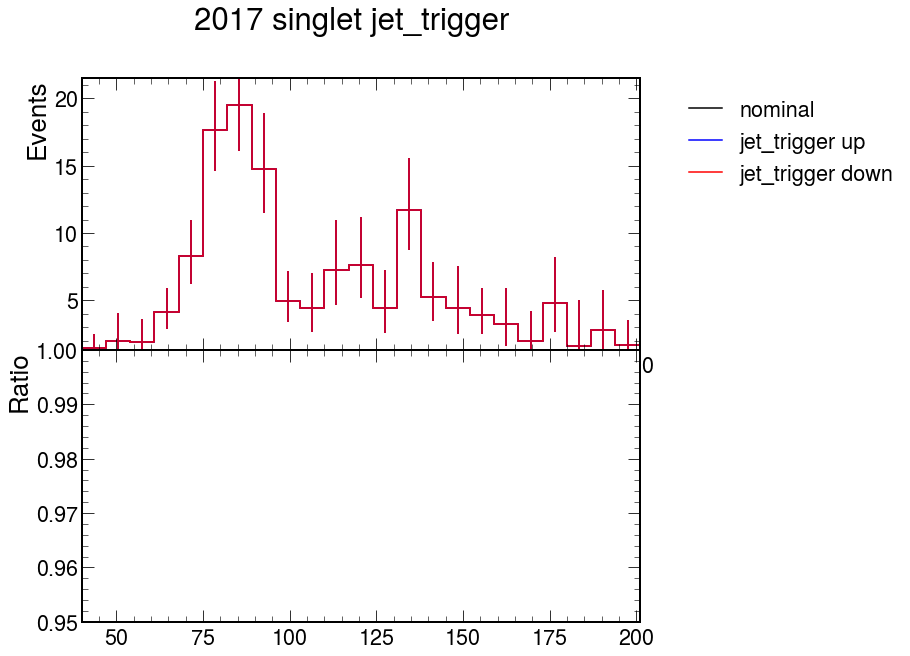

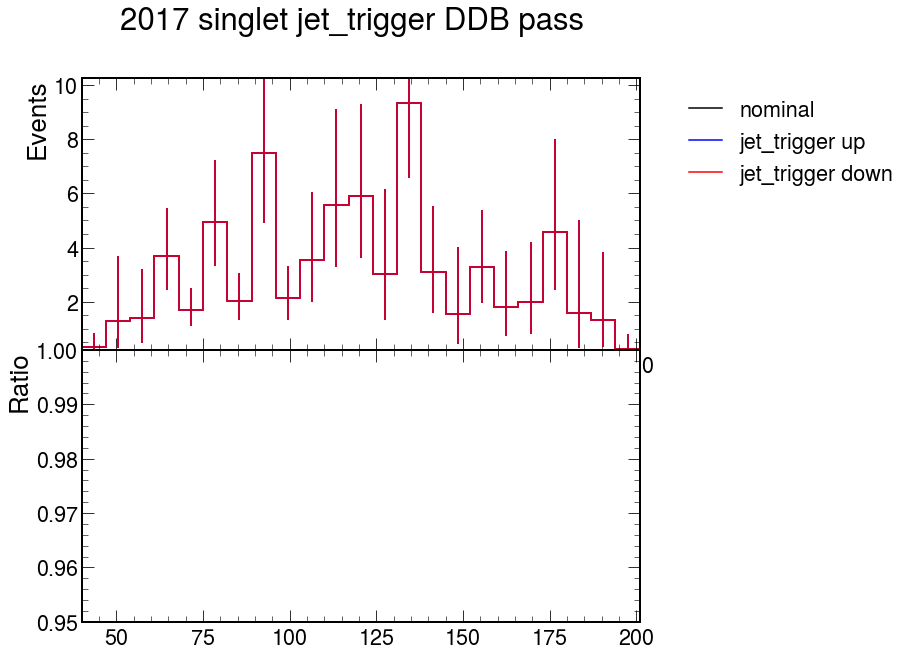

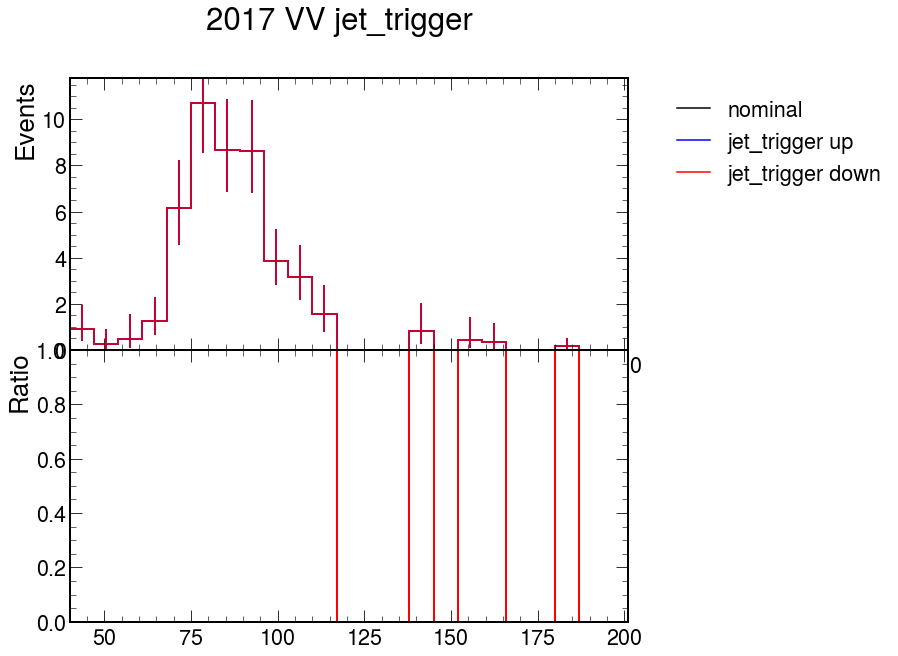

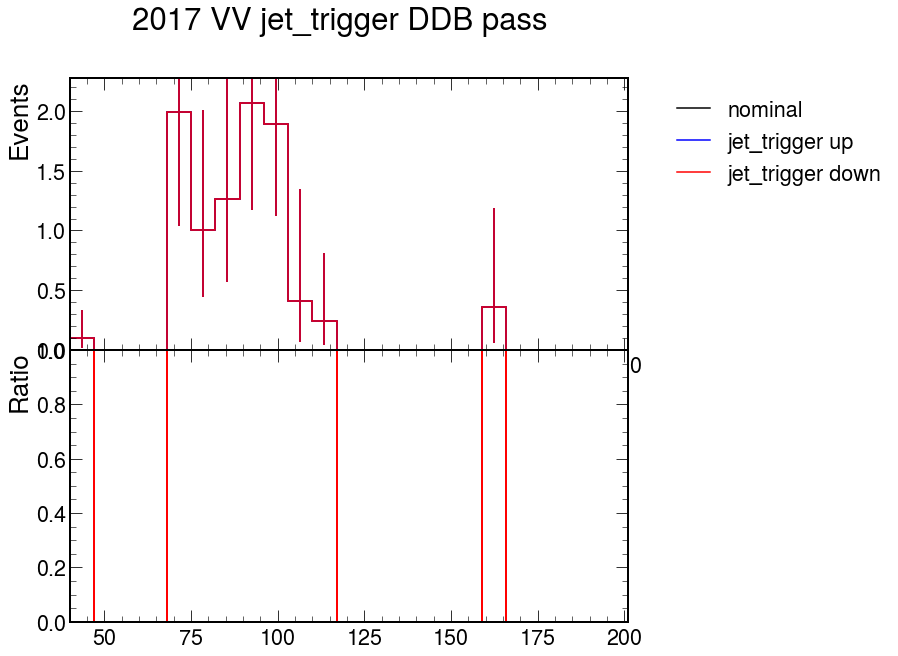

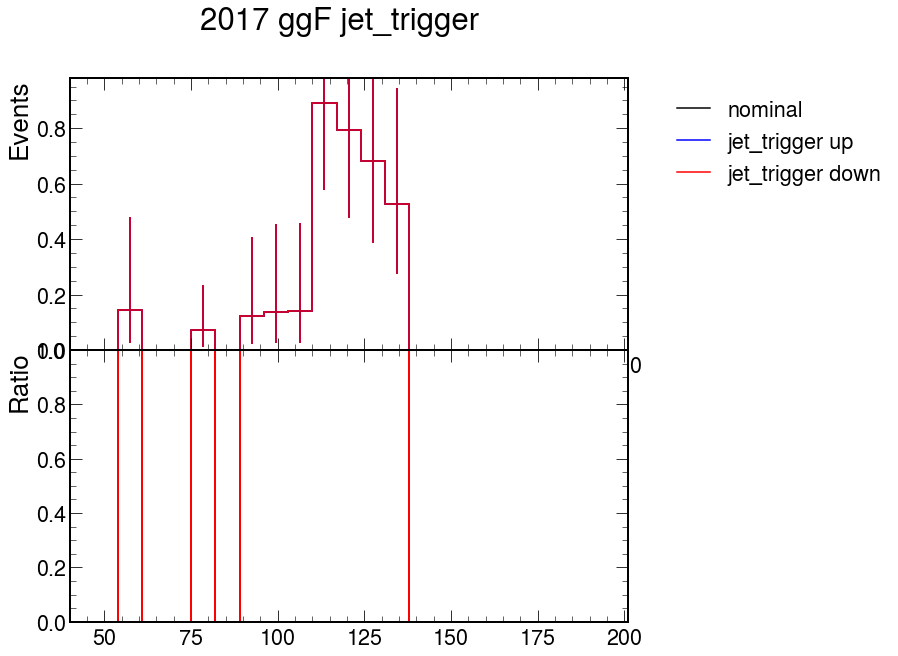

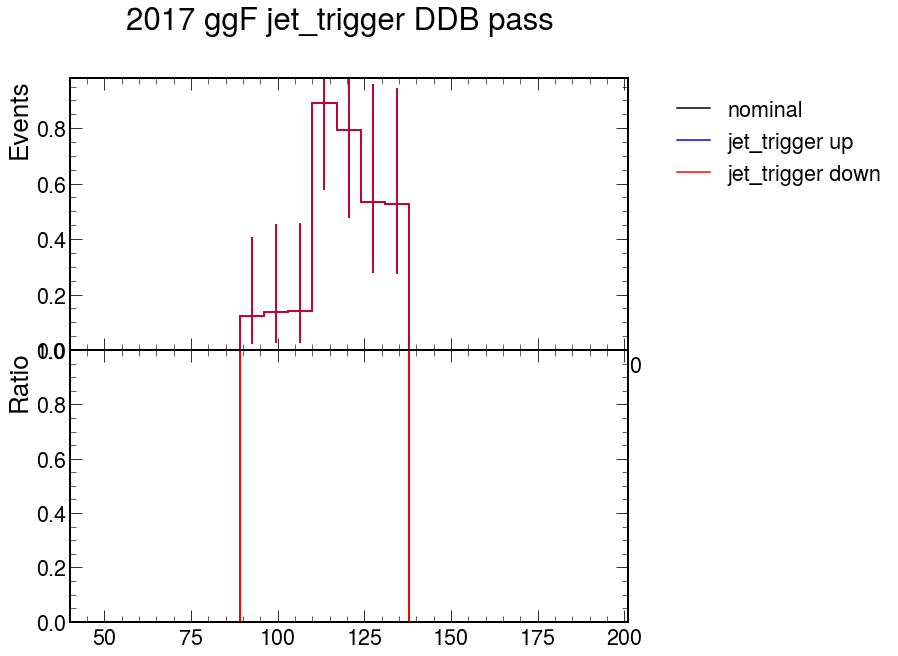

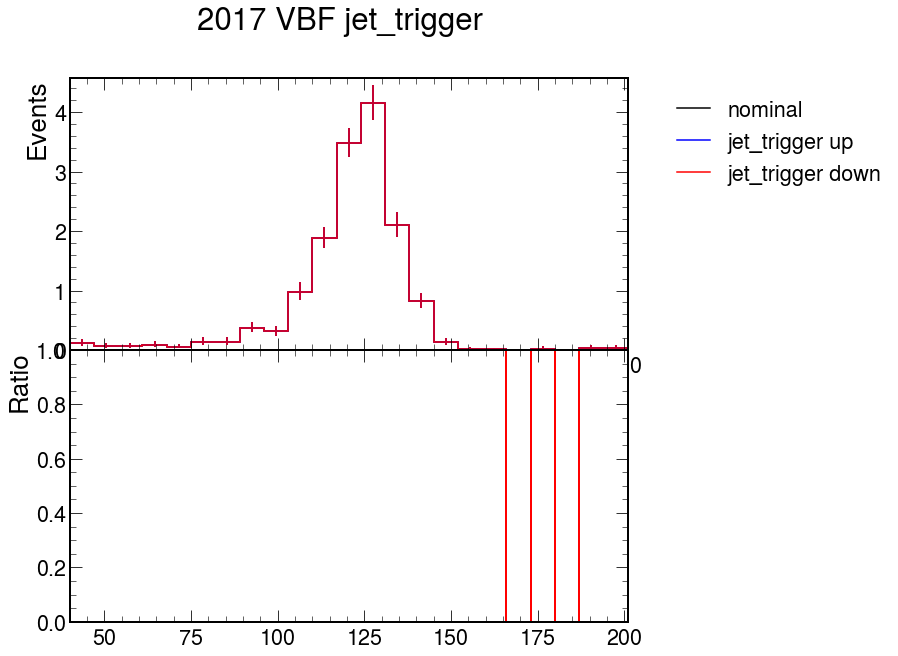

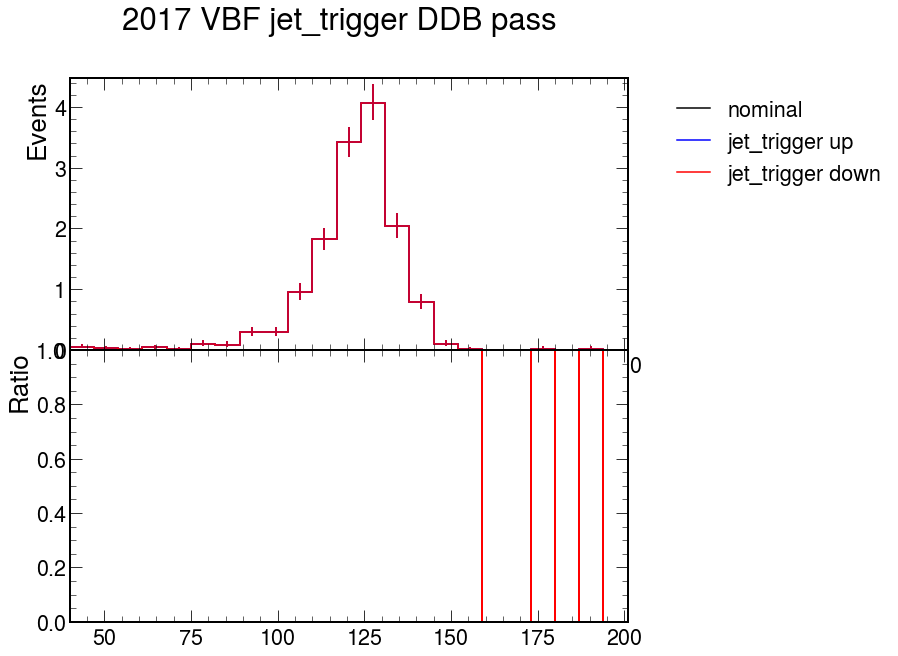

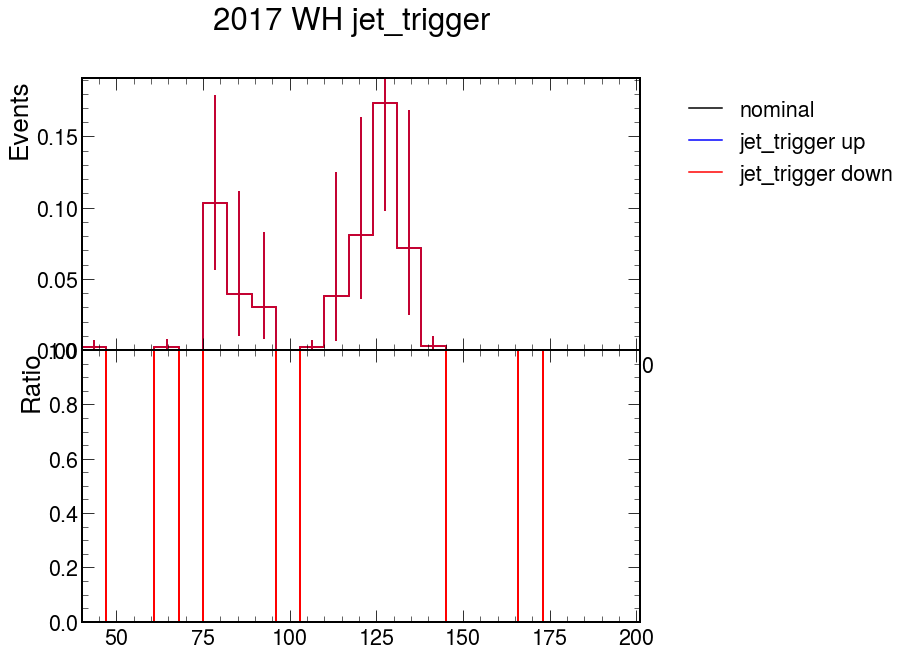

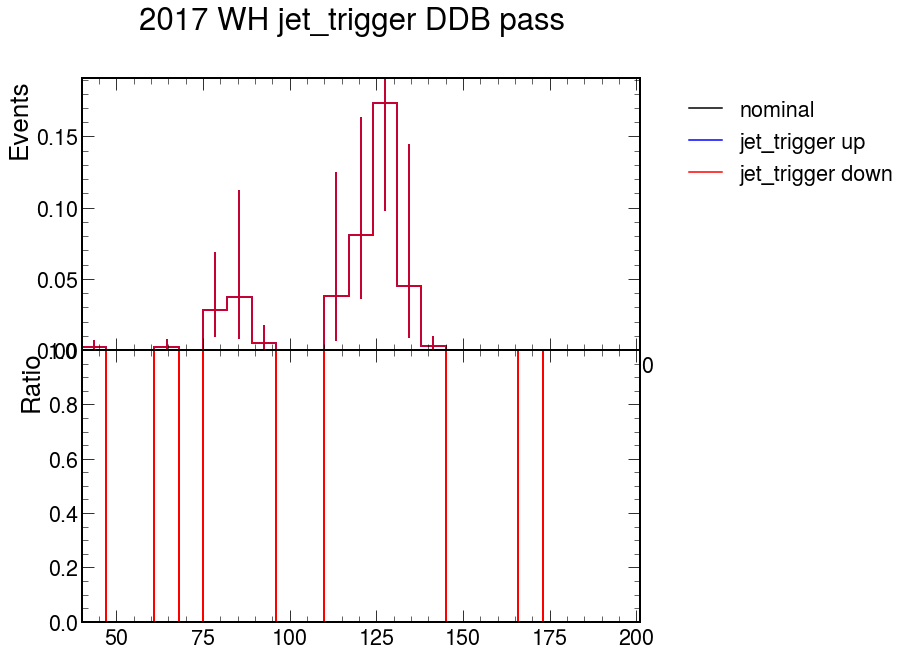

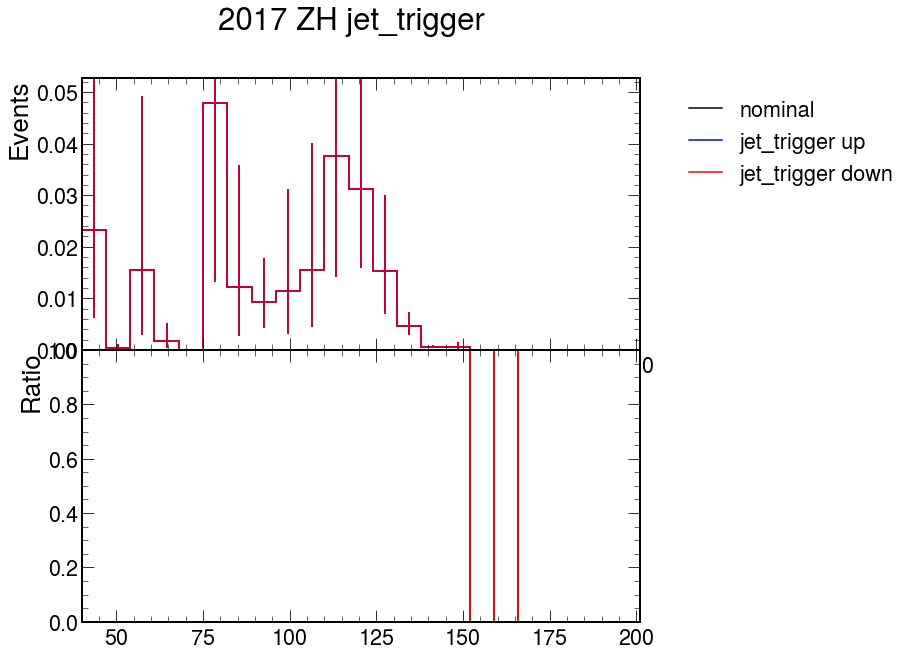

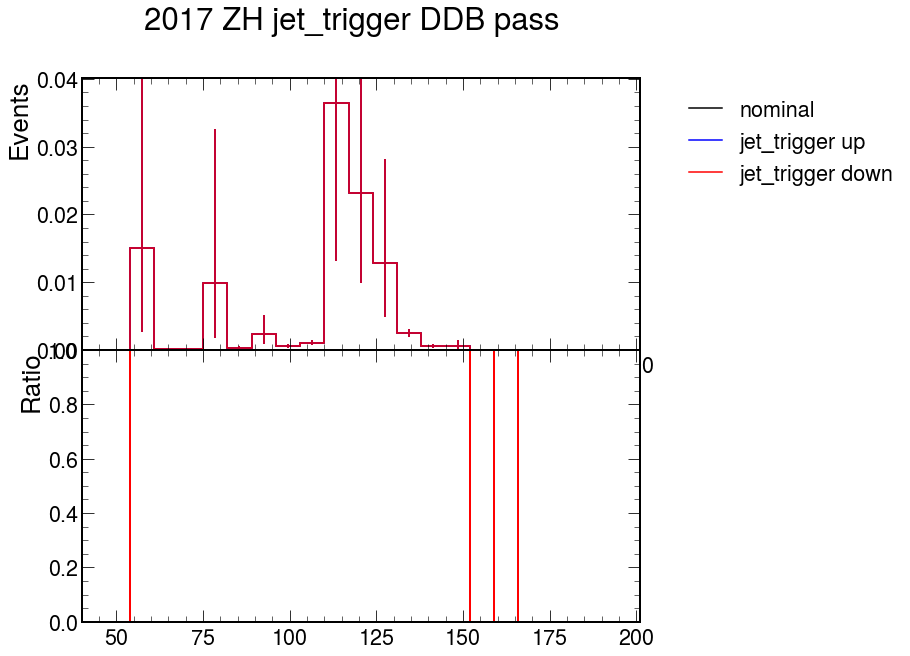

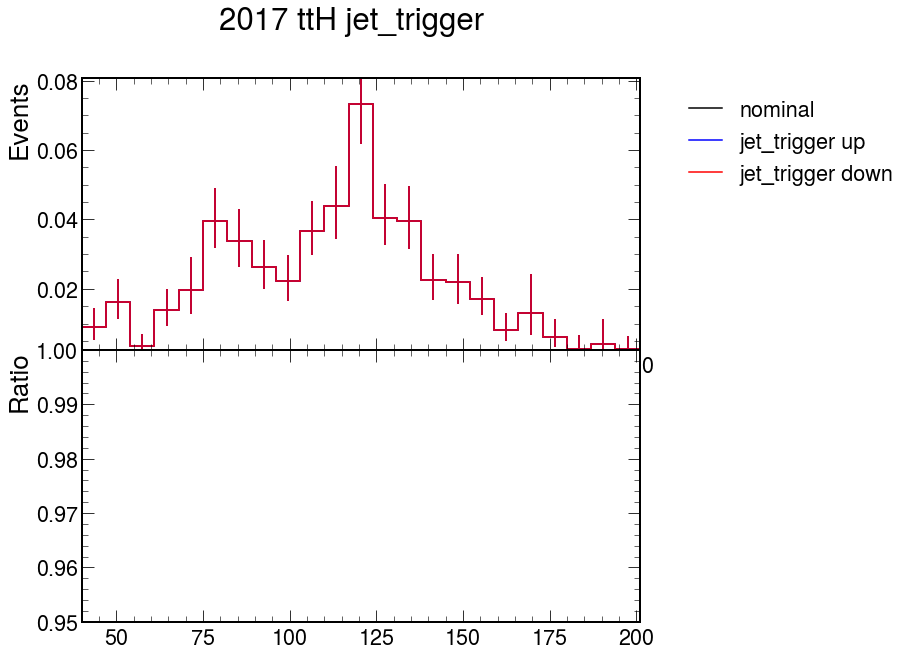

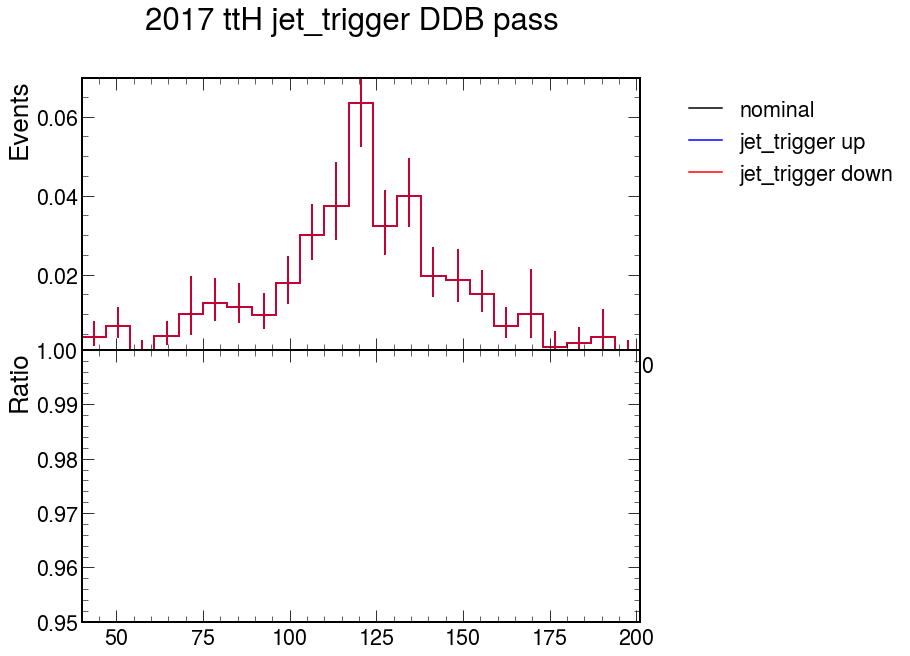

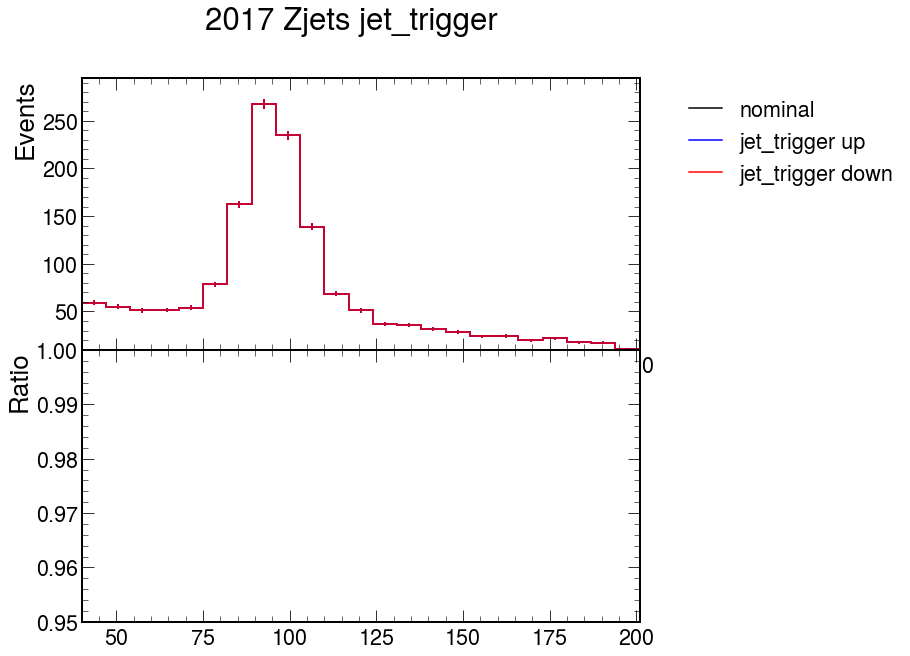

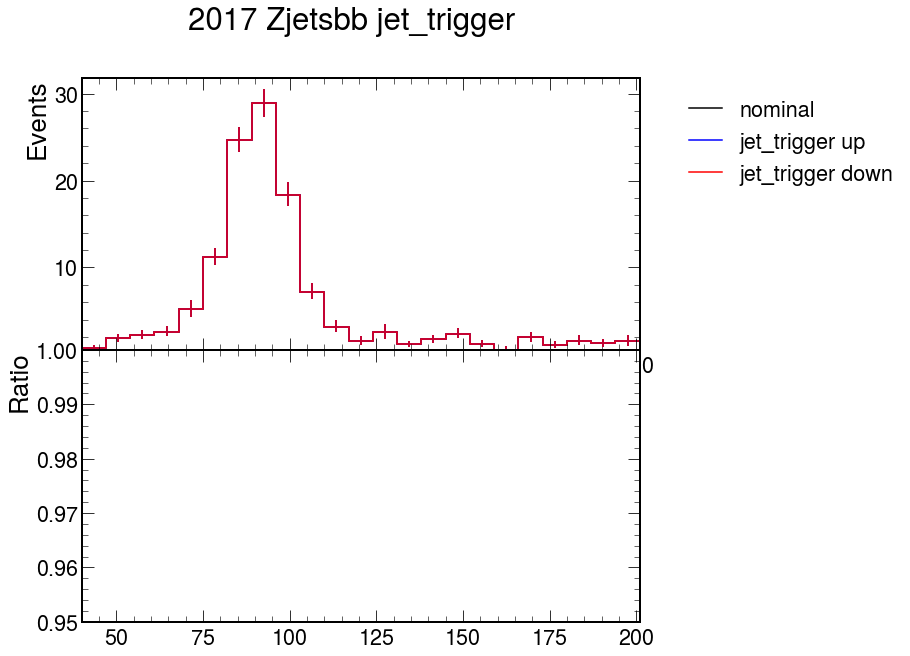

In [29]:
s = 'jet_trigger'

for p in mc:
    plot_syst(h.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s,year+'/syst_'+s+'/'+p)
    plot_syst(g.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s+' DDB pass',year+'/syst_'+s+'/'+p+"_pass")
    
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(0,3)),s,year+' Zjets '+s,year+'/syst_'+s+'/Zjets')
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(3,4)),s,year+' Zjetsbb '+s,year+'/syst_'+s+'/Zjetsbb')

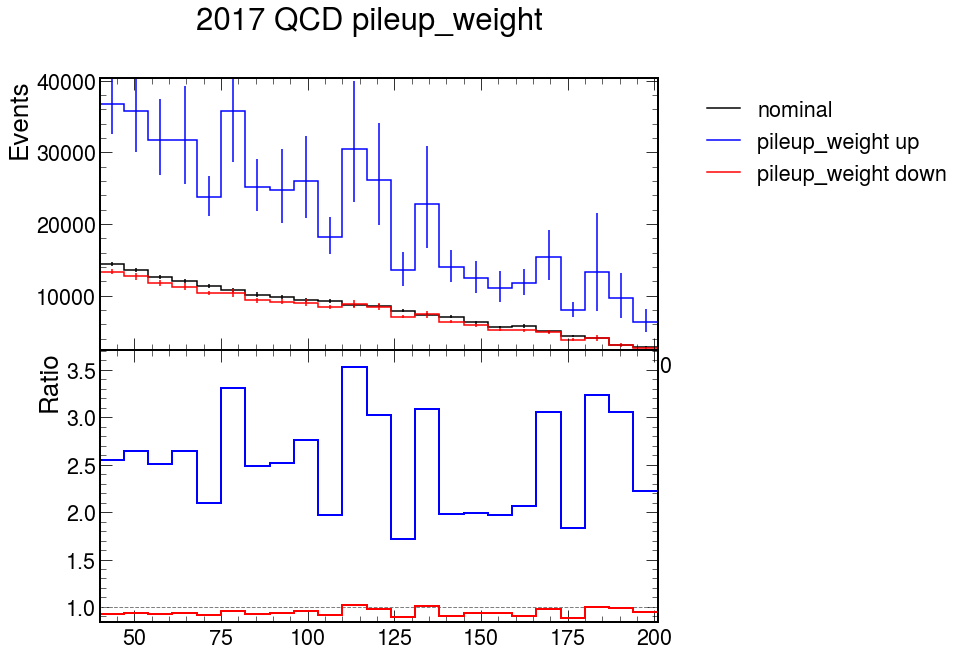

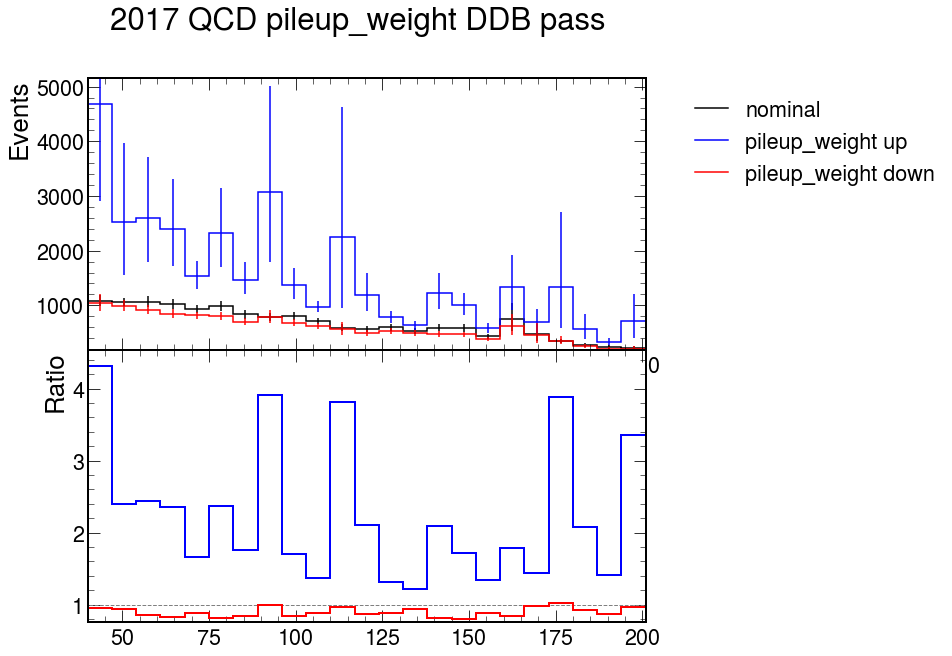

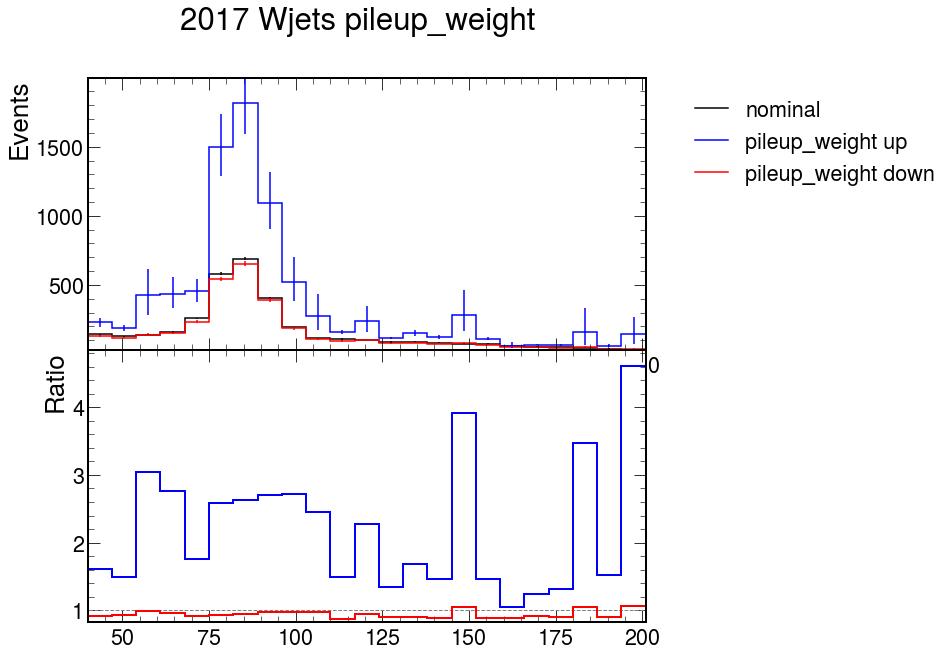

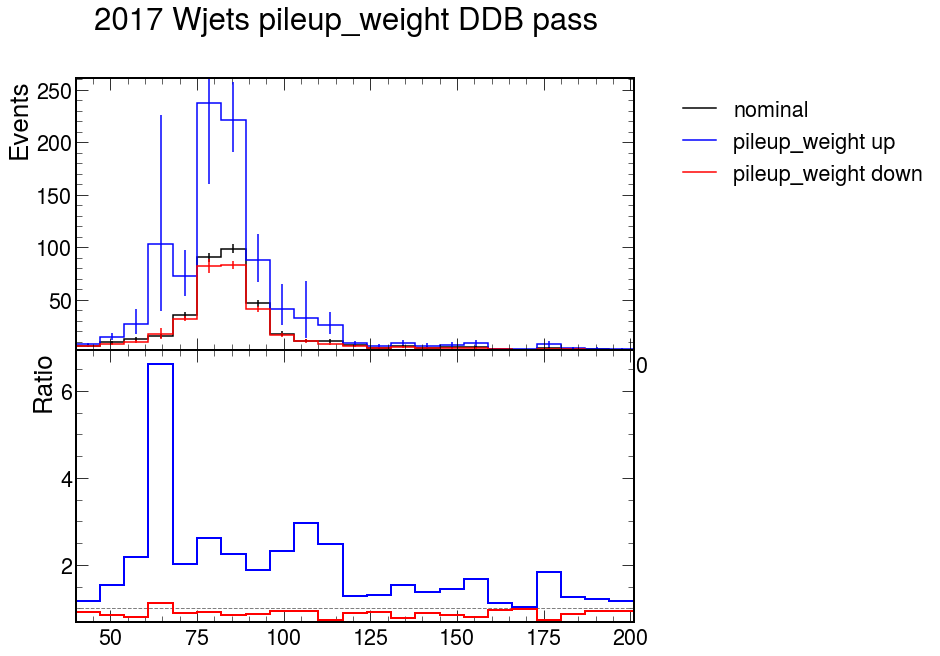

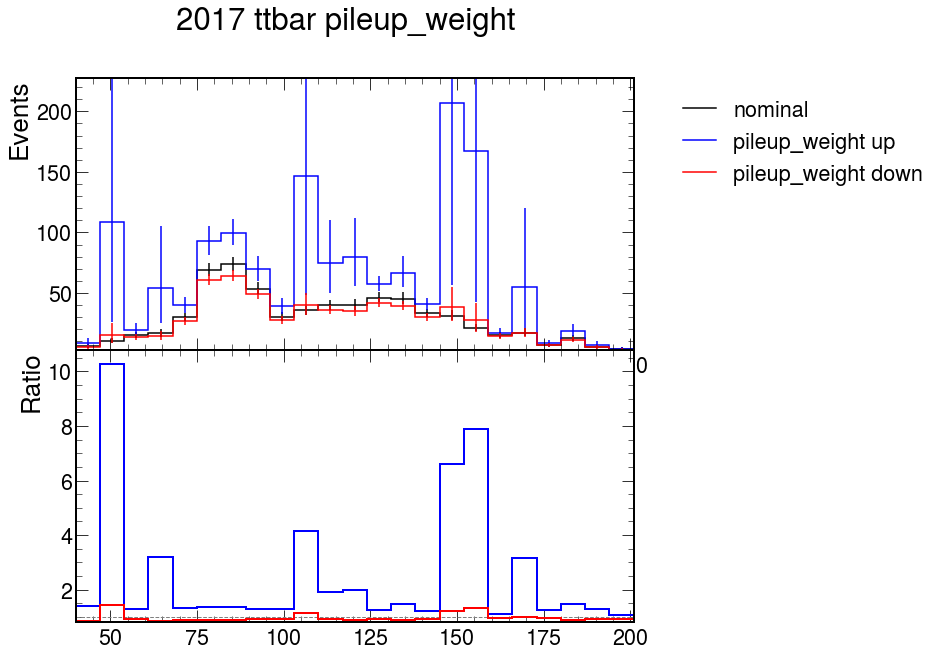

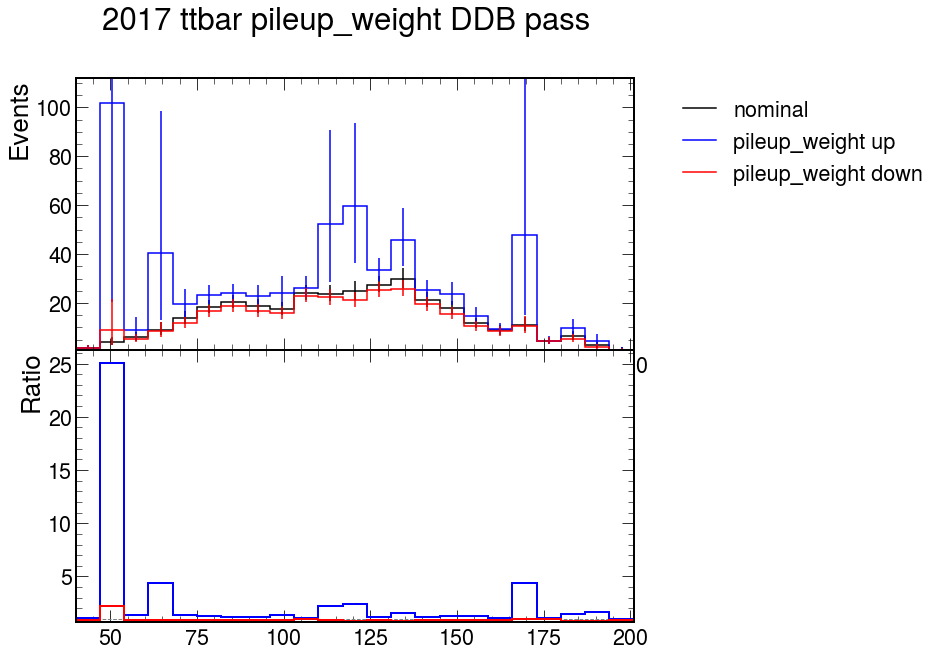

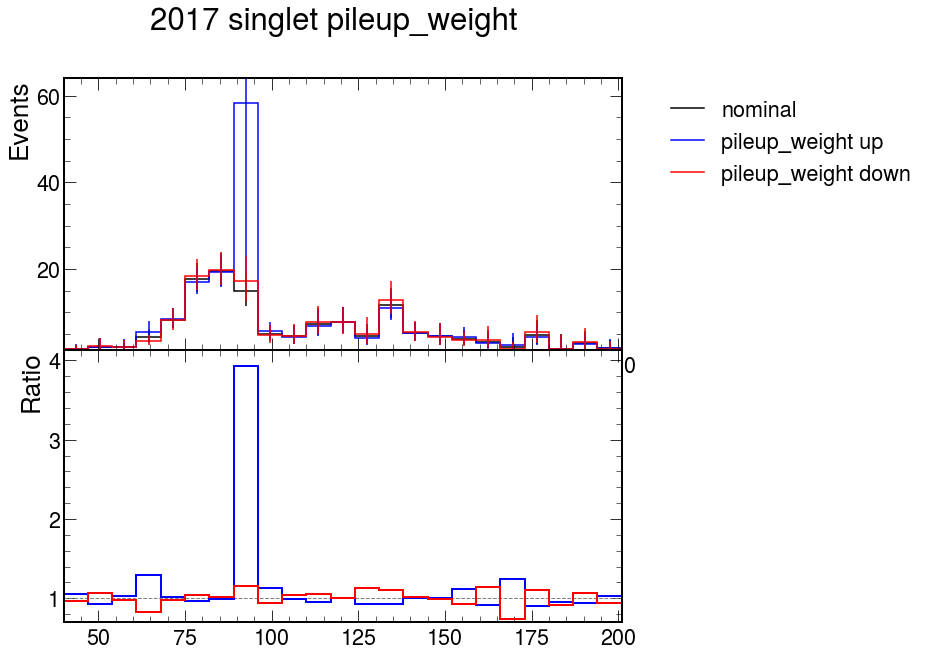

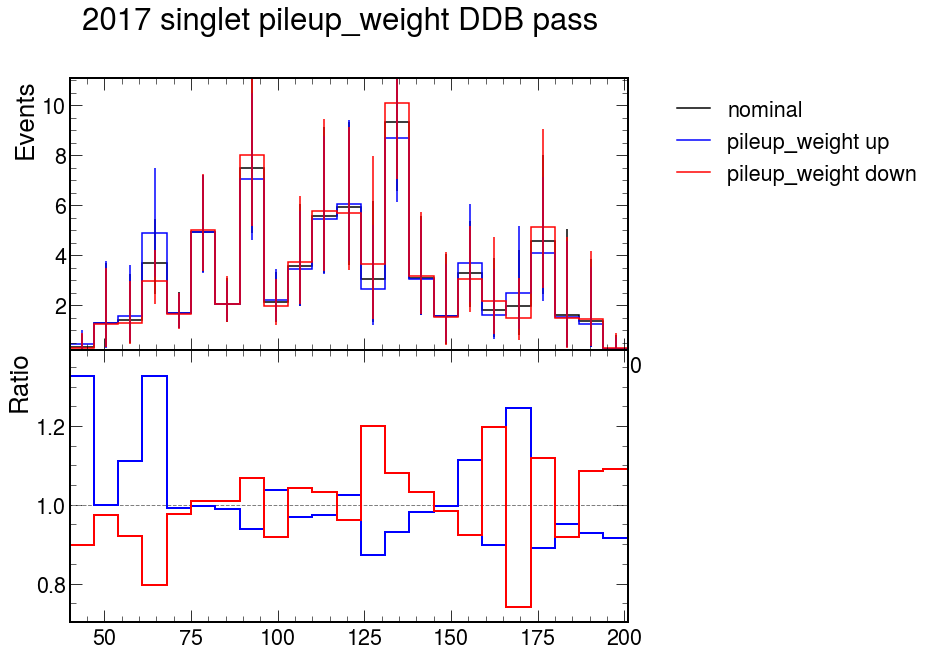

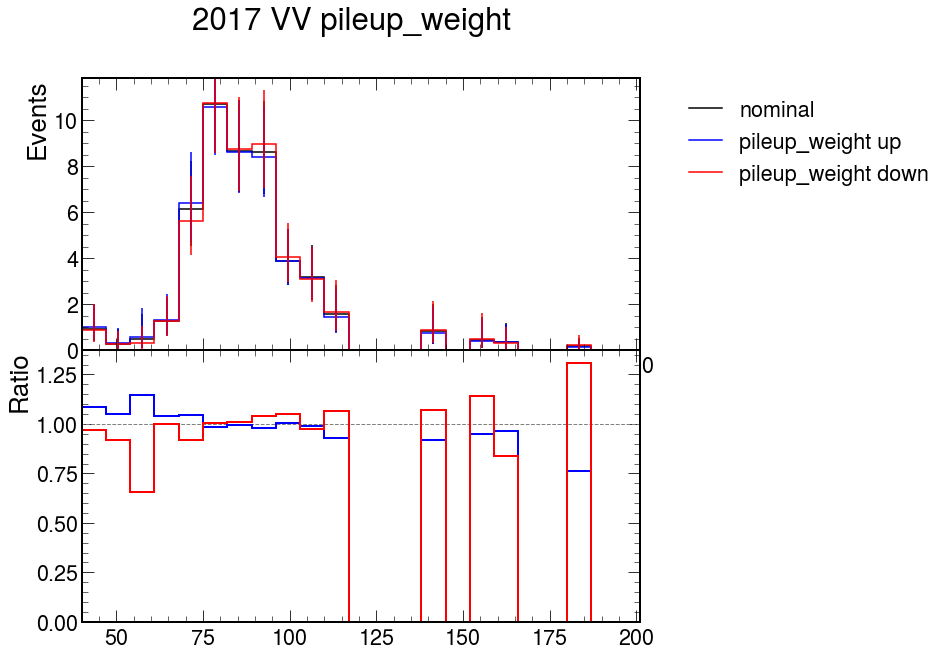

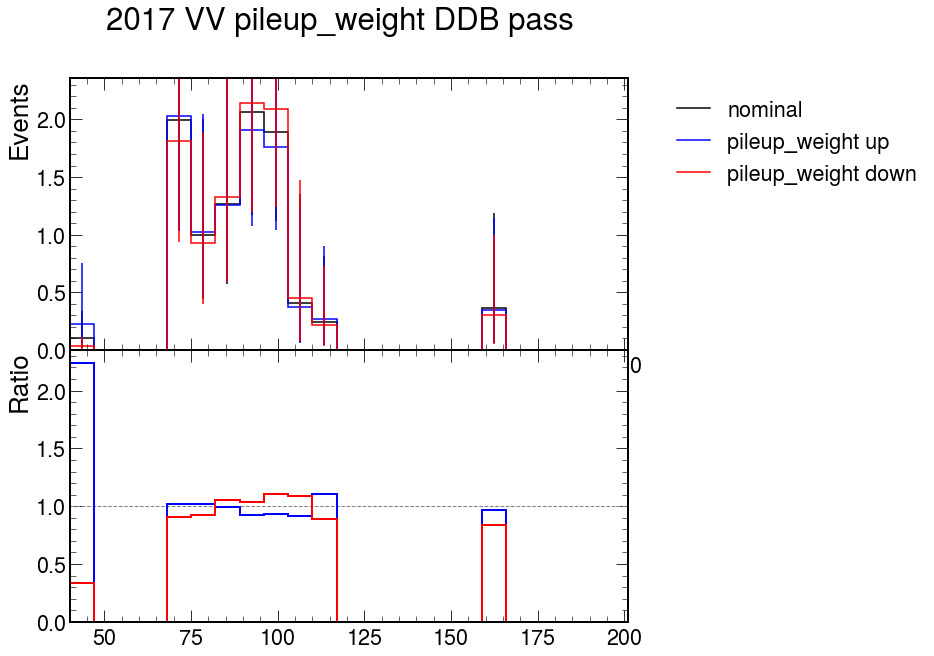

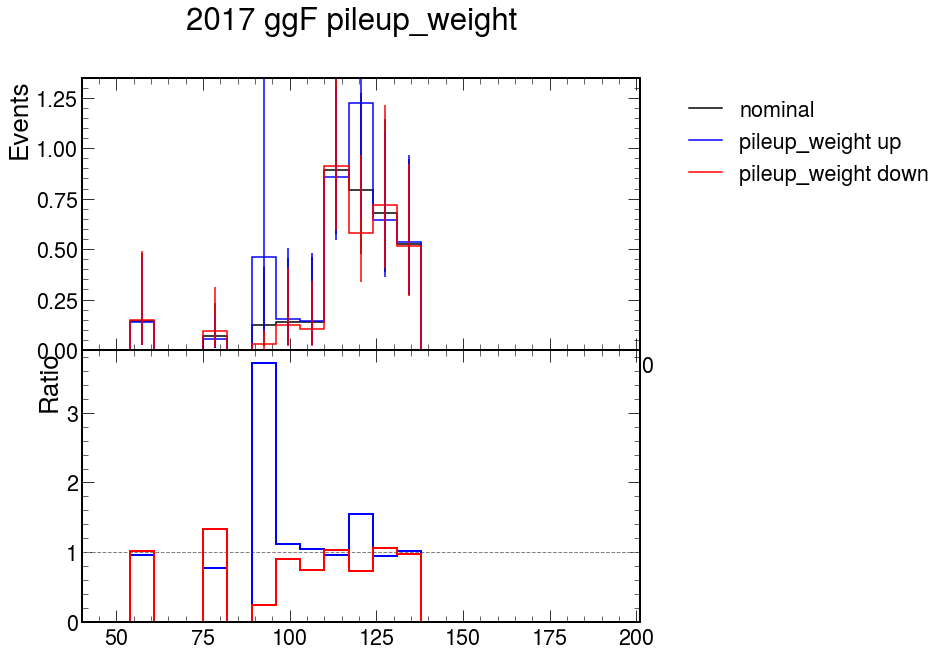

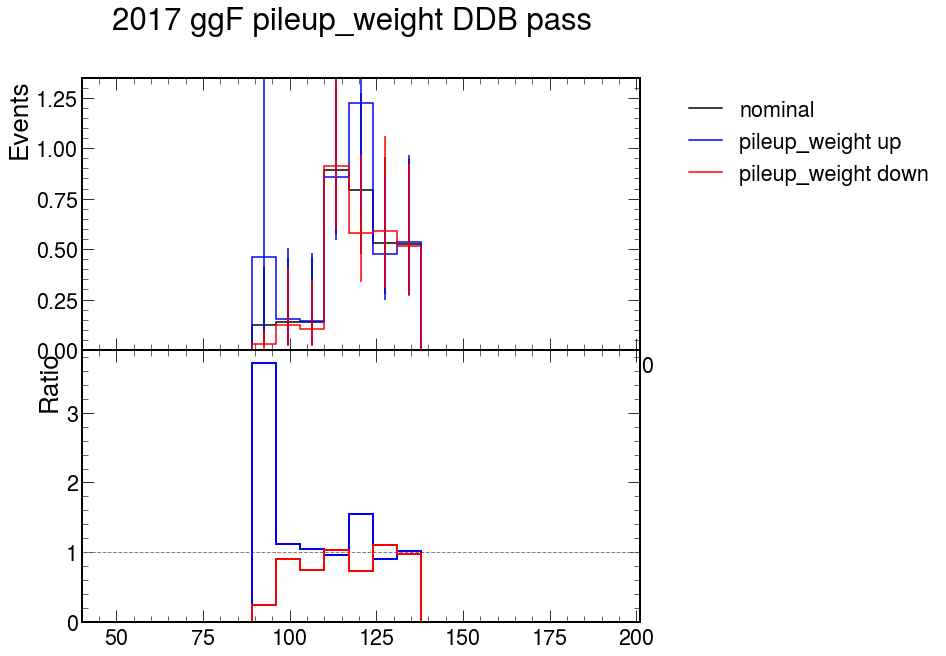

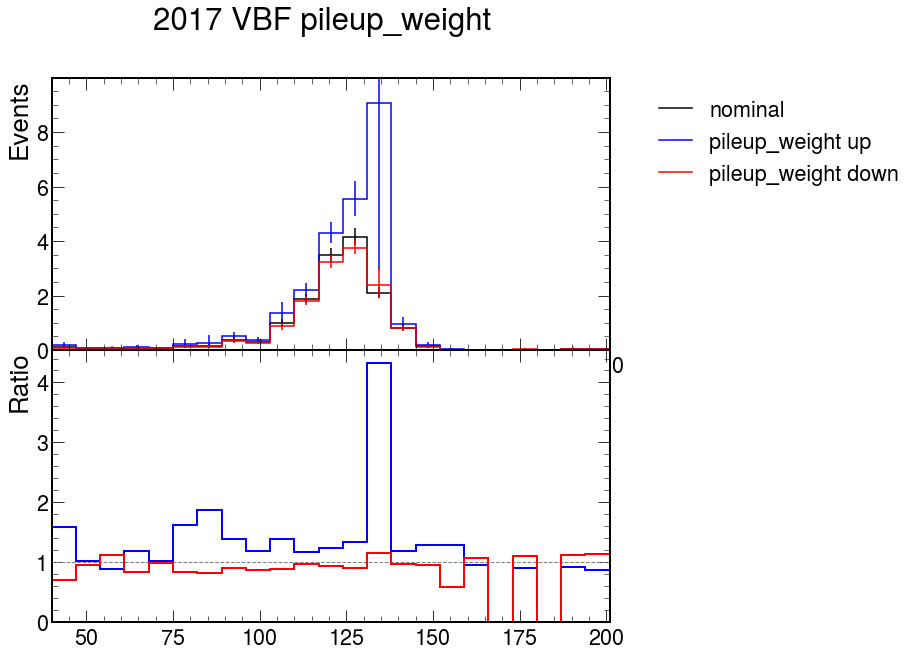

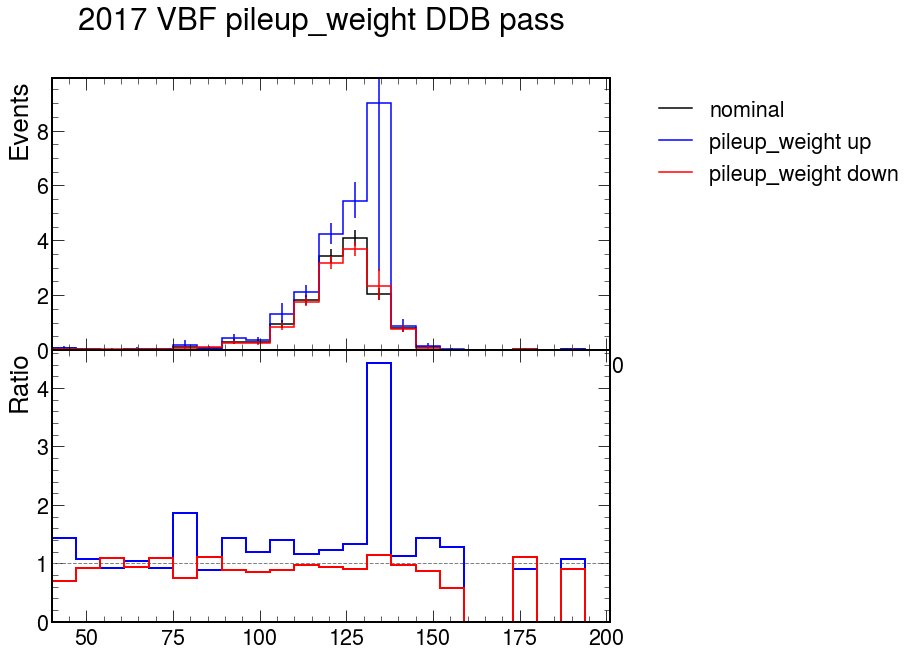

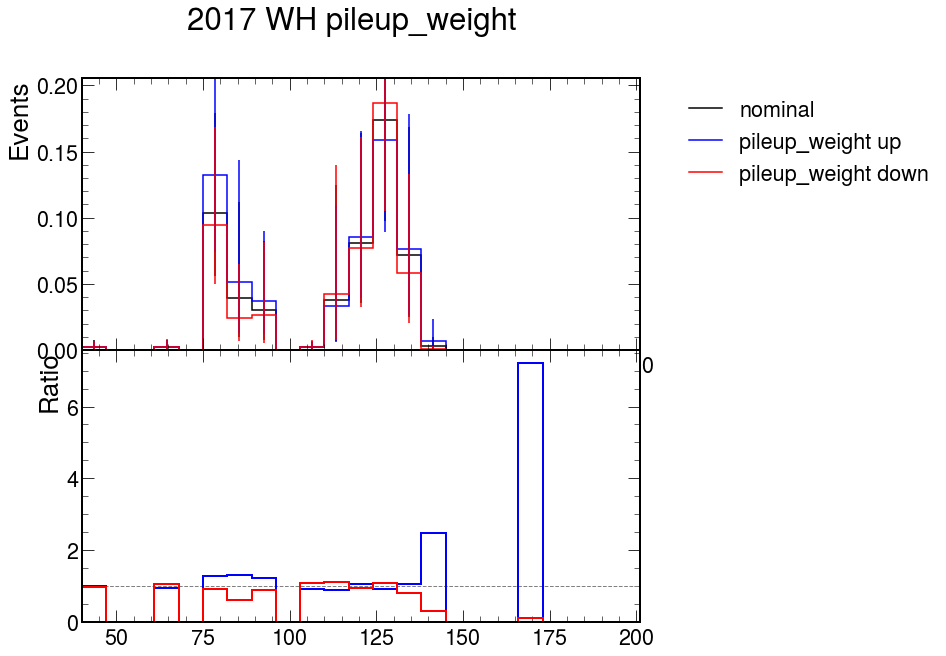

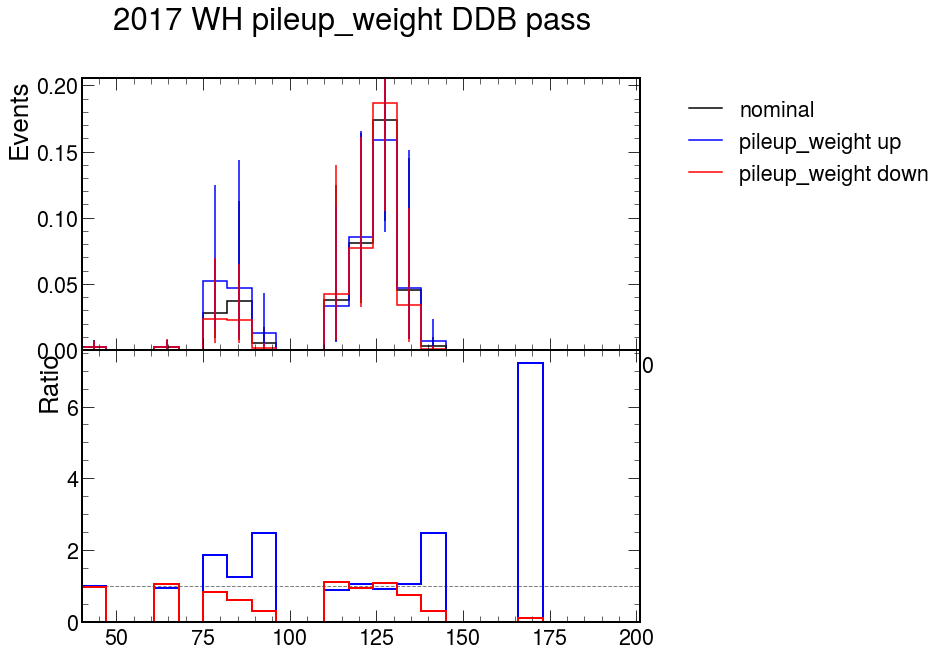

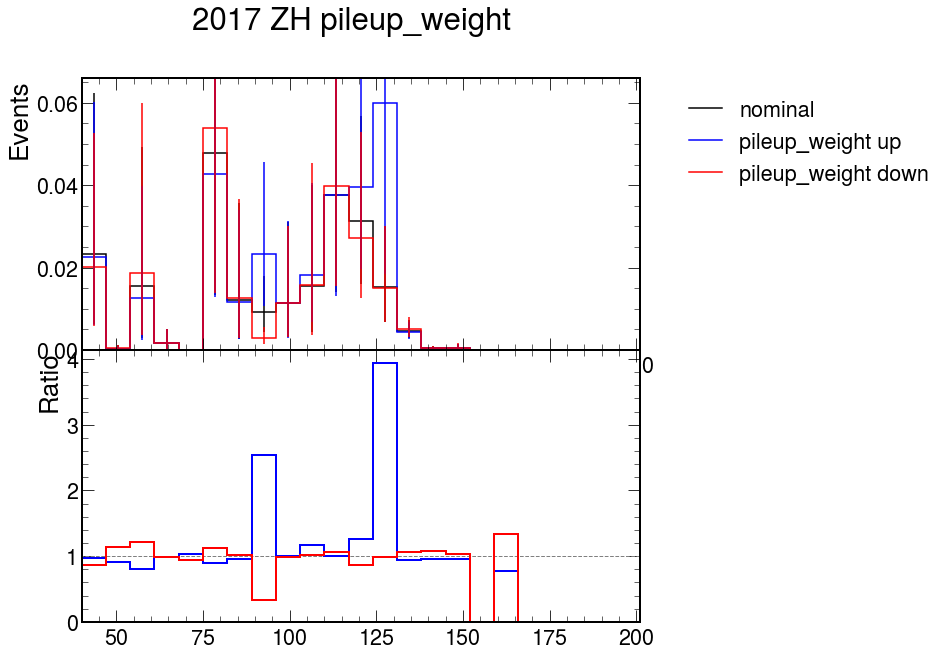

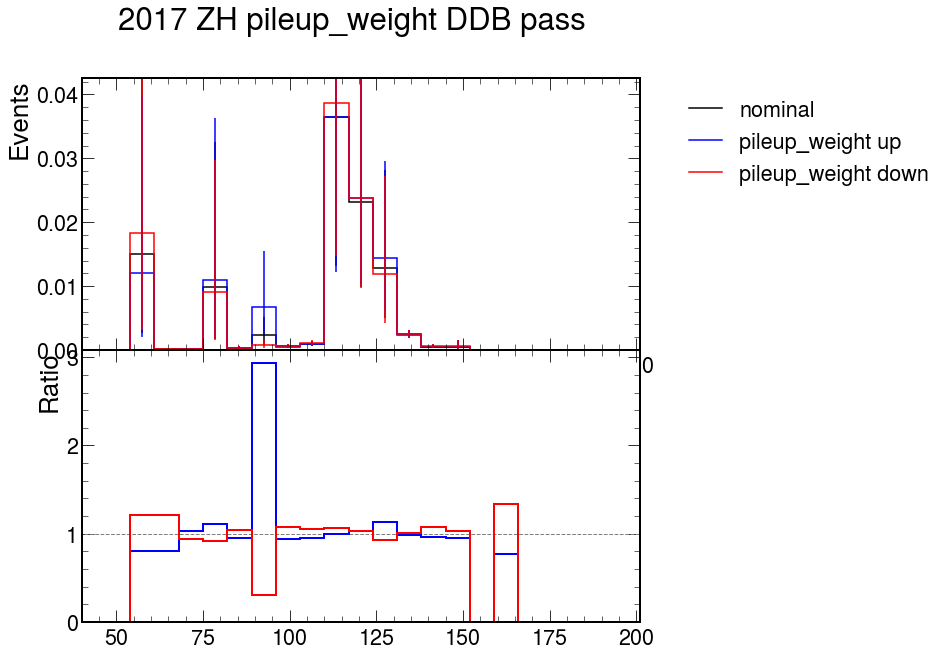

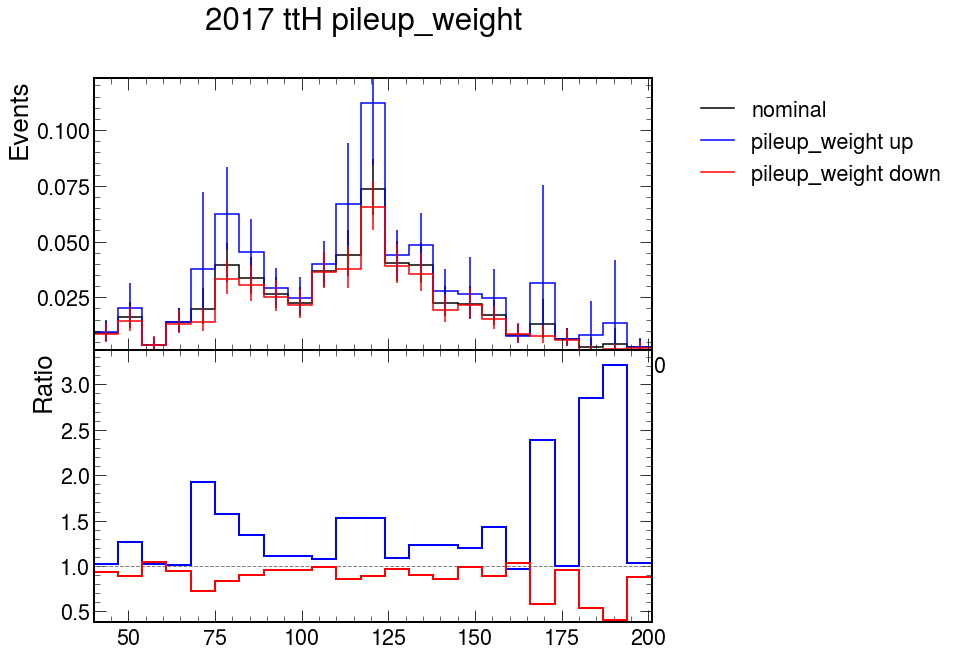

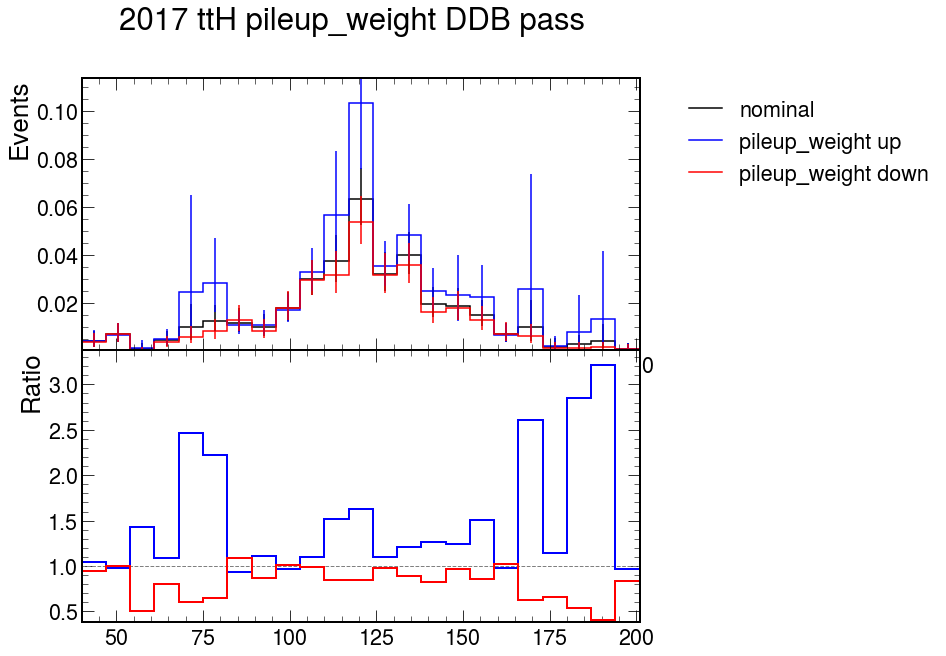

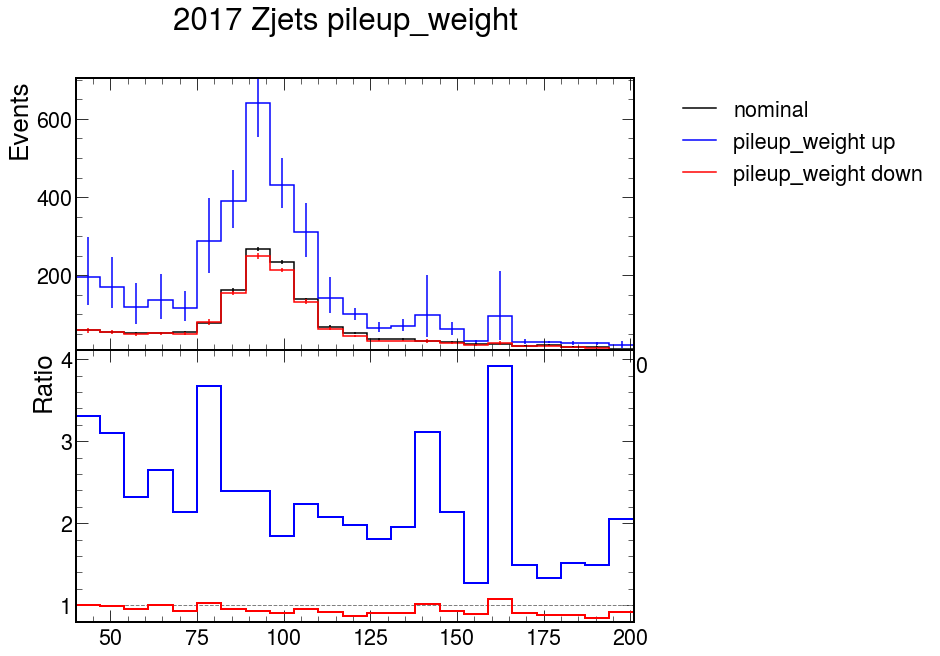

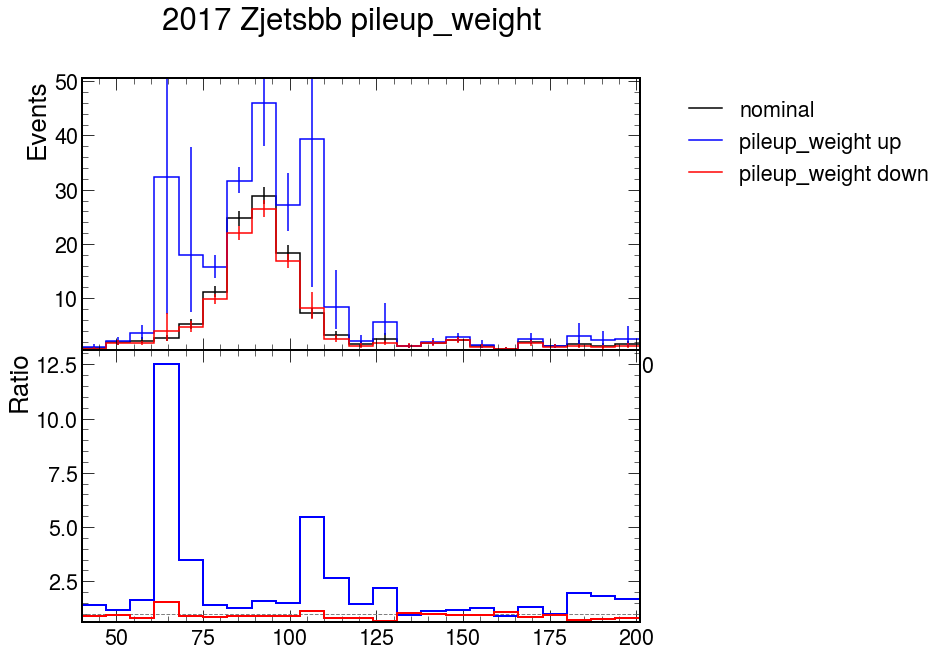

In [30]:
s = 'pileup_weight'

for p in mc:
    plot_syst(h.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s,year+'/syst_'+s+'/'+p)
    plot_syst(g.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s+' DDB pass',year+'/syst_'+s+'/'+p+"_pass")
    
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(0,3)),s,year+' Zjets '+s,year+'/syst_'+s+'/Zjets')
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(3,4)),s,year+' Zjetsbb '+s,year+'/syst_'+s+'/Zjetsbb')